# 06 · Hallmark enrichment and donor expression

Attach the Stage 04 filtered pseudobulk checkpoint and the Stage 05 output. Rank tested Ensembl genes by signed square root of the edgeR quasi-likelihood F statistic. Test Hallmark gene sets and examine leading-edge evidence within the eight donor pairs. Condition and pooled capture are confounded, and enrichment measures patterns in the transcriptomic ranking.


## 1. Verify the Stage 05 checkpoint


In [1]:

from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd

# -------------------------------------------
# 1. Locate the verified Stage 05 output
# -------------------------------------------

input_root = Path("/kaggle/input")

manifest_paths = sorted(
    input_root.rglob("stage05_final_checkpoint.json")
)

assert len(manifest_paths) == 1, (
    f"Expected one Stage 05 manifest; "
    f"found {len(manifest_paths)}"
)

manifest_path = manifest_paths[0]
STAGE05_ROOT = manifest_path.parents[2]

manifest = json.loads(
    manifest_path.read_text(encoding="utf-8")
)

primary = manifest["primary_analysis"]

# -------------------------------------------
# 2. Verify experimental design
# -------------------------------------------

assert manifest["checkpoint"] == "PASS"

assert primary["design"] == "~ donor_id + condition"
assert primary["contrast"] == "stim_vs_ctrl"

assert (
    primary["paired_donors"],
    primary["samples"],
    primary["genes_tested"],
) == (8, 16, 3697)

# -------------------------------------------
# 3. Locate and verify the DE table
# -------------------------------------------

de_record = manifest["artifacts"][
    "primary_de_results"
]

de_path = (
    manifest_path.parents[1]
    / "de"
    / de_record["filename"]
)

assert de_path.is_file()

assert (
    de_path.stat().st_size
    == de_record["file_size_bytes"]
)

with de_path.open("rb") as stream:
    observed_sha = hashlib.file_digest(
        stream, "sha256"
    ).hexdigest()

assert observed_sha == de_record["sha256"]

# -------------------------------------------
# 4. Load and validate numerical results
# -------------------------------------------

de = pd.read_csv(
    de_path,
    sep="\t",
    dtype={"gene_id": "string"},
)

assert de.columns.tolist() == [
    "gene_id",
    "logFC",
    "logCPM",
    "F",
    "PValue",
    "FDR",
]

assert len(de) == 3697
assert de["gene_id"].is_unique

assert de["gene_id"].str.fullmatch(
    r"ENSG[0-9]+", na=False
).all()

numeric_cols = [
    "logFC", "logCPM", "F", "PValue", "FDR"
]

assert np.isfinite(
    de[numeric_cols].to_numpy(dtype=float)
).all()

assert de["F"].ge(0).all()
assert de["PValue"].between(0, 1).all()
assert de["FDR"].between(0, 1).all()

# -------------------------------------------
# 5. Verify previous DE checkpoint
# -------------------------------------------

sig = de["FDR"] < 0.05

assert int(sig.sum()) == 2502

assert int(
    (sig & (de["logFC"] > 0)).sum()
) == 1250

assert int(
    (sig & (de["logFC"] < 0)).sum()
) == 1252

# -------------------------------------------
# 6. Report validated inputs
# -------------------------------------------

print("DE file:", de_path)
print("SHA-256:", observed_sha)
print("Genes tested:", len(de))
print("Genes at FDR < 0.05:", int(sig.sum()))
print("Missing or nonfinite numeric values: 0")
print("Duplicate Ensembl IDs: 0")

print("\nSTAGE 06 INPUT VALIDATION: PASS")


DE file: /kaggle/input/notebooks/tthanhh811/05-ifnb-paired-de/kang_ifnb/results/de/stage05_paired_qlf_all_genes.tsv
SHA-256: 48e26a2dc3a08b4273eb4636696ac372a672e14329aa9e1c7c92c756f6813a1f
Genes tested: 3697
Genes at FDR < 0.05: 2502
Missing or nonfinite numeric values: 0
Duplicate Ensembl IDs: 0

STAGE 06 INPUT VALIDATION: PASS


## 2. Gene ranking for preranked GSEA

Rank all 3,697 tested Ensembl genes by sign(log₂ fold change) × √F. The R model supplies F, and the fold-change sign gives direction.


In [2]:

import sys

from IPython.display import display

# -------------------------------------------
# 1. Calculate signed ranking statistics
# -------------------------------------------

ranked = de.assign(
    rank_score=(
        np.sign(de["logFC"])
        * np.sqrt(de["F"])
    )
)

assert len(ranked) == 3697

assert np.isfinite(
    ranked["rank_score"].to_numpy()
).all()

# -------------------------------------------
# 2. Check ranking ties and zero scores
# -------------------------------------------

n_ties = int(
    ranked["rank_score"]
    .duplicated(keep=False)
    .sum()
)

n_zero = int(
    ranked["rank_score"].eq(0).sum()
)

print("Genes ranked:", len(ranked))
print("Genes with tied scores:", n_ties)
print("Genes with zero scores:", n_zero)

# -------------------------------------------
# 3. Sort genes by descending rank score
# -------------------------------------------

ranked = ranked.sort_values(
    ["rank_score", "gene_id"],
    ascending=[False, True],
)

assert ranked["rank_score"].is_monotonic_decreasing

# -------------------------------------------
# 4. Export the ranked list
# -------------------------------------------

rank_dir = Path(
    "/kaggle/working/kang_ifnb/results/pathway"
)

rank_dir.mkdir(
    parents=True,
    exist_ok=True,
)

rank_path = (
    rank_dir / "stage06_primary_ranked_genes.tsv"
)

ranked[
    [
        "gene_id",
        "rank_score",
        "logFC",
        "F",
        "PValue",
        "FDR",
    ]
].to_csv(
    rank_path,
    sep="\t",
    index=False,
    float_format="%.17g",
)

# -------------------------------------------
# 5. Calculate the output checksum
# -------------------------------------------

with rank_path.open("rb") as stream:
    rank_sha = hashlib.file_digest(
        stream, "sha256"
    ).hexdigest()

# Check against the original notebook result
EXPECTED_RANK_SHA = (
    "45a918679fd214ab56a82d4541147a9118bfe9728"
    "eed9063b53fde17b524f365"
)

assert rank_sha == EXPECTED_RANK_SHA, (
    "Ranked file differs from original checkpoint"
)

# -------------------------------------------
# 6. Save ranking provenance
# -------------------------------------------

rank_audit = {
    "checkpoint": "PASS",
    "source_notebook": "tthanhh811/05-ifnb-paired-de",
    "source_de_sha256": observed_sha,
    "contrast": primary["contrast"],
    "ranking": "sign(logFC) * sqrt(F)",
    "gene_identifier": "Ensembl gene ID",
    "n_ranked_genes": len(ranked),
    "n_genes_with_tied_score": n_ties,
    "n_zero_scores": n_zero,
    "tie_break": "gene_id ascending for export only",
    "rank_sha256": rank_sha,
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
}

audit_path = (
    rank_dir / "stage06_rank_input_audit.json"
)

audit_path.write_text(
    json.dumps(rank_audit, indent=2) + "\n",
    encoding="utf-8",
)

# -------------------------------------------
# 7. Display results for inspection
# -------------------------------------------

print("\nTop 5 ranked genes:")
display(
    ranked[
        ["gene_id", "logFC", "F", "rank_score"]
    ].head()
)

print("\nBottom 5 ranked genes:")
display(
    ranked[
        ["gene_id", "logFC", "F", "rank_score"]
    ].tail()
)

print("\nRank file SHA-256:", rank_sha)
print("Ranked file:", rank_path)

print("\nSTAGE 06 RANK INPUT CHECKPOINT: PASS")


Genes ranked: 3697
Genes with tied scores: 0
Genes with zero scores: 0

Top 5 ranked genes:


,gene_id,logFC,F,rank_score
1384,ENSG00000122643,5.780556,1450.072771,38.079821
1337,ENSG00000146425,2.714465,1083.025506,32.909353
563,ENSG00000138385,3.384988,988.257308,31.436560
2819,ENSG00000185338,4.360672,987.760882,31.428663
490,ENSG00000034510,2.189479,987.659359,31.427048



Bottom 5 ranked genes:


,gene_id,logFC,F,rank_score
1728,ENSG00000147604,-1.312161,508.418707,-22.548142
1035,ENSG00000038427,-4.419992,541.916185,-23.279093
1510,ENSG00000258227,-4.727251,666.382274,-25.814381
2451,ENSG00000089009,-1.723222,739.040833,-27.185305
3356,ENSG00000183019,-4.830384,845.430460,-29.076287



Rank file SHA-256: 45a918679fd214ab56a82d4541147a9118bfe9728eed9063b53fde17b524f365
Ranked file: /kaggle/working/kang_ifnb/results/pathway/stage06_primary_ranked_genes.tsv

STAGE 06 RANK INPUT CHECKPOINT: PASS


## 3. R environment and package verification

Verify R, Bioconductor, edgeR, fgsea and msigdbr versions.


In [3]:

import os
import subprocess
from pathlib import Path

# -------------------------------------------
# 1. Define the R environment
# -------------------------------------------

r_library = Path(
    "/kaggle/temp/r_libs_pathway"
)

r_library.mkdir(
    parents=True,
    exist_ok=True,
)

env = os.environ.copy()

env["R_LIBS_USER"] = str(r_library)

# Preserve the setting from the original notebook.
env["MSIGDB_CACHE_DIR"] = (
    "/kaggle/temp/msigdb_cache"
)

# -------------------------------------------
# 2. Create the R setup script
# -------------------------------------------

r_setup = r'''
lib <- Sys.getenv("R_LIBS_USER")

stopifnot(nzchar(lib))

dir.create(
    lib,
    recursive = TRUE,
    showWarnings = FALSE
)

.libPaths(c(lib, .libPaths()))

options(
    repos = c(CRAN = "https://cran.r-project.org"),
    timeout = 180
)

# Check a package and its exact version.
package_ok <- function(name, expected) {
    requireNamespace(name, quietly = TRUE) &&
        identical(
            as.character(packageVersion(name)),
            expected
        )
}

# -------------------------------------------
# Install BiocManager only when needed
# -------------------------------------------

if (!requireNamespace("BiocManager", quietly = TRUE)) {
    install.packages(
        "BiocManager",
        lib = lib
    )
}

stopifnot(
    as.character(BiocManager::version()) == "3.23"
)

# -------------------------------------------
# Install the required fgsea version
# -------------------------------------------

if (!package_ok("fgsea", "1.38.0")) {

    BiocManager::install(
        "fgsea",
        version = "3.23",
        ask = FALSE,
        update = FALSE,
        force = TRUE,
        Ncpus = 2,
        lib = lib
    )
}

# -------------------------------------------
# Install the required msigdbr version
# -------------------------------------------

if (!package_ok("msigdbr", "26.1.1")) {

    install.packages(
        "msigdbr",
        lib = lib,
        Ncpus = 2
    )
}


# -------------------------------------------
# Install edgeR for TMM-normalized expression
# -------------------------------------------

if (!package_ok("edgeR", "4.10.7")) {

    BiocManager::install(
        "edgeR",
        version = "3.23",
        ask = FALSE,
        update = FALSE,
        force = TRUE,
        Ncpus = 2,
        lib = lib
    )
}

# Verify the required version.
stopifnot(
    package_ok("edgeR", "4.10.7")
)

# Verify that R can actually load the package.
suppressPackageStartupMessages(
    library(edgeR)
)

cat(
    "EDGER_VERSION=",
    as.character(packageVersion("edgeR")),
    "\n",
    sep = ""
)

# Verify before continuing.
stopifnot(
    package_ok("fgsea", "1.38.0"),
    package_ok("msigdbr", "26.1.1")
)

cat(
    "R_VERSION=",
    as.character(getRversion()),
    "\n",
    sep = ""
)

cat(
    "BIOCONDUCTOR_VERSION=",
    as.character(BiocManager::version()),
    "\n",
    sep = ""
)

cat("FGSEA_VERSION=1.38.0\n")
cat("MSIGDBR_VERSION=26.1.1\n")

cat("R ENVIRONMENT CHECKPOINT: PASS\n")
'''

R_SETUP_SCRIPT = (
    rank_dir / "stage06_r_setup.R"
)

R_SETUP_LOG = (
    rank_dir / "stage06_r_setup.log"
)

R_SETUP_SCRIPT.write_text(
    r_setup,
    encoding="utf-8",
)

# -------------------------------------------
# 3. Execute R setup
# -------------------------------------------

result = subprocess.run(
    [
        "Rscript",
        "--vanilla",
        str(R_SETUP_SCRIPT),
    ],
    env=env,
    capture_output=True,
    text=True,
    timeout=1200,
)

R_SETUP_LOG.write_text(
    "STDOUT:\n"
    + result.stdout
    + "\nSTDERR:\n"
    + result.stderr,
    encoding="utf-8",
)

if result.returncode != 0:
    print(result.stderr[-5000:])

assert result.returncode == 0
assert (
    "R ENVIRONMENT CHECKPOINT: PASS"
    in result.stdout
)

print(result.stdout[-2000:])

print("R library:", r_library)
print("Setup log:", R_SETUP_LOG)

print("\nSTAGE 06 R SETUP: PASS")


EDGER_VERSION=4.10.7
R_VERSION=4.6.1
BIOCONDUCTOR_VERSION=3.23
FGSEA_VERSION=1.38.0
MSIGDBR_VERSION=26.1.1
R ENVIRONMENT CHECKPOINT: PASS

R library: /kaggle/temp/r_libs_pathway
Setup log: /kaggle/working/kang_ifnb/results/pathway/stage06_r_setup.log

STAGE 06 R SETUP: PASS


## 4. Retrieve and preserve human MSigDB Hallmark gene sets

Retrieve the human Hallmark collection from MSigDB 2026.1.Hs and save its provenance.


In [4]:

import hashlib
import json
import pandas as pd

# -------------------------------------------
# 1. Define output files
# -------------------------------------------

R_MSIGDB_SCRIPT = (
    rank_dir / "stage06_msigdbr_retrieval.R"
)

R_MSIGDB_SNAPSHOT = (
    rank_dir / "stage06_hallmark_2026_1_Hs.rds"
)

MSIGDB_MEMBERSHIP = (
    rank_dir / "stage06_hallmark_membership.tsv.gz"
)

R_MSIGDB_LOG = (
    rank_dir / "stage06_msigdbr_retrieval.log"
)

# -------------------------------------------
# 2. Create the R retrieval script
# -------------------------------------------

r_retrieval = r'''
args <- commandArgs(trailingOnly = TRUE)

stopifnot(length(args) == 2)

snapshot_path <- args[[1]]
membership_path <- args[[2]]

stopifnot(
    as.character(packageVersion("msigdbr"))
        == "26.1.1"
)

# -------------------------------------------
# Retrieve the original Hallmark collection
# -------------------------------------------

h <- msigdbr::msigdbr(
    db_species = "HS",
    species = "Homo sapiens",
    collection = "H"
)

required_columns <- c(
    "gs_name",
    "ensembl_gene",
    "db_version"
)

stopifnot(
    all(required_columns %in% colnames(h)),
    nrow(h) > 0,
    !anyNA(h$gs_name),
    identical(unique(h$db_version), "2026.1.Hs"),
    length(unique(h$gs_name)) == 50L
)

# -------------------------------------------
# Build unique Ensembl membership pairs
# -------------------------------------------

valid_gene <- (
    !is.na(h$ensembl_gene)
    & grepl(
        "^ENSG[0-9]+$",
        h$ensembl_gene
    )
)

membership <- unique(
    data.frame(
        pathway = h$gs_name[valid_gene],
        gene_id = h$ensembl_gene[valid_gene],
        stringsAsFactors = FALSE
    )
)

membership <- membership[
    order(
        membership$pathway,
        membership$gene_id
    ),
    ,
    drop = FALSE
]

stopifnot(
    nrow(membership) > 0,
    length(unique(membership$pathway)) == 50L,
    !anyDuplicated(membership),
    all(grepl(
        "^ENSG[0-9]+$",
        membership$gene_id
    ))
)

# -------------------------------------------
# Save the retrieved MSigDB snapshot
# -------------------------------------------

saveRDS(
    h,
    file = snapshot_path,
    compress = "xz"
)

# Export unique gene-set membership pairs.
con <- gzfile(
    membership_path,
    open = "wt"
)

write.table(
    membership,
    file = con,
    sep = "\t",
    row.names = FALSE,
    quote = FALSE
)

close(con)

# Verify RDS round-trip.
h_check <- readRDS(snapshot_path)

stopifnot(
    identical(h, h_check)
)

# -------------------------------------------
# Report the retrieved database
# -------------------------------------------

cat("MSIGDB_VERSION=2026.1.Hs\n")
cat("COLLECTION=H\n")

cat(
    "HALLMARK_GENE_SETS=",
    length(unique(h$gs_name)),
    "\n",
    sep = ""
)

cat(
    "SOURCE_MEMBERSHIP_ROWS=",
    nrow(h),
    "\n",
    sep = ""
)

cat(
    "UNIQUE_ENSEMBL_MEMBERSHIP_PAIRS=",
    nrow(membership),
    "\n",
    sep = ""
)

cat("MSIGDB RETRIEVAL: PASS\n")
'''

R_MSIGDB_SCRIPT.write_text(
    r_retrieval,
    encoding="utf-8",
)

# -------------------------------------------
# 3. Execute retrieval in R
# -------------------------------------------

result = subprocess.run(
    [
        "Rscript",
        "--vanilla",
        str(R_MSIGDB_SCRIPT),
        str(R_MSIGDB_SNAPSHOT),
        str(MSIGDB_MEMBERSHIP),
    ],
    env=env,
    capture_output=True,
    text=True,
    timeout=600,
)

R_MSIGDB_LOG.write_text(
    "STDOUT:\n"
    + result.stdout
    + "\nSTDERR:\n"
    + result.stderr,
    encoding="utf-8",
)

if result.returncode != 0:
    print(result.stderr[-5000:])

assert result.returncode == 0
assert "MSIGDB RETRIEVAL: PASS" in result.stdout

assert R_MSIGDB_SNAPSHOT.is_file()
assert MSIGDB_MEMBERSHIP.is_file()

print(result.stdout)

# -------------------------------------------
# 4. Independently validate with Python
# -------------------------------------------

membership = pd.read_csv(
    MSIGDB_MEMBERSHIP,
    sep="\t",
    dtype=str,
)

assert membership.columns.tolist() == [
    "pathway",
    "gene_id",
]

assert membership["pathway"].nunique() == 50

assert not membership.duplicated(
    ["pathway", "gene_id"]
).any()

assert membership["gene_id"].str.fullmatch(
    r"ENSG[0-9]+", na=False
).all()

# -------------------------------------------
# 5. Record output checksums
# -------------------------------------------

def sha256_file(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(
            stream, "sha256"
        ).hexdigest()

snapshot_sha = sha256_file(
    R_MSIGDB_SNAPSHOT
)

membership_sha = sha256_file(
    MSIGDB_MEMBERSHIP
)

msigdb_audit = {
    "database": "MSigDB",
    "database_version": "2026.1.Hs",
    "collection": "H",
    "species": "Homo sapiens",
    "msigdbr_version": "26.1.1",
    "n_gene_sets": 50,
    "n_unique_membership_pairs": int(
        len(membership)
    ),
    "snapshot_sha256": snapshot_sha,
    "membership_sha256": membership_sha,
    "checkpoint": "PASS",
}

MSIGDB_AUDIT_PATH = (
    rank_dir / "stage06_msigdb_source_audit.json"
)

MSIGDB_AUDIT_PATH.write_text(
    json.dumps(
        msigdb_audit,
        indent=2
    ) + "\n",
    encoding="utf-8",
)

print("Saved MSigDB snapshot:", R_MSIGDB_SNAPSHOT)
print("Saved membership:", MSIGDB_MEMBERSHIP)
print("Hallmark sets:", membership["pathway"].nunique())
print("Unique membership pairs:", len(membership))
print("Snapshot SHA-256:", snapshot_sha)
print("Membership SHA-256:", membership_sha)

print("\nSTAGE 06 MSIGDB SOURCE: PASS")


MSIGDB_VERSION=2026.1.Hs
COLLECTION=H
HALLMARK_GENE_SETS=50
SOURCE_MEMBERSHIP_ROWS=7331
UNIQUE_ENSEMBL_MEMBERSHIP_PAIRS=7331
MSIGDB RETRIEVAL: PASS

Saved MSigDB snapshot: /kaggle/working/kang_ifnb/results/pathway/stage06_hallmark_2026_1_Hs.rds
Saved membership: /kaggle/working/kang_ifnb/results/pathway/stage06_hallmark_membership.tsv.gz
Hallmark sets: 50
Unique membership pairs: 7331
Snapshot SHA-256: 9b0f77327ecaa02be73283c865c6b562f7f18d5a927ec50cc2d9b04dcc5274ea
Membership SHA-256: c768d1ee0420e3b98c4ad64a2e0f3fc2754ce72cd2e6016f87034416c809dcb8

STAGE 06 MSIGDB SOURCE: PASS


## 5. Hallmark gene-set coverage and eligibility

Match unique Ensembl IDs to the ranked universe. Sets with 15–500 matched genes are eligible.


In [5]:

import json
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Verify the input files
# --------------------------------------------------

assert rank_path.is_file()
assert MSIGDB_MEMBERSHIP.is_file()

assert sha256_file(rank_path) == rank_sha

assert sha256_file(MSIGDB_MEMBERSHIP) == (
    msigdb_audit["membership_sha256"]
)

# Read the verified Hallmark membership table.
membership = pd.read_csv(
    MSIGDB_MEMBERSHIP,
    sep="\t",
    dtype=str,
)

assert membership.shape == (7331, 2)
assert membership["pathway"].nunique() == 50

assert not membership.duplicated(
    ["pathway", "gene_id"]
).any()

# --------------------------------------------------
# 2. Define the tested-gene universe
# --------------------------------------------------

tested_genes = set(
    ranked["gene_id"].astype(str)
)

assert len(tested_genes) == 3697

# Mark whether each MSigDB gene was tested in DE.
membership["matched"] = (
    membership["gene_id"].isin(tested_genes)
)

# --------------------------------------------------
# 3. Count gene-set membership and matches
# --------------------------------------------------

coverage = (
    membership
    .groupby("pathway", as_index=False)
    .agg(
        unique_ensembl_ids=("gene_id", "size"),
        tested_genes=("matched", "sum"),
    )
)

# The source had 7,331 rows and 7,331 unique pairs,
# so source_rows equals unique_ensembl_ids here.
coverage["source_rows"] = (
    coverage["unique_ensembl_ids"]
)

coverage = coverage[
    [
        "pathway",
        "source_rows",
        "unique_ensembl_ids",
        "tested_genes",
    ]
]

coverage["coverage_pct"] = (
    100
    * coverage["tested_genes"]
    / coverage["unique_ensembl_ids"]
)

# --------------------------------------------------
# 4. Apply the original eligibility rules
# --------------------------------------------------

MIN_SIZE = 15
MAX_SIZE = 500

coverage["eligible"] = (
    coverage["tested_genes"]
    .between(MIN_SIZE, MAX_SIZE)
)

coverage["exclusion_reason"] = "eligible"

coverage.loc[
    coverage["tested_genes"] < MIN_SIZE,
    "exclusion_reason"
] = "below_min_size"

coverage.loc[
    coverage["tested_genes"] > MAX_SIZE,
    "exclusion_reason"
] = "above_max_size"

# --------------------------------------------------
# 5. Validate expected results
# --------------------------------------------------

n_eligible = int(coverage["eligible"].sum())
n_excluded = int((~coverage["eligible"]).sum())

assert len(coverage) == 50
assert n_eligible == 41
assert n_excluded == 9

assert int(coverage["source_rows"].sum()) == 7331

assert (
    coverage["tested_genes"]
    <= coverage["unique_ensembl_ids"]
).all()

assert coverage["coverage_pct"].between(
    0, 100
).all()

print("Total Hallmark sets:", len(coverage))
print("Eligible sets:", n_eligible)
print("Excluded sets:", n_excluded)

print("\nExclusion reasons:")
print(
    coverage.loc[
        ~coverage["eligible"],
        "exclusion_reason"
    ].value_counts()
)

# --------------------------------------------------
# 6. Display all excluded pathways
# --------------------------------------------------

excluded = (
    coverage.loc[~coverage["eligible"]]
    .sort_values("tested_genes")
)

print("\nExcluded Hallmark sets:")

display(
    excluded[
        [
            "pathway",
            "unique_ensembl_ids",
            "tested_genes",
            "coverage_pct",
            "exclusion_reason",
        ]
    ].round(2)
)

# --------------------------------------------------
# 7. Inspect interferon signatures
# --------------------------------------------------

ifn_names = [
    "HALLMARK_INTERFERON_ALPHA_RESPONSE",
    "HALLMARK_INTERFERON_GAMMA_RESPONSE",
]

ifn_coverage = coverage.loc[
    coverage["pathway"].isin(ifn_names)
]

assert len(ifn_coverage) == 2
assert ifn_coverage["eligible"].all()

print("\nInterferon Hallmark coverage:")

display(
    ifn_coverage[
        [
            "pathway",
            "unique_ensembl_ids",
            "tested_genes",
            "coverage_pct",
            "eligible",
        ]
    ].round(2)
)

# --------------------------------------------------
# 8. Preserve matched genes from eligible sets
# --------------------------------------------------

eligible_names = set(
    coverage.loc[
        coverage["eligible"],
        "pathway"
    ]
)

eligible_membership = membership.loc[
    membership["pathway"].isin(eligible_names)
    & membership["matched"],
    ["pathway", "gene_id"],
].copy()

assert eligible_membership["pathway"].nunique() == 41

assert len(eligible_membership) == int(
    coverage.loc[
        coverage["eligible"],
        "tested_genes"
    ].sum()
)

# --------------------------------------------------
# 9. Compare with the original notebook, if present
# --------------------------------------------------

original_coverage_path = (
    rank_dir / "stage06_hallmark_coverage.tsv"
)

if original_coverage_path.is_file():

    original = pd.read_csv(
        original_coverage_path,
        sep="\t",
    )

    columns = [
        "pathway",
        "source_rows",
        "unique_ensembl_ids",
        "tested_genes",
        "eligible",
    ]

    original["eligible"] = (
        original["eligible"]
        .astype(str)
        .str.lower()
        .map({"true": True, "false": False})
    )

    assert original["eligible"].notna().all()

    old_values = (
        original[columns]
        .sort_values("pathway")
        .reset_index(drop=True)
    )

    new_values = (
        coverage[columns]
        .sort_values("pathway")
        .reset_index(drop=True)
    )

    pd.testing.assert_frame_equal(
        old_values,
        new_values,
        check_dtype=False,
    )

    print("\nOriginal coverage comparison: MATCH")

else:
    print(
        "\nOriginal coverage table not present; "
        "count-based checks passed."
    )

# --------------------------------------------------
# 10. Save the independent coverage audit
# --------------------------------------------------

COVERAGE_PATH = (
    rank_dir / "stage06_hallmark_coverage_refactored.tsv"
)

ELIGIBLE_MEMBERSHIP_PATH = (
    rank_dir
    / "stage06_hallmark_eligible_membership.tsv.gz"
)

coverage.to_csv(
    COVERAGE_PATH,
    sep="\t",
    index=False,
)

eligible_membership.to_csv(
    ELIGIBLE_MEMBERSHIP_PATH,
    sep="\t",
    index=False,
    compression="gzip",
)

coverage_audit = {
    "stage": "06_hallmark_coverage",
    "msigdb_version": "2026.1.Hs",
    "ranked_genes": 3697,
    "source_gene_sets": 50,
    "eligible_gene_sets": n_eligible,
    "excluded_gene_sets": n_excluded,
    "min_matched_size": MIN_SIZE,
    "max_matched_size": MAX_SIZE,
    "rank_sha256": rank_sha,
    "membership_sha256": (
        msigdb_audit["membership_sha256"]
    ),
    "coverage_sha256": sha256_file(COVERAGE_PATH),
    "eligible_membership_sha256": sha256_file(
        ELIGIBLE_MEMBERSHIP_PATH
    ),
    "gsea_performed": False,
    "checkpoint": "PASS",
}

COVERAGE_AUDIT_PATH = (
    rank_dir / "stage06_coverage_audit.json"
)

COVERAGE_AUDIT_PATH.write_text(
    json.dumps(coverage_audit, indent=2) + "\n",
    encoding="utf-8",
)

print("\nCoverage table:", COVERAGE_PATH)
print("Eligible membership:", ELIGIBLE_MEMBERSHIP_PATH)
print("Enrichment tests performed: 0")

print("\nSTAGE 06 COVERAGE AUDIT: PASS")


Total Hallmark sets: 50
Eligible sets: 41
Excluded sets: 9

Exclusion reasons:
exclusion_reason
below_min_size    9
Name: count, dtype: int64

Excluded Hallmark sets:


,pathway,unique_ensembl_ids,tested_genes,coverage_pct,exclusion_reason
5,HALLMARK_APICAL_SURFACE,44,6,13.64,below_min_size
19,HALLMARK_HEDGEHOG_SIGNALING,36,6,16.67,below_min_size
37,HALLMARK_PANCREAS_BETA_CELLS,40,6,15.00,below_min_size
3,HALLMARK_ANGIOGENESIS,36,8,22.22,below_min_size
42,HALLMARK_SPERMATOGENESIS,135,8,5.93,below_min_size
34,HALLMARK_NOTCH_SIGNALING,32,9,28.12,below_min_size
32,HALLMARK_MYC_TARGETS_V2,58,10,17.24,below_min_size
48,HALLMARK_WNT_BETA_CATENIN_SIGNALING,42,10,23.81,below_min_size
27,HALLMARK_KRAS_SIGNALING_DN,200,13,6.50,below_min_size



Interferon Hallmark coverage:


,pathway,unique_ensembl_ids,tested_genes,coverage_pct,eligible
25,HALLMARK_INTERFERON_ALPHA_RESPONSE,97,86,88.66,True
26,HALLMARK_INTERFERON_GAMMA_RESPONSE,200,155,77.50,True



Original coverage table not present; count-based checks passed.

Coverage table: /kaggle/working/kang_ifnb/results/pathway/stage06_hallmark_coverage_refactored.tsv
Eligible membership: /kaggle/working/kang_ifnb/results/pathway/stage06_hallmark_eligible_membership.tsv.gz
Enrichment tests performed: 0

STAGE 06 COVERAGE AUDIT: PASS


## 6. Preranked Hallmark gene set enrichment analysis

Run fgseaMultilevel with seed 20261113, weight 1 and one process. Apply BH across the eligible sets. Its null distribution samples gene sets.


In [6]:

import subprocess

# --------------------------------------------------
# 1. Define output paths
# --------------------------------------------------

R_GSEA_SCRIPT = (
    rank_dir / "stage06_run_hallmark_fgsea.R"
)

R_GSEA_OUTPUT = (
    rank_dir / "stage06_hallmark_fgsea_refactored.tsv"
)

R_GSEA_RDS = (
    rank_dir / "stage06_hallmark_fgsea_objects.rds"
)

R_GSEA_SESSION = (
    rank_dir / "stage06_gsea_r_session.txt"
)

R_GSEA_LOG = (
    rank_dir / "stage06_gsea_run.log"
)

# --------------------------------------------------
# 2. R script: verified inputs -> fgsea
# --------------------------------------------------

r_code = r'''
suppressPackageStartupMessages(library(fgsea))

args <- commandArgs(trailingOnly = TRUE)

stopifnot(length(args) == 6L)

rank_file <- args[1]
msigdb_file <- args[2]
eligible_file <- args[3]
result_file <- args[4]
object_file <- args[5]
session_file <- args[6]

stopifnot(
    as.character(packageVersion("fgsea")) == "1.38.0"
)

# -------------------------------------------
# 3. Load the verified ranked gene list
# -------------------------------------------

rank_table <- read.delim(
    rank_file,
    stringsAsFactors = FALSE,
    check.names = FALSE
)

stopifnot(
    nrow(rank_table) == 3697L,
    !anyDuplicated(rank_table$gene_id),
    !anyDuplicated(rank_table$rank_score),
    all(is.finite(rank_table$rank_score)),
    all(rank_table$rank_score != 0),
    all(diff(rank_table$rank_score) <= 0)
)

ranks <- setNames(
    rank_table$rank_score,
    rank_table$gene_id
)

# -------------------------------------------
# 4. Load the saved MSigDB snapshot
# -------------------------------------------

h <- readRDS(msigdb_file)

stopifnot(
    identical(unique(h$db_version), "2026.1.Hs"),
    length(unique(h$gs_name)) == 50L
)

# Reconstruct gene sets exactly as in the
# original notebook, without downloading data.

raw_sets <- split(
    h$ensembl_gene,
    h$gs_name
)

sets <- lapply(
    raw_sets,
    function(ids) {
        unique(
            ids[
                !is.na(ids)
                & grepl("^ENSG[0-9]+$", ids)
            ]
        )
    }
)

# Only genes present in the ranked list
# can contribute to enrichment.

matched <- lapply(
    sets,
    intersect,
    y = names(ranks)
)

# -------------------------------------------
# 5. Validate the eligible membership
# -------------------------------------------

eligible <- read.delim(
    eligible_file,
    stringsAsFactors = FALSE
)

stopifnot(
    identical(
        colnames(eligible),
        c("pathway", "gene_id")
    ),
    !anyDuplicated(eligible),
    length(unique(eligible$pathway)) == 41L
)

eligible_names <- sort(
    unique(eligible$pathway)
)

pathways <- matched[eligible_names]

stopifnot(
    length(pathways) == 41L,
    !anyNA(names(pathways)),
    all(lengths(pathways) >= 15L),
    all(lengths(pathways) <= 500L)
)

# Verify that the selected membership is
# identical to the Python coverage audit.

actual_pairs <- unlist(
    Map(
        function(pathway, ids) {
            paste(pathway, ids, sep = "\t")
        },
        names(pathways),
        pathways
    ),
    use.names = FALSE
)

expected_pairs <- paste(
    eligible$pathway,
    eligible$gene_id,
    sep = "\t"
)

stopifnot(
    identical(
        sort(actual_pairs),
        sort(expected_pairs)
    )
)

cat("RANKED_GENES=", length(ranks), "\n", sep="")
cat("ELIGIBLE_HALLMARKS=", length(pathways), "\n", sep="")
cat("GENE_SET_MEMBERSHIP: MATCH\n")

# -------------------------------------------
# 6. Run the original fgsea model
# -------------------------------------------

set.seed(20261113)

fit <- fgsea::fgseaMultilevel(
    pathways = pathways,
    stats = ranks,
    minSize = 15,
    maxSize = 500,
    eps = 0,
    nproc = 1,
    scoreType = "std",
    gseaParam = 1
)

# -------------------------------------------
# 7. Validate statistical results
# -------------------------------------------

stopifnot(
    nrow(fit) == 41L,
    setequal(fit$pathway, names(pathways)),
    !anyNA(fit$pval),
    all(is.finite(fit$pval)),
    all(fit$pval > 0 & fit$pval <= 1),
    all(is.finite(fit$ES)),
    all(is.finite(fit$NES)),
    all(fit$padj >= 0 & fit$padj <= 1),
    isTRUE(all.equal(
        fit$padj,
        p.adjust(fit$pval, method = "BH")
    ))
)

# All leading-edge genes must belong to
# their corresponding tested gene set.

for (i in seq_len(nrow(fit))) {
    pathway_name <- fit$pathway[i]

    stopifnot(
        all(
            fit$leadingEdge[[i]]
            %in% pathways[[pathway_name]]
        )
    )
}

# -------------------------------------------
# 8. Save full R objects for later plots
# -------------------------------------------

saveRDS(
    list(
        fit = fit,
        ranks = ranks,
        pathways = pathways,
        msigdb_version = "2026.1.Hs",
        seed = 20261113,
        score_type = "std",
        min_size = 15,
        max_size = 500,
        gsea_param = 1,
        eps = 0
    ),
    file = object_file,
    compress = "xz"
)

# -------------------------------------------
# 9. Export a readable TSV result table
# -------------------------------------------

result_table <- as.data.frame(fit)

result_table$leadingEdge <- vapply(
    result_table$leadingEdge,
    paste,
    collapse = ";",
    FUN.VALUE = character(1)
)

result_table <- result_table[
    order(
        result_table$padj,
        result_table$pval,
        result_table$pathway
    ),
    ,
    drop = FALSE
]

write.table(
    result_table,
    file = result_file,
    sep = "\t",
    row.names = FALSE,
    quote = FALSE
)

# -------------------------------------------
# 10. Save the actual R session
# -------------------------------------------

writeLines(
    c(
        "MSigDB=2026.1.Hs",
        "seed=20261113",
        capture.output(sessionInfo())
    ),
    con = session_file
)

# -------------------------------------------
# 11. Report completion
# -------------------------------------------

cat(
    "HALLMARKS_TESTED=",
    nrow(fit),
    "\n",
    sep = ""
)

cat(
    "HALLMARKS_FDR_LT_0.05=",
    sum(fit$padj < 0.05),
    "\n",
    sep = ""
)

cat("BH_FDR_CHECK: PASS\n")
cat("STAGE 06 HALLMARK GSEA: PASS\n")
'''

R_GSEA_SCRIPT.write_text(
    r_code,
    encoding="utf-8"
)

# --------------------------------------------------
# 3. Execute R
# --------------------------------------------------

result = subprocess.run(
    [
        "Rscript",
        "--vanilla",
        str(R_GSEA_SCRIPT),
        str(rank_path),
        str(R_MSIGDB_SNAPSHOT),
        str(ELIGIBLE_MEMBERSHIP_PATH),
        str(R_GSEA_OUTPUT),
        str(R_GSEA_RDS),
        str(R_GSEA_SESSION),
    ],
    env=env,
    capture_output=True,
    text=True,
    timeout=1000,
)

R_GSEA_LOG.write_text(
    "STDOUT:\n"
    + result.stdout
    + "\nSTDERR:\n"
    + result.stderr,
    encoding="utf-8"
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr[-5000:])

assert result.returncode == 0
assert "STAGE 06 HALLMARK GSEA: PASS" in result.stdout

assert R_GSEA_OUTPUT.is_file()
assert R_GSEA_RDS.is_file()
assert R_GSEA_SESSION.is_file()

print("\nGSEA results:", R_GSEA_OUTPUT)
print("Saved R objects:", R_GSEA_RDS)
print("Execution log:", R_GSEA_LOG)

print("\nSTAGE 06 GSEA EXECUTION: PASS")


RANKED_GENES=3697
ELIGIBLE_HALLMARKS=41
GENE_SET_MEMBERSHIP: MATCH

  |                                                                            
  |                                                                      |   0%
  |                                                                            
  |====                                                                  |   6%
  |                                                                            
  |========                                                              |  11%
  |                                                                            
  |============                                                          |  17%
  |                                                                            
  |================                                                      |  22%
  |                                                                            
  |===================                              

In [7]:

import numpy as np
import pandas as pd
from IPython.display import display

# --------------------------------------------------
# 1. Read complete GSEA results
# --------------------------------------------------

hallmark = pd.read_csv(
    R_GSEA_OUTPUT,
    sep="\t",
)

required_columns = [
    "pathway",
    "pval",
    "padj",
    "log2err",
    "ES",
    "NES",
    "size",
    "leadingEdge",
]

assert all(
    col in hallmark.columns
    for col in required_columns
)

assert len(hallmark) == 41
assert hallmark["pathway"].is_unique

assert set(hallmark["pathway"]) == set(
    coverage.loc[coverage["eligible"], "pathway"]
)

# --------------------------------------------------
# 2. Validate basic statistical results
# --------------------------------------------------

for col in ["pval", "padj", "ES", "NES"]:
    assert np.isfinite(
        hallmark[col].to_numpy(dtype=float)
    ).all()

assert hallmark["pval"].between(0, 1).all()
assert hallmark["padj"].between(0, 1).all()

# Verify tested gene-set sizes.
matched_sizes = (
    coverage.set_index("pathway")["tested_genes"]
)

for row in hallmark.itertuples():
    assert int(row.size) == int(
        matched_sizes.loc[row.pathway]
    )

# --------------------------------------------------
# 3. Independently verify BH-FDR
# --------------------------------------------------

p = hallmark["pval"].to_numpy(dtype=float)
m = len(p)

order = np.argsort(p, kind="stable")

sorted_p = p[order]

sorted_q = (
    sorted_p * m / np.arange(1, m + 1)
)

sorted_q = np.minimum.accumulate(
    sorted_q[::-1]
)[::-1]

sorted_q = np.clip(sorted_q, 0, 1)

q_python = np.empty(m, dtype=float)
q_python[order] = sorted_q

np.testing.assert_allclose(
    q_python,
    hallmark["padj"].to_numpy(dtype=float),
    rtol=1e-8,
    atol=1e-12,
)

print("Independent BH-FDR verification: PASS")

# --------------------------------------------------
# 4. Summarize enrichment
# --------------------------------------------------

significant = hallmark["padj"] < 0.05

n_significant = int(significant.sum())

n_positive = int(
    (significant & (hallmark["NES"] > 0)).sum()
)

n_negative = int(
    (significant & (hallmark["NES"] < 0)).sum()
)

print("\nHallmarks tested:", len(hallmark))
print("FDR < 0.05:", n_significant)
print("Positive NES:", n_positive)
print("Negative NES:", n_negative)

# --------------------------------------------------
# 5. Display top pathways without rounding
#    very small p-values to zero
# --------------------------------------------------

top10 = hallmark[
    [
        "pathway",
        "size",
        "ES",
        "NES",
        "pval",
        "padj",
        "log2err",
    ]
].head(10).copy()

for col in ["pval", "padj"]:
    top10[col] = top10[col].map(
        lambda value: f"{value:.4e}"
    )

print("\nTop 10 Hallmark results:")
display(top10.round(4))

# --------------------------------------------------
# 6. Inspect interferon signatures
# --------------------------------------------------

ifn_names = [
    "HALLMARK_INTERFERON_ALPHA_RESPONSE",
    "HALLMARK_INTERFERON_GAMMA_RESPONSE",
]

ifn_results = hallmark.loc[
    hallmark["pathway"].isin(ifn_names),
    [
        "pathway",
        "size",
        "NES",
        "pval",
        "padj",
        "log2err",
    ]
].copy()

for col in ["pval", "padj"]:
    ifn_results[col] = ifn_results[col].map(
        lambda value: f"{value:.4e}"
    )

print("\nInterferon Hallmark results:")
display(ifn_results.round(4))

# --------------------------------------------------
# 7. Save a reproducibility checksum
# --------------------------------------------------

gsea_sha = sha256_file(R_GSEA_OUTPUT)

print("\nGSEA output SHA-256:", gsea_sha)
print("Original DE modified: NO")
print("New gene filtering performed: NO")

print("\nSTAGE 06 GSEA RESULT AUDIT: PASS")


Independent BH-FDR verification: PASS

Hallmarks tested: 41
FDR < 0.05: 13
Positive NES: 8
Negative NES: 5

Top 10 Hallmark results:


,pathway,size,ES,NES,pval,padj,log2err
0,HALLMARK_INTERFERON_GAMMA_RESPONSE,155,0.7957,2.6902,2.3319e-42,9.5608e-41,1.6966
1,HALLMARK_INTERFERON_ALPHA_RESPONSE,86,0.8581,2.7682,5.4261e-35,1.1123e-33,1.5365
2,HALLMARK_OXIDATIVE_PHOSPHORYLATION,135,-0.4900,-2.3461,5.0024e-11,6.8366e-10,0.8513
3,HALLMARK_MYC_TARGETS_V1,141,-0.4023,-1.9343,2.1445e-07,2.1981e-06,0.6901
4,HALLMARK_ALLOGRAFT_REJECTION,92,0.5350,1.7368,5.1790e-05,4.0167e-04,0.5573
5,HALLMARK_INFLAMMATORY_RESPONSE,106,0.5249,1.7195,5.8781e-05,4.0167e-04,0.5573
6,HALLMARK_IL2_STAT5_SIGNALING,74,0.5403,1.7136,2.0243e-04,1.1242e-03,0.5188
7,HALLMARK_COMPLEMENT,95,0.5159,1.6774,2.1936e-04,1.1242e-03,0.5188
8,HALLMARK_GLYCOLYSIS,56,-0.4331,-1.7765,8.1308e-04,3.7040e-03,0.4773
9,HALLMARK_HYPOXIA,69,-0.4022,-1.7678,9.7369e-04,3.9921e-03,0.4773



Interferon Hallmark results:


,pathway,size,NES,pval,padj,log2err
0,HALLMARK_INTERFERON_GAMMA_RESPONSE,155,2.6902,2.3319e-42,9.5608e-41,1.6966
1,HALLMARK_INTERFERON_ALPHA_RESPONSE,86,2.7682,5.4261e-35,1.1123e-33,1.5365



GSEA output SHA-256: b238825193cf8d24a7e61ff1a6cee4995471c2f0074252e7867e605c5ac2e35d
Original DE modified: NO
New gene filtering performed: NO

STAGE 06 GSEA RESULT AUDIT: PASS


## 7. GSEA numerical diagnostics

Check p-values, BH adjustment and Monte Carlo error on the log₂ p-value scale.


In [8]:

import json
import subprocess

import numpy as np
import pandas as pd
from IPython.display import display

# -------------------------------------------
# 1. Verify the saved GSEA results
# -------------------------------------------

assert R_GSEA_OUTPUT.is_file()

assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

diag = hallmark.copy()

assert len(diag) == 41
assert diag["pathway"].is_unique

assert int((diag["padj"] < 0.05).sum()) == 13

# ES and NES must have the same direction.
assert np.array_equal(
    np.sign(diag["ES"].to_numpy()),
    np.sign(diag["NES"].to_numpy()),
)

print("GSEA table integrity: PASS")
print("ES and NES direction agreement: PASS")

# -------------------------------------------
# 2. Check p-value numerical validity
# -------------------------------------------

assert np.isfinite(diag["pval"]).all()
assert np.isfinite(diag["padj"]).all()

assert (diag["pval"] > 0).all()
assert (diag["pval"] <= 1).all()

assert (diag["padj"] > 0).all()
assert (diag["padj"] <= 1).all()

print("\nP-values stored as zero:",
      int((diag["pval"] == 0).sum()))

print("FDR values stored as zero:",
      int((diag["padj"] == 0).sum()))

print(
    "Minimum p-value:",
    f"{diag['pval'].min():.6e}"
)

print(
    "Minimum FDR:",
    f"{diag['padj'].min():.6e}"
)

# -------------------------------------------
# 3. Examine Monte Carlo error estimates
# -------------------------------------------

errors = pd.to_numeric(
    diag["log2err"],
    errors="coerce",
)

valid_errors = np.isfinite(errors.to_numpy())

n_unavailable = int((~valid_errors).sum())

if valid_errors.any():
    assert (
        errors.loc[valid_errors] >= 0
    ).all()

diag["mc_factor_1sd"] = np.exp2(errors)

print("\nPathways without finite log2err:",
      n_unavailable)

print("\nMonte Carlo error summary:")

display(
    errors.loc[valid_errors]
    .describe()
    .rename("log2err")
    .to_frame()
    .round(4)
)

# A larger log2err indicates a less precise
# Monte Carlo p-value estimate.
print("\nPathways with largest log2err:")

display(
    diag.sort_values(
        "log2err",
        ascending=False,
        na_position="first",
    )[
        [
            "pathway",
            "NES",
            "pval",
            "padj",
            "log2err",
            "mc_factor_1sd",
        ]
    ]
    .head(8)
    .round({
        "NES": 4,
        "log2err": 4,
        "mc_factor_1sd": 3,
    })
)

# -------------------------------------------
# 4. Check results near the FDR threshold
# -------------------------------------------

diag["fdr_distance_to_005"] = (
    diag["padj"] - 0.05
).abs()

diag["significant_fdr05"] = (
    diag["padj"] < 0.05
)

closest = diag.sort_values(
    "fdr_distance_to_005"
).head(8).copy()

print("\n8 Hallmarks closest to FDR = 0.05:")

display(
    closest[
        [
            "pathway",
            "NES",
            "padj",
            "log2err",
            "significant_fdr05",
            "fdr_distance_to_005",
        ]
    ].round(5)
)

# -------------------------------------------
# 5. Inspect all significant Hallmarks
# -------------------------------------------

significant = diag.loc[
    diag["significant_fdr05"]
].sort_values("padj")

assert len(significant) == 13

print("\nAll 13 significant Hallmarks:")

display(
    significant[
        [
            "pathway",
            "size",
            "NES",
            "padj",
            "log2err",
        ]
    ].round({
        "NES": 4,
        "log2err": 4,
    })
)

# -------------------------------------------
# 6. Read fgsea simulation defaults
# -------------------------------------------

r_defaults_code = r'''
suppressPackageStartupMessages(library(fgsea))

f <- formals(fgsea::fgseaMultilevel)

cat(
    "SAMPLE_SIZE=",
    eval(f$sampleSize),
    "\n",
    sep=""
)

cat(
    "N_PERM_SIMPLE=",
    eval(f$nPermSimple),
    "\n",
    sep=""
)
'''

defaults_result = subprocess.run(
    [
        "Rscript",
        "--vanilla",
        "-e",
        r_defaults_code,
    ],
    env=env,
    capture_output=True,
    text=True,
    timeout=60,
)

assert defaults_result.returncode == 0

print("\nOriginal fgsea simulation defaults:")
print(defaults_result.stdout)

assert "SAMPLE_SIZE=101" in defaults_result.stdout
assert "N_PERM_SIMPLE=1000" in defaults_result.stdout

# -------------------------------------------
# 7. Save numerical diagnostics
# -------------------------------------------

DIAGNOSTICS_PATH = (
    rank_dir / "stage06_gsea_numerical_diagnostics.tsv"
)

diag.to_csv(
    DIAGNOSTICS_PATH,
    sep="\t",
    index=False,
    float_format="%.17g",
)

audit_status = (
    "PASS" if n_unavailable == 0
    else "REVIEW"
)

numerical_audit = {
    "stage": "06_gsea_numerical_diagnostics",
    "status": audit_status,
    "gsea_sha256": gsea_sha,
    "tested_hallmarks": 41,
    "significant_hallmarks": 13,
    "nonfinite_log2err_count": n_unavailable,
    "minimum_pvalue": float(diag["pval"].min()),
    "minimum_fdr": float(diag["padj"].min()),
    "sample_size_default": 101,
    "n_perm_simple_default": 1000,
    "new_gsea_tests_performed": False,
}

NUMERICAL_AUDIT_PATH = (
    rank_dir / "stage06_gsea_numerical_audit.json"
)

NUMERICAL_AUDIT_PATH.write_text(
    json.dumps(
        numerical_audit,
        indent=2,
    ) + "\n",
    encoding="utf-8",
)

print("\nDiagnostics saved:", DIAGNOSTICS_PATH)
print("Audit saved:", NUMERICAL_AUDIT_PATH)

print("Original GSEA results modified: NO")

print(
    "\nSTAGE 06 GSEA NUMERICAL DIAGNOSTICS:",
    audit_status
)


GSEA table integrity: PASS
ES and NES direction agreement: PASS

P-values stored as zero: 0
FDR values stored as zero: 0
Minimum p-value: 2.331907e-42
Minimum FDR: 9.560818e-41

Pathways without finite log2err: 0

Monte Carlo error summary:


,log2err
count,41.0000
mean,0.2997
std,0.3727
min,0.0165
25%,0.0490
50%,0.1256
75%,0.4317
max,1.6966



Pathways with largest log2err:


,pathway,NES,pval,padj,log2err,mc_factor_1sd
0,HALLMARK_INTERFERON_GAMMA_RESPONSE,2.6902,2.331907e-42,9.560818e-41,1.6966,3.241
1,HALLMARK_INTERFERON_ALPHA_RESPONSE,2.7682,5.426085e-35,1.112347e-33,1.5365,2.901
2,HALLMARK_OXIDATIVE_PHOSPHORYLATION,-2.3461,5.002407e-11,6.836623e-10,0.8513,1.804
3,HALLMARK_MYC_TARGETS_V1,-1.9343,2.144519e-07,2.198132e-06,0.6901,1.613
4,HALLMARK_ALLOGRAFT_REJECTION,1.7368,5.179022e-05,4.016672e-04,0.5573,1.472
5,HALLMARK_INFLAMMATORY_RESPONSE,1.7195,5.878057e-05,4.016672e-04,0.5573,1.472
6,HALLMARK_IL2_STAT5_SIGNALING,1.7136,2.024251e-04,1.124214e-03,0.5188,1.433
7,HALLMARK_COMPLEMENT,1.6774,2.193588e-04,1.124214e-03,0.5188,1.433



8 Hallmarks closest to FDR = 0.05:


,pathway,NES,padj,log2err,significant_fdr05,fdr_distance_to_005
12,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,-1.59567,0.03307,0.38073,True,0.01693
13,HALLMARK_APICAL_JUNCTION,-1.46472,0.07908,0.35249,False,0.02908
14,HALLMARK_ADIPOGENESIS,-1.38188,0.08619,0.32178,False,0.03619
11,HALLMARK_TNFA_SIGNALING_VIA_NFKB,1.50153,0.00923,0.43171,True,0.04077
10,HALLMARK_APOPTOSIS,1.60546,0.00809,0.43171,True,0.04191
9,HALLMARK_HYPOXIA,-1.76775,0.00399,0.47727,True,0.04601
8,HALLMARK_GLYCOLYSIS,-1.77651,0.00370,0.47727,True,0.04630
6,HALLMARK_IL2_STAT5_SIGNALING,1.71358,0.00112,0.51885,True,0.04888



All 13 significant Hallmarks:


,pathway,size,NES,padj,log2err
0,HALLMARK_INTERFERON_GAMMA_RESPONSE,155,2.6902,9.560818e-41,1.6966
1,HALLMARK_INTERFERON_ALPHA_RESPONSE,86,2.7682,1.112347e-33,1.5365
2,HALLMARK_OXIDATIVE_PHOSPHORYLATION,135,-2.3461,6.836623e-10,0.8513
3,HALLMARK_MYC_TARGETS_V1,141,-1.9343,2.198132e-06,0.6901
4,HALLMARK_ALLOGRAFT_REJECTION,92,1.7368,4.016672e-04,0.5573
5,HALLMARK_INFLAMMATORY_RESPONSE,106,1.7195,4.016672e-04,0.5573
6,HALLMARK_IL2_STAT5_SIGNALING,74,1.7136,1.124214e-03,0.5188
7,HALLMARK_COMPLEMENT,95,1.6774,1.124214e-03,0.5188
8,HALLMARK_GLYCOLYSIS,56,-1.7765,3.704039e-03,0.4773
9,HALLMARK_HYPOXIA,69,-1.7678,3.992148e-03,0.4773



Original fgsea simulation defaults:
SAMPLE_SIZE=101
N_PERM_SIMPLE=1000


Diagnostics saved: /kaggle/working/kang_ifnb/results/pathway/stage06_gsea_numerical_diagnostics.tsv
Audit saved: /kaggle/working/kang_ifnb/results/pathway/stage06_gsea_numerical_audit.json
Original GSEA results modified: NO

STAGE 06 GSEA NUMERICAL DIAGNOSTICS: PASS


## 8. Interferon signature overlap and leading-edge genes

Compare full signatures and leading edges for the two interferon Hallmarks. Shared genes can contribute to both NES values.


In [9]:

import json
import pandas as pd
from IPython.display import display

# -------------------------------------------
# 1. Verify frozen input files
# -------------------------------------------

assert sha256_file(
    ELIGIBLE_MEMBERSHIP_PATH
) == coverage_audit[
    "eligible_membership_sha256"
]

assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

eligible_genes = pd.read_csv(
    ELIGIBLE_MEMBERSHIP_PATH,
    sep="\t",
    dtype=str,
)

assert eligible_genes["pathway"].nunique() == 41

assert not eligible_genes.duplicated(
    ["pathway", "gene_id"]
).any()

# -------------------------------------------
# 2. Define the two interferon signatures
# -------------------------------------------

ALPHA = "HALLMARK_INTERFERON_ALPHA_RESPONSE"
GAMMA = "HALLMARK_INTERFERON_GAMMA_RESPONSE"

assert {ALPHA, GAMMA}.issubset(
    set(hallmark["pathway"])
)

def get_set_genes(pathway):
    return set(
        eligible_genes.loc[
            eligible_genes["pathway"] == pathway,
            "gene_id",
        ]
    )

alpha_genes = get_set_genes(ALPHA)
gamma_genes = get_set_genes(GAMMA)

# -------------------------------------------
# 3. Retrieve leading-edge gene IDs
# -------------------------------------------

gsea_lookup = hallmark.set_index("pathway")

def get_leading_genes(pathway):

    value = gsea_lookup.loc[
        pathway, "leadingEdge"
    ]

    assert isinstance(value, str)
    assert value.strip()

    gene_ids = value.split(";")

    assert len(gene_ids) == len(set(gene_ids))

    return set(gene_ids)

alpha_leading = get_leading_genes(ALPHA)
gamma_leading = get_leading_genes(GAMMA)

# Every leading-edge gene must belong to
# the corresponding Hallmark gene set.
assert alpha_leading <= alpha_genes
assert gamma_leading <= gamma_genes

# Both pathways are positively enriched.
assert float(gsea_lookup.loc[ALPHA, "NES"]) > 0
assert float(gsea_lookup.loc[GAMMA, "NES"]) > 0

# -------------------------------------------
# 4. Calculate gene-set overlap
# -------------------------------------------

shared_genes = alpha_genes & gamma_genes

alpha_set_only = alpha_genes - gamma_genes
gamma_set_only = gamma_genes - alpha_genes

# -------------------------------------------
# 5. Calculate leading-edge overlap
# -------------------------------------------

shared_leading = alpha_leading & gamma_leading

alpha_leading_only = (
    alpha_leading - gamma_leading
)

gamma_leading_only = (
    gamma_leading - alpha_leading
)

# -------------------------------------------
# 6. Regression checks against notebook 06
# -------------------------------------------

assert len(alpha_genes) == 86
assert len(gamma_genes) == 155
assert len(shared_genes) == 65

assert len(alpha_leading) == 79
assert len(gamma_leading) == 116
assert len(shared_leading) == 60

# These two categories are not necessarily
# exclusive to the underlying Hallmark sets.
assert len(alpha_leading_only) == 19
assert len(gamma_leading_only) == 56

# -------------------------------------------
# 7. Build overlap summary
# -------------------------------------------

overlap_summary = pd.DataFrame([
    {
        "category": "Tested Hallmark membership",
        "alpha": len(alpha_genes),
        "gamma": len(gamma_genes),
        "shared": len(shared_genes),
        "alpha_only": len(alpha_set_only),
        "gamma_only": len(gamma_set_only),
    },
    {
        "category": "Leading-edge membership",
        "alpha": len(alpha_leading),
        "gamma": len(gamma_leading),
        "shared": len(shared_leading),
        "alpha_only": len(alpha_leading_only),
        "gamma_only": len(gamma_leading_only),
    },
])

print("Interferon signature overlap:")
display(overlap_summary)

print(
    "\nShared genes / alpha set:",
    f"{100 * len(shared_genes) / len(alpha_genes):.2f}%"
)

print(
    "Shared leading genes / alpha leading edge:",
    f"{100 * len(shared_leading) / len(alpha_leading):.2f}%"
)

print(
    "Shared leading genes / gamma leading edge:",
    f"{100 * len(shared_leading) / len(gamma_leading):.2f}%"
)

# -------------------------------------------
# 8. Save reproducible overlap audit
# -------------------------------------------

IFN_OVERLAP_PATH = (
    rank_dir
    / "stage06_interferon_overlap_refactored.tsv"
)

overlap_summary.to_csv(
    IFN_OVERLAP_PATH,
    sep="\t",
    index=False,
)

print("\nOverlap table:", IFN_OVERLAP_PATH)
print("New GSEA tests performed: 0")

print("\nSTAGE 06 INTERFERON OVERLAP AUDIT: PASS")


Interferon signature overlap:


,category,alpha,gamma,shared,alpha_only,gamma_only
0,Tested Hallmark membership,86,155,65,21,90
1,Leading-edge membership,79,116,60,19,56



Shared genes / alpha set: 75.58%
Shared leading genes / alpha leading edge: 75.95%
Shared leading genes / gamma leading edge: 51.72%

Overlap table: /kaggle/working/kang_ifnb/results/pathway/stage06_interferon_overlap_refactored.tsv
New GSEA tests performed: 0

STAGE 06 INTERFERON OVERLAP AUDIT: PASS


In [10]:

import numpy as np
import pandas as pd
from IPython.display import display

# -------------------------------------------
# 1. Build the union of leading-edge genes
# -------------------------------------------

leading_union = (
    alpha_leading | gamma_leading
)

assert len(leading_union) == 135

gene_details = ranked.loc[
    ranked["gene_id"].astype(str).isin(
        leading_union
    )
].copy()

assert len(gene_details) == 135
assert gene_details["gene_id"].is_unique

# -------------------------------------------
# 2. Add pathway membership information
# -------------------------------------------

gene_details["in_alpha_set"] = (
    gene_details["gene_id"].isin(alpha_genes)
)

gene_details["in_gamma_set"] = (
    gene_details["gene_id"].isin(gamma_genes)
)

gene_details["in_alpha_leading"] = (
    gene_details["gene_id"].isin(alpha_leading)
)

gene_details["in_gamma_leading"] = (
    gene_details["gene_id"].isin(gamma_leading)
)

# -------------------------------------------
# 3. Classify leading-edge roles
# -------------------------------------------

gene_details["leading_role"] = np.select(
    [
        gene_details["in_alpha_leading"]
        & gene_details["in_gamma_leading"],

        gene_details["in_alpha_leading"]
        & ~gene_details["in_gamma_leading"],

        ~gene_details["in_alpha_leading"]
        & gene_details["in_gamma_leading"],
    ],
    [
        "shared_leading",
        "alpha_leading_only",
        "gamma_leading_only",
    ],
    default="unexpected",
)

assert not (
    gene_details["leading_role"] == "unexpected"
).any()

# -------------------------------------------
# 4. Mark genes exclusive to one Hallmark
# -------------------------------------------

gene_details["exclusive_to_alpha_set"] = (
    gene_details["in_alpha_set"]
    & ~gene_details["in_gamma_set"]
)

gene_details["exclusive_to_gamma_set"] = (
    gene_details["in_gamma_set"]
    & ~gene_details["in_alpha_set"]
)

gene_details["significant_de"] = (
    gene_details["FDR"] < 0.05
)

# -------------------------------------------
# 5. Verify all three leading-edge categories
# -------------------------------------------

role_counts = (
    gene_details["leading_role"]
    .value_counts()
)

assert role_counts["shared_leading"] == 60
assert role_counts["alpha_leading_only"] == 19
assert role_counts["gamma_leading_only"] == 56

assert int(role_counts.sum()) == 135

print("Leading-edge gene categories:")
display(
    role_counts.rename("n_genes").to_frame()
)

print(
    "\nSignificant DE genes among leading-edge union:",
    int(gene_details["significant_de"].sum()),
    "/ 135"
)

print(
    "Alpha-leading genes exclusive to alpha Hallmark:",
    int(gene_details["exclusive_to_alpha_set"].sum())
)

print(
    "Gamma-leading genes exclusive to gamma Hallmark:",
    int(gene_details["exclusive_to_gamma_set"].sum())
)

# -------------------------------------------
# 6. Inspect top-ranked shared leading genes
# -------------------------------------------

shared_details = (
    gene_details.loc[
        gene_details["leading_role"]
        == "shared_leading"
    ]
    .sort_values("rank_score", ascending=False)
)

print("\nTop 15 shared leading-edge genes:")

display(
    shared_details[
        [
            "gene_id",
            "rank_score",
            "logFC",
            "FDR",
        ]
    ]
    .head(15)
    .round(5)
)

# -------------------------------------------
# 7. Inspect leading-edge genes exclusive
#    to one Hallmark gene set
# -------------------------------------------

alpha_specific = gene_details.loc[
    gene_details["exclusive_to_alpha_set"]
].sort_values("rank_score", ascending=False)

gamma_specific = gene_details.loc[
    gene_details["exclusive_to_gamma_set"]
].sort_values("rank_score", ascending=False)

print("\nTop alpha-set-exclusive leading genes:")
display(
    alpha_specific[
        ["gene_id", "rank_score", "logFC", "FDR"]
    ]
    .head(10)
    .round(5)
)

print("\nTop gamma-set-exclusive leading genes:")
display(
    gamma_specific[
        ["gene_id", "rank_score", "logFC", "FDR"]
    ]
    .head(10)
    .round(5)
)

# -------------------------------------------
# 8. Save full gene-level audit
# -------------------------------------------

IFN_LEADING_PATH = (
    rank_dir
    / "stage06_interferon_leading_gene_details.tsv.gz"
)

gene_details.to_csv(
    IFN_LEADING_PATH,
    sep="\t",
    index=False,
    float_format="%.17g",
    compression="gzip",
)

ifn_audit = {
    "stage": "06_interferon_leading_edge",
    "checkpoint": "PASS",
    "source_gsea_sha256": gsea_sha,
    "alpha_matched_genes": len(alpha_genes),
    "gamma_matched_genes": len(gamma_genes),
    "shared_matched_genes": len(shared_genes),
    "alpha_leading_genes": len(alpha_leading),
    "gamma_leading_genes": len(gamma_leading),
    "shared_leading_genes": len(shared_leading),
    "leading_union_genes": len(leading_union),
    "leading_gene_details_sha256": sha256_file(
        IFN_LEADING_PATH
    ),
    "new_enrichment_tests_performed": False,
}

IFN_AUDIT_PATH = (
    rank_dir
    / "stage06_interferon_leading_audit.json"
)

IFN_AUDIT_PATH.write_text(
    json.dumps(ifn_audit, indent=2) + "\n",
    encoding="utf-8",
)

# -------------------------------------------
# 9. Verify upstream results remain unchanged
# -------------------------------------------

assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

assert sha256_file(de_path) == observed_sha

print("\nGene-level audit:", IFN_LEADING_PATH)
print("Audit manifest:", IFN_AUDIT_PATH)
print("Original DE modified: NO")
print("Original GSEA modified: NO")

print("\nSTAGE 06 LEADING-EDGE GENE AUDIT: PASS")


Leading-edge gene categories:


,n_genes
leading_role,
shared_leading,60
gamma_leading_only,56
alpha_leading_only,19



Significant DE genes among leading-edge union: 135 / 135
Alpha-leading genes exclusive to alpha Hallmark: 19
Gamma-leading genes exclusive to gamma Hallmark: 56

Top 15 shared leading-edge genes:


,gene_id,rank_score,logFC,FDR
2059,ENSG00000185201,30.00323,4.88585,0.0
2063,ENSG00000185507,28.73828,3.44674,0.0
801,ENSG00000188313,28.16716,2.99561,0.0
1442,ENSG00000177409,26.65880,3.95843,0.0
2468,ENSG00000135114,26.02491,4.41225,0.0
547,ENSG00000123609,25.99080,2.90112,0.0
775,ENSG00000173193,24.31847,2.87016,0.0
1505,ENSG00000059378,24.05351,3.63102,0.0
977,ENSG00000168310,23.22365,2.98954,0.0
3043,ENSG00000108771,22.52119,5.19492,0.0



Top alpha-set-exclusive leading genes:


,gene_id,rank_score,logFC,FDR
1161,ENSG00000137198,27.66521,7.01149,0.0
2060,ENSG00000185885,24.67700,6.12384,0.0
1309,ENSG00000111912,23.52421,6.66504,0.0
773,ENSG00000138496,21.09089,3.26865,0.0
1441,ENSG00000205413,20.79771,4.16364,0.0
698,ENSG00000121797,19.02497,1.85141,0.0
757,ENSG00000196776,18.85024,2.18156,0.0
1190,ENSG00000204525,18.73981,1.10438,0.0
305,ENSG00000188404,17.76866,2.85171,0.0
1284,ENSG00000112773,17.62415,3.82122,0.0



Top gamma-set-exclusive leading genes:


,gene_id,rank_score,logFC,FDR
2819,ENSG00000185338,31.42866,4.36067,0.0
870,ENSG00000004468,27.81807,7.19054,0.0
1807,ENSG00000107201,25.65032,5.09142,0.0
2307,ENSG00000110848,23.12567,3.61066,0.0
1394,ENSG00000106588,22.00465,1.97277,0.0
494,ENSG00000168899,21.86493,4.18910,0.0
2612,ENSG00000131979,21.02809,3.85761,0.0
2454,ENSG00000111335,20.14809,4.84298,0.0
3132,ENSG00000173821,19.49910,2.37653,0.0
3289,ENSG00000124256,19.20804,7.75797,0.0



Gene-level audit: /kaggle/working/kang_ifnb/results/pathway/stage06_interferon_leading_gene_details.tsv.gz
Audit manifest: /kaggle/working/kang_ifnb/results/pathway/stage06_interferon_leading_audit.json
Original DE modified: NO
Original GSEA modified: NO

STAGE 06 LEADING-EDGE GENE AUDIT: PASS


## 9. Gene annotation and identifier validation

Join source gene symbols by Ensembl ID and audit missing and duplicate symbols.


In [11]:
%pip -q install "anndata==0.13.4"

In [12]:

from pathlib import Path
from importlib.metadata import version

import anndata as ad
import pandas as pd
from IPython.display import display

# -------------------------------------------
# 1. Locate the Stage 04 annotation source
# -------------------------------------------

source_record = manifest["artifacts"][
    "primary_filtered_h5ad"
]

expected_sha = source_record["sha256"]

filename = "ifnb_cd14_pseudobulk_gene_filtered.h5ad"

candidates = sorted(
    Path("/kaggle/input").rglob(filename)
)

assert candidates, (
    "Stage 04 filtered pseudobulk was not found. "
    "Add the Stage 04 notebook output as a Kaggle input."
)

# Select by verified content, not filename alone.
matching_paths = [
    path for path in candidates
    if (
        path.stat().st_size
        == source_record["file_size_bytes"]
        and sha256_file(path) == expected_sha
    )
]

assert matching_paths, (
    "No H5AD candidate matches the Stage 05 manifest."
)

ANNOTATION_H5AD_PATH = matching_paths[0]

# -------------------------------------------
# 2. Read gene metadata from AnnData
# -------------------------------------------

pb_annotation = ad.read_h5ad(
    ANNOTATION_H5AD_PATH,
    backed="r",
)

try:
    assert pb_annotation.shape == (16, 3697)
    assert pb_annotation.var_names.is_unique
    assert "gene_symbol" in pb_annotation.var.columns

    annotations = pd.DataFrame({
        "gene_id": (
            pb_annotation.var_names.astype(str)
            .tolist()
        ),
        "gene_symbol": (
            pb_annotation.var["gene_symbol"]
            .astype("string")
            .tolist()
        ),
    })

finally:
    pb_annotation.file.close()

# -------------------------------------------
# 3. Verify Ensembl identifier consistency
# -------------------------------------------

assert len(annotations) == 3697
assert annotations["gene_id"].is_unique

assert set(annotations["gene_id"]) == set(
    de["gene_id"].astype(str)
)

assert annotations["gene_id"].str.fullmatch(
    r"ENSG[0-9]+"
).all()

# -------------------------------------------
# 4. Detect missing or invalid symbols
# -------------------------------------------

annotations["gene_symbol"] = (
    annotations["gene_symbol"]
    .astype("string")
    .str.strip()
)

invalid_labels = [
    "", "nan", "none", "na", "n/a"
]

annotations["symbol_valid"] = (
    annotations["gene_symbol"].notna()
    & ~annotations["gene_symbol"]
        .str.lower()
        .isin(invalid_labels)
).fillna(False)

# -------------------------------------------
# 5. Detect duplicated gene symbols
# -------------------------------------------

valid_symbols = annotations.loc[
    annotations["symbol_valid"],
    "gene_symbol",
]

symbol_counts = valid_symbols.value_counts()

duplicate_symbols = symbol_counts[
    symbol_counts > 1
]

annotations["symbol_ambiguous"] = (
    annotations["symbol_valid"]
    & annotations["gene_symbol"]
        .isin(duplicate_symbols.index)
)

# -------------------------------------------
# 6. Report annotation quality
# -------------------------------------------

n_missing = int(
    (~annotations["symbol_valid"]).sum()
)

n_duplicate_names = len(duplicate_symbols)

n_ambiguous_rows = int(
    annotations["symbol_ambiguous"].sum()
)

n_unique_usable = int(
    (
        annotations["symbol_valid"]
        & ~annotations["symbol_ambiguous"]
    ).sum()
)

print("Annotation source:", ANNOTATION_H5AD_PATH)
print("SHA-256 match: YES")
print("AnnData version:", version("anndata"))

print("\nEnsembl IDs:", len(annotations))
print("Missing/invalid symbols:", n_missing)
print("Duplicated symbol names:", n_duplicate_names)
print("Rows with ambiguous symbols:", n_ambiguous_rows)
print("Unique usable symbols:", n_unique_usable)

if n_duplicate_names > 0:
    print("\nDuplicated gene symbols:")
    display(
        duplicate_symbols
        .head(20)
        .rename("n_ensembl_ids")
        .to_frame()
    )

# -------------------------------------------
# 7. Save the complete annotation audit
# -------------------------------------------

ANNOTATION_AUDIT_PATH = (
    rank_dir
    / "stage06_gene_annotation_audit.tsv.gz"
)

annotations.to_csv(
    ANNOTATION_AUDIT_PATH,
    sep="\t",
    index=False,
)

assert len(annotations) == 3697
assert sha256_file(de_path) == observed_sha

print("\nAnnotation audit:", ANNOTATION_AUDIT_PATH)
print("DE results modified: NO")

print("\nSTAGE 06 GENE ANNOTATION AUDIT: PASS")


Annotation source: /kaggle/input/notebooks/tthanhh811/04-ifnb-pseudobulk/kang_ifnb/data/processed/ifnb_cd14_pseudobulk_gene_filtered.h5ad
SHA-256 match: YES
AnnData version: 0.13.4

Ensembl IDs: 3697
Missing/invalid symbols: 0
Duplicated symbol names: 0
Rows with ambiguous symbols: 0
Unique usable symbols: 3697

Annotation audit: /kaggle/working/kang_ifnb/results/pathway/stage06_gene_annotation_audit.tsv.gz
DE results modified: NO

STAGE 06 GENE ANNOTATION AUDIT: PASS


In [13]:

import json
import pandas as pd
from IPython.display import display

# -------------------------------------------
# 1. Join annotation by Ensembl gene ID
# -------------------------------------------

annotated_leading = gene_details.merge(
    annotations[
        [
            "gene_id",
            "gene_symbol",
            "symbol_valid",
            "symbol_ambiguous",
        ]
    ],
    on="gene_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)

# -------------------------------------------
# 2. Verify that no gene was lost
# -------------------------------------------

assert len(annotated_leading) == 135

assert annotated_leading["gene_id"].is_unique

assert annotated_leading["_merge"].eq("both").all()

annotated_leading = annotated_leading.drop(
    columns="_merge"
)

assert int(
    annotated_leading["significant_de"].sum()
) == 135

assert (
    annotated_leading["leading_role"]
    .value_counts()
    .to_dict()
) == {
    "shared_leading": 60,
    "gamma_leading_only": 56,
    "alpha_leading_only": 19,
}

# -------------------------------------------
# 3. Report annotation coverage
# -------------------------------------------

n_missing_leading = int(
    (~annotated_leading["symbol_valid"]).sum()
)

n_ambiguous_leading = int(
    annotated_leading["symbol_ambiguous"].sum()
)

print("Leading-edge genes:", len(annotated_leading))
print("Missing symbols:", n_missing_leading)
print("Ambiguous symbols:", n_ambiguous_leading)

print("\nLeading-edge categories:")
display(
    annotated_leading[
        "leading_role"
    ].value_counts().rename(
        "n_genes"
    ).to_frame()
)

# -------------------------------------------
# 4. Function for readable result tables
# -------------------------------------------

def show_annotated_genes(role, n=10):

    subset = (
        annotated_leading.loc[
            annotated_leading["leading_role"] == role
        ]
        .sort_values(
            "rank_score",
            ascending=False
        )
        .head(n)
        .copy()
    )

    # Preserve small FDR values as scientific notation.
    subset["FDR"] = subset["FDR"].map(
        lambda value: f"{value:.3e}"
    )

    display(
        subset[
            [
                "gene_id",
                "gene_symbol",
                "symbol_ambiguous",
                "logFC",
                "rank_score",
                "FDR",
            ]
        ].round({
            "logFC": 4,
            "rank_score": 4,
        })
    )

# -------------------------------------------
# 5. Shared interferon leading-edge genes
# -------------------------------------------

print("\nTop 12 shared leading-edge genes:")

show_annotated_genes(
    "shared_leading",
    n=12
)

# -------------------------------------------
# 6. Alpha-exclusive leading-edge genes
# -------------------------------------------

print("\nTop 10 alpha-leading-only genes:")

show_annotated_genes(
    "alpha_leading_only",
    n=10
)

# -------------------------------------------
# 7. Gamma-exclusive leading-edge genes
# -------------------------------------------

print("\nTop 10 gamma-leading-only genes:")

show_annotated_genes(
    "gamma_leading_only",
    n=10
)

# -------------------------------------------
# 8. Save the complete gene-level table
# -------------------------------------------

ANNOTATED_LEADING_PATH = (
    rank_dir
    / "stage06_interferon_leading_annotated.tsv.gz"
)

annotated_leading.to_csv(
    ANNOTATED_LEADING_PATH,
    sep="\t",
    index=False,
    float_format="%.17g",
)

# -------------------------------------------
# 9. Record reproducibility information
# -------------------------------------------

annotation_checkpoint = {
    "stage": "06_interferon_gene_annotation",
    "status": "PASS",
    "source_h5ad_sha256": expected_sha,
    "source_gsea_sha256": gsea_sha,
    "anndata_version": version("anndata"),
    "total_tested_genes": 3697,
    "leading_edge_genes": 135,
    "shared_leading_genes": 60,
    "alpha_leading_only": 19,
    "gamma_leading_only": 56,
    "missing_leading_symbols": n_missing_leading,
    "ambiguous_leading_symbols": n_ambiguous_leading,
    "annotated_file_sha256": sha256_file(
        ANNOTATED_LEADING_PATH
    ),
    "external_annotation_update": False,
    "new_statistical_tests": False,
}

ANNOTATION_CHECKPOINT_PATH = (
    rank_dir
    / "stage06_interferon_annotation_checkpoint.json"
)

ANNOTATION_CHECKPOINT_PATH.write_text(
    json.dumps(
        annotation_checkpoint,
        indent=2
    ) + "\n",
    encoding="utf-8",
)

# -------------------------------------------
# 10. Confirm the original analyses
#     remain unchanged
# -------------------------------------------

assert sha256_file(de_path) == observed_sha

assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

print("\nAnnotated leading genes:", ANNOTATED_LEADING_PATH)
print("Original DE modified: NO")
print("Original GSEA modified: NO")

print("\nSTAGE 06 LEADING ANNOTATION: PASS")


Leading-edge genes: 135
Missing symbols: 0
Ambiguous symbols: 0

Leading-edge categories:


,n_genes
leading_role,
shared_leading,60
gamma_leading_only,56
alpha_leading_only,19



Top 12 shared leading-edge genes:


,gene_id,gene_symbol,symbol_ambiguous,logFC,rank_score,FDR
1,ENSG00000185201,IFITM2,False,4.8858,30.0032,6.728e-13
2,ENSG00000185507,IRF7,False,3.4467,28.7383,3.989e-13
3,ENSG00000188313,PLSCR1,False,2.9956,28.1672,4.642e-13
6,ENSG00000177409,SAMD9L,False,3.9584,26.6588,8.269e-13
7,ENSG00000135114,OASL,False,4.4123,26.0249,3.943e-12
8,ENSG00000123609,NMI,False,2.9011,25.9908,1.152e-12
11,ENSG00000173193,PARP14,False,2.8702,24.3185,2.247e-12
12,ENSG00000059378,PARP12,False,3.6310,24.0535,2.601e-12
14,ENSG00000168310,IRF2,False,2.9895,23.2237,3.943e-12
16,ENSG00000108771,DHX58,False,5.1949,22.5212,1.928e-12



Top 10 alpha-leading-only genes:


,gene_id,gene_symbol,symbol_ambiguous,logFC,rank_score,FDR
5,ENSG00000137198,GMPR,False,7.0115,27.6652,4.582e-15
10,ENSG00000185885,IFITM1,False,6.1238,24.6770,6.069e-14
13,ENSG00000111912,NCOA7,False,6.6650,23.5242,4.582e-15
25,ENSG00000138496,PARP9,False,3.2686,21.0909,1.191e-11
28,ENSG00000205413,SAMD9,False,4.1636,20.7977,8.338e-11
38,ENSG00000121797,CCRL2,False,1.8514,19.0250,4.151e-11
40,ENSG00000196776,CD47,False,2.1816,18.8502,4.476e-11
42,ENSG00000204525,HLA-C,False,1.1044,18.7398,4.827e-11
49,ENSG00000188404,SELL,False,2.8517,17.7687,8.921e-11
52,ENSG00000112773,FAM46A,False,3.8212,17.6242,9.698e-11



Top 10 gamma-leading-only genes:


,gene_id,gene_symbol,symbol_ambiguous,logFC,rank_score,FDR
0,ENSG00000185338,SOCS1,False,4.3607,31.4287,1.361e-13
4,ENSG00000004468,CD38,False,7.1905,27.8181,8.849e-15
9,ENSG00000107201,DDX58,False,5.0914,25.6503,3.943e-12
15,ENSG00000110848,CD69,False,3.6107,23.1257,4.134e-12
19,ENSG00000106588,PSMA2,False,1.9728,22.0046,6.801e-12
20,ENSG00000168899,VAMP5,False,4.1891,21.8649,4.989e-11
26,ENSG00000131979,GCH1,False,3.8576,21.0281,1.242e-11
31,ENSG00000111335,OAS2,False,4.8430,20.1481,6.564e-11
34,ENSG00000173821,RNF213,False,2.3765,19.4991,3.064e-11
36,ENSG00000124256,ZBP1,False,7.7580,19.2080,2.327e-10



Annotated leading genes: /kaggle/working/kang_ifnb/results/pathway/stage06_interferon_leading_annotated.tsv.gz
Original DE modified: NO
Original GSEA modified: NO

STAGE 06 LEADING ANNOTATION: PASS


## 10. Donor-level robustness of enriched genes

Verify the Stage 05 inputs for donor, LODO and QC95 summaries.


In [14]:

from pathlib import Path

import pandas as pd
from IPython.display import display

# -------------------------------------------
# 1. Inspect the Stage 05 artifact manifest
# -------------------------------------------

artifacts = manifest["artifacts"]

print("Stage 05 artifact keys:")

display(
    pd.DataFrame([
        {
            "artifact_key": key,
            "filename": record["filename"],
        }
        for key, record in artifacts.items()
    ])
)

# -------------------------------------------
# 2. Define the robustness inputs
# -------------------------------------------

required_artifacts = {
    "lodo_gene_results": "LODO",
    "qc95_de_results": "QC95",
}

missing_keys = (
    set(required_artifacts) - set(artifacts)
)

assert not missing_keys, (
    f"Missing manifest artifact keys: {missing_keys}"
)

# -------------------------------------------
# 3. Locate files by recorded filename
#    and verify their contents
# -------------------------------------------

def load_verified_artifact(artifact_key):

    record = artifacts[artifact_key]

    candidates = sorted(
        STAGE05_ROOT.rglob(record["filename"])
    )

    verified = [
        path
        for path in candidates
        if (
            path.stat().st_size
            == record["file_size_bytes"]
            and sha256_file(path)
            == record["sha256"]
        )
    ]

    assert len(verified) == 1, (
        f"Expected one verified file for "
        f"{artifact_key}; found {len(verified)}"
    )

    source_path = verified[0]

    table = pd.read_csv(
        source_path,
        sep="\t",
        dtype={"gene_id": str},
    )

    assert not table.empty
    assert "gene_id" in table.columns
    assert table["gene_id"].notna().all()

    return source_path, table

# -------------------------------------------
# 4. Load LODO and QC sensitivity data
# -------------------------------------------

LODO_SOURCE_PATH, lodo_source = (
    load_verified_artifact("lodo_gene_results")
)

QC95_SOURCE_PATH, qc95_source = (
    load_verified_artifact("qc95_de_results")
)

# -------------------------------------------
# 5. Inspect the actual table structures
# -------------------------------------------

for label, table, path in [
    ("LODO", lodo_source, LODO_SOURCE_PATH),
    ("QC95", qc95_source, QC95_SOURCE_PATH),
]:

    print(f"\n--- {label} ---")
    print("Verified path:", path)
    print("SHA-256: MATCH")
    print("Shape:", table.shape)
    print("Columns:", table.columns.tolist())

    print(
        "Unique Ensembl IDs:",
        table["gene_id"].nunique()
    )

    print(
        "Duplicate gene ID rows:",
        int(table["gene_id"].duplicated().sum())
    )

    print("\nFirst 3 rows:")
    display(table.head(3))

# -------------------------------------------
# 6. Check coverage of the 135 leading genes
# -------------------------------------------

leading_ids = set(
    annotated_leading["gene_id"].astype(str)
)

assert len(leading_ids) == 135

for label, table in [
    ("LODO", lodo_source),
    ("QC95", qc95_source),
]:

    source_ids = set(
        table["gene_id"].astype(str)
    )

    n_matched = len(
        leading_ids & source_ids
    )

    print(
        f"\n{label} leading-edge ID coverage:",
        f"{n_matched}/135"
    )

# -------------------------------------------
# 7. Verify original analyses remain intact
# -------------------------------------------

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

print("\nDE and GSEA source checksums: MATCH")
print("New statistical tests performed: 0")

print("\nSTAGE 06 ROBUSTNESS SOURCE AUDIT: PASS")


Stage 05 artifact keys:


,artifact_key,filename
0,primary_unfiltered_h5ad,ifnb_cd14_pseudobulk_unfiltered.h5ad
1,primary_filtered_h5ad,ifnb_cd14_pseudobulk_gene_filtered.h5ad
2,tmm_dgelist,ifnb_cd14_edger_tmm.rds
3,primary_ql_fit,ifnb_cd14_edger_paired_ql_fit.rds
4,primary_ql_test,ifnb_cd14_edger_paired_qlf.rds
5,primary_de_results,stage05_paired_qlf_all_genes.tsv
6,lodo_gene_results,stage05_lodo_all_folds.tsv.gz
7,qc95_unfiltered_h5ad,ifnb_cd14_pseudobulk_qc95_unfiltered.h5ad
8,qc95_fixed_genes_h5ad,ifnb_cd14_pseudobulk_qc95_fixed_genes.h5ad
9,qc95_ql_model,ifnb_cd14_qc95_paired_qlf.rds



--- LODO ---
Verified path: /kaggle/input/notebooks/tthanhh811/05-ifnb-paired-de/kang_ifnb/results/audit/stage05_lodo_all_folds.tsv.gz
SHA-256: MATCH
Shape: (29576, 5)
Columns: ['omitted_donor', 'gene_id', 'logFC', 'PValue', 'FDR']
Unique Ensembl IDs: 3697
Duplicate gene ID rows: 25879

First 3 rows:


,omitted_donor,gene_id,logFC,PValue,FDR
0,101,ENSG00000188290,6.985616,5.207788e-09,5.348109e-08
1,101,ENSG00000187608,7.585330,3.245582e-05,1.067435e-04
2,101,ENSG00000078808,-0.600194,5.288672e-03,9.909894e-03



--- QC95 ---
Verified path: /kaggle/input/notebooks/tthanhh811/05-ifnb-paired-de/kang_ifnb/results/de/stage05_qc95_qlf_all_genes.tsv
SHA-256: MATCH
Shape: (3697, 6)
Columns: ['gene_id', 'logFC', 'logCPM', 'F', 'PValue', 'FDR']
Unique Ensembl IDs: 3697
Duplicate gene ID rows: 0

First 3 rows:


,gene_id,logFC,logCPM,F,PValue,FDR
0,ENSG00000188290,7.038041,8.037855,424.367562,1.411842e-11,2.383369e-10
1,ENSG00000187608,7.642662,14.777630,147.291972,4.136736e-06,1.469117e-05
2,ENSG00000078808,-0.693505,5.459996,14.799854,1.348277e-03,2.725304e-03



LODO leading-edge ID coverage: 135/135

QC95 leading-edge ID coverage: 135/135

DE and GSEA source checksums: MATCH
New statistical tests performed: 0

STAGE 06 ROBUSTNESS SOURCE AUDIT: PASS


### 10.1. Integrating LODO and QC sensitivity results

Count consistent directions and FDR calls across eight refits, then join the QC95 results.


In [15]:

import numpy as np
import pandas as pd
from IPython.display import display

# -------------------------------------------
# 1. Validate the eight LODO folds
# -------------------------------------------

lodo = lodo_source.copy()

lodo["omitted_donor"] = (
    lodo["omitted_donor"].astype(str)
)

expected_donors = {
    "101", "107", "1015", "1016",
    "1039", "1244", "1256", "1488"
}

assert set(lodo["omitted_donor"]) == expected_donors
assert len(lodo) == 3697 * 8

# A gene may appear eight times, but each
# (gene, omitted donor) pair must be unique.
assert not lodo.duplicated(
    ["gene_id", "omitted_donor"]
).any()

assert (
    lodo.groupby("gene_id")["omitted_donor"]
    .nunique()
    .eq(8)
    .all()
)

assert set(lodo["gene_id"]) == set(
    de["gene_id"].astype(str)
)

assert np.isfinite(
    lodo[["logFC", "PValue", "FDR"]].to_numpy()
).all()

assert lodo["FDR"].between(0, 1).all()

print("LODO rows:", len(lodo))
print("Unique genes:", lodo["gene_id"].nunique())
print("Donors omitted:", lodo["omitted_donor"].nunique())
print("Duplicate gene-donor pairs: 0")

# -------------------------------------------
# 2. Attach primary DE coefficients
# -------------------------------------------

primary_de = de[
    ["gene_id", "logFC", "FDR"]
].rename(columns={
    "logFC": "logFC_primary",
    "FDR": "FDR_primary",
})

lodo = lodo.merge(
    primary_de,
    on="gene_id",
    how="left",
    validate="many_to_one",
)

assert lodo["logFC_primary"].notna().all()
assert lodo["FDR_primary"].notna().all()

# -------------------------------------------
# 3. Define the robustness indicators
# -------------------------------------------

lodo["same_sign_as_primary"] = (
    np.sign(lodo["logFC"])
    == np.sign(lodo["logFC_primary"])
)

lodo["significant_fdr05"] = (
    lodo["FDR"] < 0.05
)

# -------------------------------------------
# 4. Aggregate eight folds per gene
# -------------------------------------------

lodo_summary = (
    lodo.groupby("gene_id", as_index=False)
    .agg(
        lodo_n_folds=("omitted_donor", "nunique"),
        lodo_n_same_sign=(
            "same_sign_as_primary", "sum"
        ),
        lodo_n_fdr05=(
            "significant_fdr05", "sum"
        ),
        lodo_logFC_min=("logFC", "min"),
        lodo_logFC_max=("logFC", "max"),
        lodo_logFC_median=("logFC", "median"),
        lodo_FDR_max=("FDR", "max"),
    )
)

assert len(lodo_summary) == 3697
assert lodo_summary["gene_id"].is_unique
assert lodo_summary["lodo_n_folds"].eq(8).all()

# -------------------------------------------
# 5. Verify the original Stage 05 summaries
# -------------------------------------------

primary_sig_ids = set(
    de.loc[
        de["FDR"] < 0.05,
        "gene_id"
    ].astype(str)
)

primary_sig_lodo = lodo_summary.loc[
    lodo_summary["gene_id"].isin(
        primary_sig_ids
    )
]

assert len(primary_sig_lodo) == 2502

n_sign_stable = int(
    primary_sig_lodo["lodo_n_same_sign"]
    .eq(8)
    .sum()
)

n_fdr_stable = int(
    primary_sig_lodo["lodo_n_fdr05"]
    .eq(8)
    .sum()
)

assert n_sign_stable == 2502
assert n_fdr_stable == 2161

print("\nPrimary DE significant genes:", 2502)
print(
    "Same logFC sign in all eight LODO folds:",
    n_sign_stable
)
print(
    "FDR < 0.05 in all eight LODO folds:",
    n_fdr_stable
)

# -------------------------------------------
# 6. Inspect the 135 interferon genes
# -------------------------------------------

leading_ids = set(
    annotated_leading["gene_id"].astype(str)
)

leading_lodo = lodo_summary.loc[
    lodo_summary["gene_id"].isin(leading_ids)
]

assert len(leading_lodo) == 135

print("\nLODO FDR stability among 135 leading genes:")

display(
    leading_lodo["lodo_n_fdr05"]
    .value_counts()
    .sort_index()
    .rename_axis("significant_folds")
    .to_frame("n_genes")
)

# -------------------------------------------
# 7. Save the gene-level LODO summary
# -------------------------------------------

LODO_SUMMARY_PATH = (
    rank_dir
    / "stage06_lodo_gene_robustness_summary.tsv.gz"
)

lodo_summary.to_csv(
    LODO_SUMMARY_PATH,
    sep="\t",
    index=False,
    float_format="%.17g",
    compression="gzip",
)

print("\nLODO summary:", LODO_SUMMARY_PATH)
print("\nSTAGE 06 LODO AGGREGATION: PASS")


LODO rows: 29576
Unique genes: 3697
Donors omitted: 8
Duplicate gene-donor pairs: 0

Primary DE significant genes: 2502
Same logFC sign in all eight LODO folds: 2502
FDR < 0.05 in all eight LODO folds: 2161

LODO FDR stability among 135 leading genes:


,n_genes
significant_folds,
8,135



LODO summary: /kaggle/working/kang_ifnb/results/pathway/stage06_lodo_gene_robustness_summary.tsv.gz

STAGE 06 LODO AGGREGATION: PASS


In [16]:

import json
import numpy as np
import pandas as pd
from IPython.display import display

# -------------------------------------------
# 1. Prepare QC95 results
# -------------------------------------------

qc95 = qc95_source[
    ["gene_id", "logFC", "FDR"]
].rename(columns={
    "logFC": "logFC_qc95",
    "FDR": "FDR_qc95",
})

assert len(qc95) == 3697
assert qc95["gene_id"].is_unique

assert set(qc95["gene_id"]) == set(
    de["gene_id"].astype(str)
)

# -------------------------------------------
# 2. Merge verified data by Ensembl gene ID
# -------------------------------------------

robust_genes = (
    annotated_leading
    .merge(
        lodo_summary,
        on="gene_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        qc95,
        on="gene_id",
        how="left",
        validate="one_to_one",
    )
)

assert len(robust_genes) == 135
assert robust_genes["gene_id"].is_unique

required = [
    "lodo_n_same_sign",
    "lodo_n_fdr05",
    "logFC_qc95",
    "FDR_qc95",
]

assert robust_genes[required].notna().all().all()

# -------------------------------------------
# 3. Calculate QC sensitivity
# -------------------------------------------

robust_genes["delta_logFC_qc95"] = (
    robust_genes["logFC_qc95"]
    - robust_genes["logFC"]
)

robust_genes["abs_delta_logFC_qc95"] = (
    robust_genes["delta_logFC_qc95"].abs()
)

robust_genes["qc95_same_sign"] = (
    np.sign(robust_genes["logFC_qc95"])
    == np.sign(robust_genes["logFC"])
)

robust_genes["qc95_significant"] = (
    robust_genes["FDR_qc95"] < 0.05
)

# -------------------------------------------
# 4. Verify the 135-gene cohort
# -------------------------------------------

assert robust_genes["lodo_n_folds"].eq(8).all()

assert robust_genes["lodo_n_same_sign"].eq(8).all()

assert robust_genes["FDR"].lt(0.05).all()

assert (
    robust_genes["leading_role"]
    .value_counts()
    .to_dict()
) == {
    "shared_leading": 60,
    "gamma_leading_only": 56,
    "alpha_leading_only": 19,
}

# -------------------------------------------
# 5. Summarize robustness by leading-edge role
# -------------------------------------------

role_summary = (
    robust_genes.groupby(
        "leading_role",
        as_index=False,
    )
    .agg(
        n_genes=("gene_id", "size"),
        lodo_sign_stable_8=(
            "lodo_n_same_sign",
            lambda s: int((s == 8).sum()),
        ),
        lodo_fdr_stable_8=(
            "lodo_n_fdr05",
            lambda s: int((s == 8).sum()),
        ),
        qc95_sign_stable=(
            "qc95_same_sign", "sum"
        ),
        qc95_fdr05=(
            "qc95_significant", "sum"
        ),
        median_abs_delta_logFC=(
            "abs_delta_logFC_qc95", "median"
        ),
        max_abs_delta_logFC=(
            "abs_delta_logFC_qc95", "max"
        ),
    )
)

print("Robustness by leading-edge group:")

display(role_summary.round(5))

# -------------------------------------------
# 6. Inspect genes with largest QC changes
# -------------------------------------------

top_qc_changes = (
    robust_genes
    .sort_values(
        "abs_delta_logFC_qc95",
        ascending=False,
    )
    .head(10)
)

print("\nTop 10 leading-edge genes by QC sensitivity:")

display(
    top_qc_changes[
        [
            "gene_symbol",
            "leading_role",
            "logFC",
            "logFC_qc95",
            "delta_logFC_qc95",
            "lodo_n_fdr05",
        ]
    ].round(5)
)

# -------------------------------------------
# 7. Inspect selected genes with full FDR
#    precision
# -------------------------------------------

genes_of_interest = [
    "IFITM2", "IRF7", "OASL",
    "GMPR", "IFITM1", "NCOA7",
    "SOCS1", "CD38", "DDX58", "ZBP1",
]

selected = robust_genes.loc[
    robust_genes["gene_symbol"].isin(
        genes_of_interest
    )
].copy()

assert len(selected) == len(genes_of_interest)

selected = selected.sort_values(
    "rank_score",
    ascending=False,
)

for col in ["FDR", "FDR_qc95"]:
    selected[col] = selected[col].map(
        lambda value: f"{value:.3e}"
    )

print("\nSelected interferon genes:")

display(
    selected[
        [
            "gene_symbol",
            "leading_role",
            "logFC",
            "FDR",
            "lodo_n_same_sign",
            "lodo_n_fdr05",
            "logFC_qc95",
            "delta_logFC_qc95",
            "FDR_qc95",
        ]
    ].round({
        "logFC": 4,
        "logFC_qc95": 4,
        "delta_logFC_qc95": 5,
    })
)

# -------------------------------------------
# 8. Summarize all 135 genes
# -------------------------------------------

n_lodo_fdr_all = int(
    robust_genes["lodo_n_fdr05"].eq(8).sum()
)

n_qc95_significant = int(
    robust_genes["qc95_significant"].sum()
)

n_qc95_sign_reversal = int(
    (~robust_genes["qc95_same_sign"]).sum()
)

print("\nOverall leading-edge robustness:")
print("Leading-edge genes:", len(robust_genes))
print("LODO sign stable 8/8:", 135)
print("LODO FDR stable 8/8:", n_lodo_fdr_all)
print("QC95 FDR < 0.05:", n_qc95_significant)
print(
    "QC95 logFC sign reversals:",
    n_qc95_sign_reversal
)

# -------------------------------------------
# 9. Save reproducible results
# -------------------------------------------

ROBUSTNESS_PATH = (
    rank_dir
    / "stage06_interferon_leading_robustness.tsv.gz"
)

ROBUSTNESS_SUMMARY_PATH = (
    rank_dir
    / "stage06_interferon_robustness_by_role.tsv"
)

robust_genes.to_csv(
    ROBUSTNESS_PATH,
    sep="\t",
    index=False,
    float_format="%.17g",
    compression="gzip",
)

role_summary.to_csv(
    ROBUSTNESS_SUMMARY_PATH,
    sep="\t",
    index=False,
)

robustness_audit = {
    "stage": "06_interferon_robustness",
    "status": "PASS",
    "source_lodo_sha256": (
        manifest["artifacts"][
            "lodo_gene_results"
        ]["sha256"]
    ),
    "source_qc95_sha256": (
        manifest["artifacts"][
            "qc95_de_results"
        ]["sha256"]
    ),
    "gsea_sha256": gsea_sha,
    "leading_genes": 135,
    "lodo_folds_per_gene": 8,
    "lodo_sign_stable_8": 135,
    "lodo_fdr_stable_8": n_lodo_fdr_all,
    "qc95_significant": n_qc95_significant,
    "qc95_sign_reversals": n_qc95_sign_reversal,
    "robustness_file_sha256": sha256_file(
        ROBUSTNESS_PATH
    ),
    "new_de_or_gsea_tests": False,
}

ROBUSTNESS_AUDIT_PATH = (
    rank_dir
    / "stage06_interferon_robustness_audit.json"
)

ROBUSTNESS_AUDIT_PATH.write_text(
    json.dumps(
        robustness_audit,
        indent=2,
    ) + "\n",
    encoding="utf-8",
)

# -------------------------------------------
# 10. Verify original sources remain intact
# -------------------------------------------

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

print("\nRobustness table:", ROBUSTNESS_PATH)
print("Summary table:", ROBUSTNESS_SUMMARY_PATH)
print("Original DE and GSEA modified: NO")

print("\nSTAGE 06 LEADING ROBUSTNESS INTEGRATION: PASS")


Robustness by leading-edge group:


,leading_role,n_genes,lodo_sign_stable_8,lodo_fdr_stable_8,qc95_sign_stable,qc95_fdr05,median_abs_delta_logFC,max_abs_delta_logFC
0,alpha_leading_only,19,19,19,19,19,0.00087,0.31318
1,gamma_leading_only,56,56,56,56,56,0.00167,0.01673
2,shared_leading,60,60,60,60,60,0.00225,0.12493



Top 10 leading-edge genes by QC sensitivity:


,gene_symbol,leading_role,logFC,logFC_qc95,delta_logFC_qc95,lodo_n_fdr05
5,GMPR,alpha_leading_only,7.01149,6.69831,-0.31318,8
130,IFI27,shared_leading,6.45705,6.33212,-0.12493,8
106,RSAD2,shared_leading,7.76080,7.74163,-0.01917,8
114,CXCL10,shared_leading,9.27974,9.26109,-0.01865,8
132,IFI44L,shared_leading,5.42906,5.41159,-0.01747,8
64,TNFSF10,gamma_leading_only,7.98238,7.96565,-0.01673,8
82,IFIT1,gamma_leading_only,8.05449,8.03922,-0.01527,8
74,IFIT2,shared_leading,8.05097,8.03606,-0.01492,8
123,LY6E,shared_leading,5.77077,5.75789,-0.01288,8
104,MX1,shared_leading,5.94470,5.93188,-0.01282,8



Selected interferon genes:


,gene_symbol,leading_role,logFC,FDR,lodo_n_same_sign,lodo_n_fdr05,logFC_qc95,delta_logFC_qc95,FDR_qc95
0,SOCS1,gamma_leading_only,4.3607,1.361e-13,8,8,4.3584,-0.00222,1.215e-13
1,IFITM2,shared_leading,4.8858,6.728e-13,8,8,4.8831,-0.00271,3.784e-13
2,IRF7,shared_leading,3.4467,3.989e-13,8,8,3.4465,-0.00027,3.449e-13
4,CD38,gamma_leading_only,7.1905,8.849e-15,8,8,7.1896,-0.00097,6.774e-15
5,GMPR,alpha_leading_only,7.0115,4.582e-15,8,8,6.6983,-0.31318,6.002e-13
7,OASL,shared_leading,4.4123,3.943e-12,8,8,4.4113,-0.00093,2.951e-12
9,DDX58,gamma_leading_only,5.0914,3.943e-12,8,8,5.0882,-0.00317,1.978e-12
10,IFITM1,alpha_leading_only,6.1238,6.069e-14,8,8,6.1219,-0.00193,4.788e-14
13,NCOA7,alpha_leading_only,6.6650,4.582e-15,8,8,6.6663,0.00127,3.442e-15
36,ZBP1,gamma_leading_only,7.7580,2.327e-10,8,8,7.7583,0.00037,1.862e-10



Overall leading-edge robustness:
Leading-edge genes: 135
LODO sign stable 8/8: 135
LODO FDR stable 8/8: 135
QC95 FDR < 0.05: 135
QC95 logFC sign reversals: 0

Robustness table: /kaggle/working/kang_ifnb/results/pathway/stage06_interferon_leading_robustness.tsv.gz
Summary table: /kaggle/working/kang_ifnb/results/pathway/stage06_interferon_robustness_by_role.tsv
Original DE and GSEA modified: NO

STAGE 06 LEADING ROBUSTNESS INTEGRATION: PASS


### 10.2. Paired donor-level expression patterns

Use TMM-normalized log₂ CPM with prior count 2. Calculate stimulated minus control within each donor.


In [17]:

import json
import subprocess
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd

# -------------------------------------------
# 1. Verify the Stage 05 TMM object
# -------------------------------------------

record = manifest["artifacts"]["tmm_dgelist"]

candidates = sorted(
    STAGE05_ROOT.rglob(record["filename"])
)

verified = [
    p for p in candidates
    if (
        p.stat().st_size == record["file_size_bytes"]
        and sha256_file(p) == record["sha256"]
    )
]

assert len(verified) == 1

TMM_RDS_PATH = verified[0]

# -------------------------------------------
# 2. Read Stage 04 sample metadata
# -------------------------------------------

pb = ad.read_h5ad(
    ANNOTATION_H5AD_PATH,
    backed="r"
)

try:
    assert pb.shape == (16, 3697)

    assert {
        "donor_id", "condition"
    }.issubset(pb.obs.columns)

    sample_meta = pd.DataFrame({
        "sample_id": pb.obs_names.astype(str),
        "donor_id": (
            pb.obs["donor_id"].astype(str).to_numpy()
        ),
        "condition": (
            pb.obs["condition"].astype(str).to_numpy()
        ),
        "filtered_umi": np.asarray(
            pb.layers["counts"].sum(axis=1)
        ).ravel().astype(np.int64),
    })

finally:
    pb.file.close()

assert len(sample_meta) == 16
assert sample_meta["sample_id"].is_unique

assert set(sample_meta["condition"]) == {
    "ctrl", "stim"
}

assert sample_meta["donor_id"].nunique() == 8

assert (
    sample_meta.groupby("donor_id")["condition"]
    .nunique().eq(2).all()
)

assert int(sample_meta["filtered_umi"].sum()) == 12177533

SAMPLE_META_PATH = (
    rank_dir / "stage06_donor_sample_metadata.tsv"
)

sample_meta.to_csv(
    SAMPLE_META_PATH,
    sep="\t",
    index=False,
)

# -------------------------------------------
# 3. Prepare output paths
# -------------------------------------------

R_DONOR_SCRIPT = (
    rank_dir / "stage06_export_donor_logcpm.R"
)

DONOR_LOGCPM_PATH = (
    rank_dir / "stage06_interferon_tmm_logcpm.tsv.gz"
)

R_DONOR_LOG = (
    rank_dir / "stage06_donor_logcpm_run.log"
)

# -------------------------------------------
# 4. R: use the saved TMM factors
# -------------------------------------------

r_code = r'''
suppressPackageStartupMessages(library(edgeR))

args <- commandArgs(trailingOnly = TRUE)

stopifnot(length(args) == 4L)

tmm_file <- args[1]
metadata_file <- args[2]
genes_file <- args[3]
output_file <- args[4]

# Load the Stage 05 TMM analysis object.
saved <- readRDS(tmm_file)

# Verify the structure saved in Stage 05.
stopifnot(
    is.list(saved),
    all(c(
        "y", "metadata", "normalization_method"
    ) %in% names(saved)),
    identical(saved$normalization_method, "TMM")
)

# Extract the actual edgeR DGEList.
y <- saved$y

# Verify the extracted object.
stopifnot(
    inherits(y, "DGEList"),
    nrow(y$counts) == 3697L,
    ncol(y$counts) == 16L,
    !anyDuplicated(rownames(y$counts)),
    !anyDuplicated(colnames(y$counts)),
    all(y$counts >= 0),
    length(y$samples$norm.factors) == 16L,
    all(is.finite(y$samples$norm.factors)),
    all(y$samples$norm.factors > 0)
)

meta <- read.delim(
    metadata_file,
    stringsAsFactors = FALSE,
    colClasses = c(
        sample_id = "character",
        donor_id = "character",
        condition = "character",
        filtered_umi = "numeric"
    )
)

stopifnot(
    nrow(meta) == 16L,
    !anyDuplicated(meta$sample_id),
    setequal(meta$sample_id, colnames(y$counts))
)

meta <- meta[
    match(colnames(y$counts), meta$sample_id),
    ,
    drop = FALSE
]

stopifnot(
    identical(meta$sample_id, colnames(y$counts)),
    all(colSums(y$counts) == meta$filtered_umi)
)

genes <- read.delim(
    genes_file,
    stringsAsFactors = FALSE
)$gene_id

stopifnot(
    length(genes) == 135L,
    !anyDuplicated(genes),
    all(genes %in% rownames(y$counts))
)

# TMM-normalized, log2-transformed CPM.
logcpm <- edgeR::cpm(
    y,
    normalized.lib.sizes = TRUE,
    log = TRUE,
    prior.count = 2
)

selected <- logcpm[
    match(genes, rownames(logcpm)),
    ,
    drop = FALSE
]

stopifnot(
    identical(rownames(selected), genes),
    all(is.finite(selected))
)

# Convert gene x sample matrix into long format.
out <- data.frame(
    gene_id = rep(
        rownames(selected), times = ncol(selected)
    ),
    sample_id = rep(
        colnames(selected), each = nrow(selected)
    ),
    logCPM_TMM = as.vector(selected),
    stringsAsFactors = FALSE
)

stopifnot(nrow(out) == 135L * 16L)


# -------------------------------------------
# Write a complete gzip-compressed TSV file
# -------------------------------------------

# Open the gzip connection explicitly.
con <- gzfile(
    output_file,
    open = "wt"
)

# Write the expression table.
write.table(
    out,
    file = con,
    sep = "\t",
    row.names = FALSE,
    quote = FALSE
)

# Close the connection to finalize the gzip file.
close(con)

# Verify that the output file exists.
stopifnot(
    file.exists(output_file),
    file.info(output_file)$size > 0
)

cat("GZIP_OUTPUT_CLOSED=TRUE\n")


cat("EDGE_R_VERSION=",
    as.character(packageVersion("edgeR")), "\n",
    sep = "")
cat("SAMPLES=16\n")
cat("DONORS=8\n")
cat("GENES=135\n")
cat("GENE_SAMPLE_ROWS=", nrow(out), "\n", sep="")
cat("STAGE 06 DONOR LOGCPM EXPORT: PASS\n")
'''

R_DONOR_SCRIPT.write_text(
    r_code, encoding="utf-8"
)

# Export the exact selected 135 Ensembl IDs.
GENE_LIST_PATH = (
    rank_dir / "stage06_interferon_135_gene_ids.tsv"
)

pd.DataFrame({
    "gene_id": sorted(
        annotated_leading["gene_id"].astype(str)
    )
}).to_csv(
    GENE_LIST_PATH,
    sep="\t",
    index=False
)

# -------------------------------------------
# 5. Run R and verify the output
# -------------------------------------------

result = subprocess.run(
    [
        "Rscript", "--vanilla",
        str(R_DONOR_SCRIPT),
        str(TMM_RDS_PATH),
        str(SAMPLE_META_PATH),
        str(GENE_LIST_PATH),
        str(DONOR_LOGCPM_PATH),
    ],
    env=env,
    capture_output=True,
    text=True,
    timeout=300,
)

R_DONOR_LOG.write_text(
    "STDOUT:\n" + result.stdout
    + "\nSTDERR:\n" + result.stderr,
    encoding="utf-8",
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr[-4000:])

assert result.returncode == 0

assert (
    "STAGE 06 DONOR LOGCPM EXPORT: PASS"
    in result.stdout
)


import gzip

# -------------------------------------------
# Verify the gzip file can be fully decoded
# -------------------------------------------

assert DONOR_LOGCPM_PATH.is_file()

with gzip.open(DONOR_LOGCPM_PATH, "rb") as stream:
    while stream.read(1024 * 1024):
        pass

print("GZIP integrity check: PASS")

# -------------------------------------------
# Verify the exported expression table
# -------------------------------------------

check_expression = pd.read_csv(
    DONOR_LOGCPM_PATH,
    sep="\t",
    dtype={
        "gene_id": str,
        "sample_id": str,
    },
)

assert len(check_expression) == 2160

assert check_expression.columns.tolist() == [
    "gene_id",
    "sample_id",
    "logCPM_TMM",
]

assert not check_expression.duplicated(
    ["gene_id", "sample_id"]
).any()

assert check_expression["gene_id"].nunique() == 135
assert check_expression["sample_id"].nunique() == 16

assert np.isfinite(
    check_expression["logCPM_TMM"]
).all()

print("Expression table verification: PASS")
print("Rows:", len(check_expression))
print("Genes:", check_expression["gene_id"].nunique())
print("Samples:", check_expression["sample_id"].nunique())


print("TMM source SHA-256: MATCH")
print("LogCPM output:", DONOR_LOGCPM_PATH)
print("LogCPM SHA-256:", sha256_file(DONOR_LOGCPM_PATH))


GZIP_OUTPUT_CLOSED=TRUE
EDGE_R_VERSION=4.10.7
SAMPLES=16
DONORS=8
GENES=135
GENE_SAMPLE_ROWS=2160
STAGE 06 DONOR LOGCPM EXPORT: PASS

GZIP integrity check: PASS
Expression table verification: PASS
Rows: 2160
Genes: 135
Samples: 16
TMM source SHA-256: MATCH
LogCPM output: /kaggle/working/kang_ifnb/results/pathway/stage06_interferon_tmm_logcpm.tsv.gz
LogCPM SHA-256: d24fd8a3e106f5e5c359001550e690369b055ff466dc20c4538001705a6d8643


In [18]:

import json
import numpy as np
import pandas as pd
from IPython.display import display

# -------------------------------------------
# 1. Read normalized expression values
# -------------------------------------------

expression = pd.read_csv(
    DONOR_LOGCPM_PATH,
    sep="\t",
    dtype={
        "gene_id": str,
        "sample_id": str,
    },
)

assert len(expression) == 135 * 16

assert not expression.duplicated(
    ["gene_id", "sample_id"]
).any()

assert np.isfinite(
    expression["logCPM_TMM"]
).all()

# -------------------------------------------
# 2. Attach verified donor metadata
# -------------------------------------------

expression = expression.merge(
    sample_meta[
        ["sample_id", "donor_id", "condition"]
    ],
    on="sample_id",
    how="left",
    validate="many_to_one",
    indicator=True,
)

assert expression["_merge"].eq("both").all()

expression = expression.drop(columns="_merge")

# -------------------------------------------
# 3. Construct donor-matched expression pairs
# -------------------------------------------

paired = expression.pivot(
    index=["gene_id", "donor_id"],
    columns="condition",
    values="logCPM_TMM",
)

assert len(paired) == 135 * 8
assert {"ctrl", "stim"} == set(paired.columns)
assert paired.notna().all().all()

paired = paired.reset_index()

# Difference on the log2 CPM scale.
paired["delta_logCPM"] = (
    paired["stim"] - paired["ctrl"]
)

# -------------------------------------------
# 4. Attach primary model effect direction
# -------------------------------------------

gene_info = annotated_leading[
    [
        "gene_id",
        "gene_symbol",
        "leading_role",
        "logFC",
    ]
].rename(columns={
    "logFC": "logFC_primary"
})

paired = paired.merge(
    gene_info,
    on="gene_id",
    how="left",
    validate="many_to_one",
)

assert len(paired) == 1080
assert paired["logFC_primary"].notna().all()

paired["same_direction_as_primary"] = (
    np.sign(paired["delta_logCPM"])
    == np.sign(paired["logFC_primary"])
)

paired["positive_delta"] = (
    paired["delta_logCPM"] > 0
)

paired["negative_delta"] = (
    paired["delta_logCPM"] < 0
)

paired["zero_delta"] = (
    paired["delta_logCPM"] == 0
)

# -------------------------------------------
# 5. Summarize the eight donors for each gene
# -------------------------------------------

donor_summary = (
    paired.groupby("gene_id", as_index=False)
    .agg(
        n_donors=("donor_id", "nunique"),
        n_positive=("positive_delta", "sum"),
        n_negative=("negative_delta", "sum"),
        n_zero=("zero_delta", "sum"),
        n_same_direction=(
            "same_direction_as_primary", "sum"
        ),
        min_delta_logCPM=("delta_logCPM", "min"),
        median_delta_logCPM=(
            "delta_logCPM", "median"
        ),
        max_delta_logCPM=("delta_logCPM", "max"),
    )
)

assert len(donor_summary) == 135
assert donor_summary["n_donors"].eq(8).all()

assert (
    donor_summary[
        ["n_positive", "n_negative", "n_zero"]
    ].sum(axis=1).eq(8)
).all()

# -------------------------------------------
# 6. Integrate with Stage 05 robustness
# -------------------------------------------

donor_summary = donor_summary.merge(
    robust_genes[
        [
            "gene_id",
            "gene_symbol",
            "leading_role",
            "logFC",
            "FDR",
            "lodo_n_same_sign",
            "lodo_n_fdr05",
            "qc95_same_sign",
        ]
    ],
    on="gene_id",
    how="left",
    validate="one_to_one",
)

assert len(donor_summary) == 135

# -------------------------------------------
# 7. Report donor-level direction consistency
# -------------------------------------------

print("Genes:", len(donor_summary))
print("Donor-gene pairs:", len(paired))

print("\nNumber of donors matching primary direction:")

display(
    donor_summary["n_same_direction"]
    .value_counts()
    .sort_index()
    .rename_axis("donors_matching")
    .to_frame("n_genes")
)

print("\nConsistency by leading-edge group:")

role_donor = (
    donor_summary.groupby(
        "leading_role", as_index=False
    )
    .agg(
        n_genes=("gene_id", "size"),
        genes_matching_8_of_8=(
            "n_same_direction",
            lambda s: int((s == 8).sum())
        ),
        minimum_matching_donors=(
            "n_same_direction", "min"
        ),
        median_matching_donors=(
            "n_same_direction", "median"
        ),
    )
)

display(role_donor)

# -------------------------------------------
# 8. Inspect representative interferon genes
# -------------------------------------------

genes_of_interest = [
    "IFITM2", "IRF7", "OASL",
    "GMPR", "IFITM1", "NCOA7",
    "SOCS1", "CD38", "DDX58", "ZBP1",
]

selected = donor_summary.loc[
    donor_summary["gene_symbol"].isin(
        genes_of_interest
    )
].copy()

assert len(selected) == 10

print("\nRepresentative interferon genes:")

display(
    selected[
        [
            "gene_symbol",
            "leading_role",
            "n_positive",
            "n_negative",
            "n_same_direction",
            "median_delta_logCPM",
            "logFC",
            "lodo_n_fdr05",
        ]
    ].round(4)
)

# -------------------------------------------
# 9. Save paired differences and summaries
# -------------------------------------------

DONOR_PAIRS_PATH = (
    rank_dir
    / "stage06_interferon_donor_pairs.tsv.gz"
)

DONOR_SUMMARY_PATH = (
    rank_dir
    / "stage06_interferon_donor_summary.tsv.gz"
)

paired.to_csv(
    DONOR_PAIRS_PATH,
    sep="\t",
    index=False,
    float_format="%.17g",
)

donor_summary.to_csv(
    DONOR_SUMMARY_PATH,
    sep="\t",
    index=False,
    float_format="%.17g",
)

donor_audit = {
    "stage": "06_interferon_donor_expression",
    "status": "PASS",
    "n_genes": 135,
    "n_donors": 8,
    "n_paired_comparisons": 1080,
    "normalization": "edgeR TMM",
    "expression_scale": "log2 CPM",
    "prior_count": 2,
    "gene_pair_table_sha256": sha256_file(
        DONOR_PAIRS_PATH
    ),
    "gene_summary_sha256": sha256_file(
        DONOR_SUMMARY_PATH
    ),
    "new_hypothesis_tests": False,
}

DONOR_AUDIT_PATH = (
    rank_dir
    / "stage06_donor_expression_audit.json"
)

DONOR_AUDIT_PATH.write_text(
    json.dumps(donor_audit, indent=2) + "\n",
    encoding="utf-8",
)

# -------------------------------------------
# 10. Check that upstream results are intact
# -------------------------------------------

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

print("\nDonor-pair table:", DONOR_PAIRS_PATH)
print("Donor summary:", DONOR_SUMMARY_PATH)

print("Original DE and GSEA modified: NO")

print("\nSTAGE 06 DONOR EXPRESSION AUDIT: PASS")


Genes: 135
Donor-gene pairs: 1080

Number of donors matching primary direction:


,n_genes
donors_matching,
8,135



Consistency by leading-edge group:


,leading_role,n_genes,genes_matching_8_of_8,minimum_matching_donors,median_matching_donors
0,alpha_leading_only,19,19,8,8.0
1,gamma_leading_only,56,56,8,8.0
2,shared_leading,60,60,8,8.0



Representative interferon genes:


,gene_symbol,leading_role,n_positive,n_negative,n_same_direction,median_delta_logCPM,logFC,lodo_n_fdr05
1,CD38,gamma_leading_only,8,0,8,6.1446,7.1905,8
21,DDX58,gamma_leading_only,8,0,8,4.7889,5.0914,8
30,NCOA7,alpha_leading_only,8,0,8,5.0415,6.6650,8
46,ZBP1,gamma_leading_only,8,0,8,4.4462,7.7580,8
62,OASL,shared_leading,8,0,8,4.3885,4.4123,8
67,GMPR,alpha_leading_only,8,0,8,6.2441,7.0115,8
114,IFITM2,shared_leading,8,0,8,4.9670,4.8858,8
116,SOCS1,gamma_leading_only,8,0,8,4.0915,4.3607,8
117,IRF7,shared_leading,8,0,8,3.5580,3.4467,8
119,IFITM1,alpha_leading_only,8,0,8,5.3771,6.1238,8



Donor-pair table: /kaggle/working/kang_ifnb/results/pathway/stage06_interferon_donor_pairs.tsv.gz
Donor summary: /kaggle/working/kang_ifnb/results/pathway/stage06_interferon_donor_summary.tsv.gz
Original DE and GSEA modified: NO

STAGE 06 DONOR EXPRESSION AUDIT: PASS


## 11. Donor-level expression visualizations

Plot ten selected genes on a common log₂ CPM difference scale, plus paired values for IRF7 and SOCS1.


Paired delta-logCPM heatmap values:


donor_id,101,107,1015,1016,1039,1244,1256,1488
gene_symbol,,,,,,,,
IRF7,3.697,3.556,3.308,2.517,3.297,3.802,3.709,3.559
IFITM2,4.869,5.675,4.177,4.120,4.472,5.080,5.065,5.415
OASL,4.149,4.628,3.867,3.620,3.951,5.379,4.702,4.702
GMPR,6.223,6.419,5.426,5.362,6.314,6.190,6.265,6.582
IFITM1,5.544,4.775,4.999,4.360,5.655,5.409,5.621,5.345
NCOA7,4.197,5.096,5.289,4.156,5.372,5.374,4.847,4.987
SOCS1,4.964,4.116,3.800,4.067,4.315,4.249,3.837,3.865
CD38,6.502,5.665,6.294,5.595,5.664,5.995,7.131,7.104
DDX58,4.698,5.533,4.711,3.882,4.542,5.696,4.867,6.051


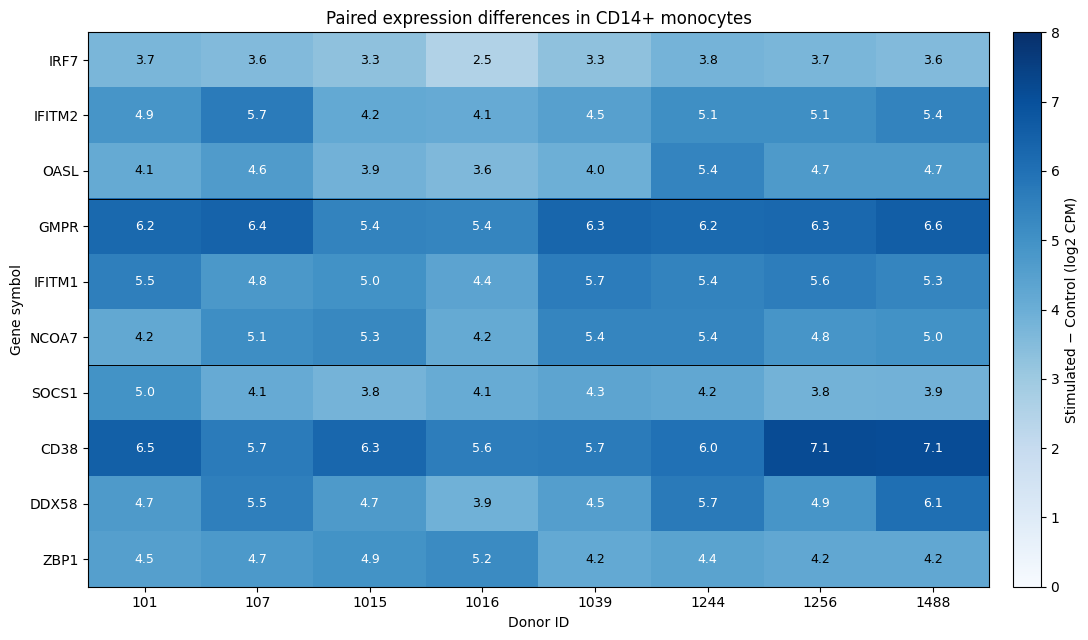

Heatmap PNG: /kaggle/working/kang_ifnb/results/figures/stage06_interferon_donor_delta_heatmap.png
PNG SHA-256: d38b5b513af945f0699072e96f2ccbb346dd3679d080f9da3a79765223e2a916
Heatmap SVG: /kaggle/working/kang_ifnb/results/figures/stage06_interferon_donor_delta_heatmap.svg
SVG SHA-256: 9f39fae09d748847c0cd25dedec2f9e12ada938a4d0f3fbdacb8157ca4e68a55

STAGE 06 DONOR HEATMAP: PASS


In [19]:

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# -------------------------------------------
# 1. Define figure output directory
# -------------------------------------------

FIGURE_DIR = (
    Path("/kaggle/working/kang_ifnb")
    / "results" / "figures"
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------
# 2. Select previously verified genes
# -------------------------------------------

gene_panel = [
    "IRF7", "IFITM2", "OASL",     # Shared
    "GMPR", "IFITM1", "NCOA7",    # Alpha only
    "SOCS1", "CD38", "DDX58", "ZBP1"  # Gamma only
]

donor_order = [
    "101", "107", "1015", "1016",
    "1039", "1244", "1256", "1488"
]

plot_data = paired.loc[
    paired["gene_symbol"].isin(gene_panel)
].copy()

plot_data["donor_id"] = (
    plot_data["donor_id"].astype(str)
)

assert len(plot_data) == 10 * 8

assert not plot_data.duplicated(
    ["gene_symbol", "donor_id"]
).any()

# -------------------------------------------
# 3. Create gene x donor matrix
# -------------------------------------------

heatmap = (
    plot_data.pivot(
        index="gene_symbol",
        columns="donor_id",
        values="delta_logCPM"
    )
    .reindex(
        index=gene_panel,
        columns=donor_order
    )
)

assert heatmap.shape == (10, 8)
assert heatmap.notna().all().all()
assert np.isfinite(heatmap.to_numpy()).all()

# The observed 10-gene panel must agree with
# the 8C checkpoint: all changes are positive.
assert (heatmap.to_numpy() > 0).all()

# -------------------------------------------
# 4. Display numerical values
# -------------------------------------------

print("Paired delta-logCPM heatmap values:")
display(heatmap.round(3))

# -------------------------------------------
# 5. Plot the heatmap
# -------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6.5))

values = heatmap.to_numpy()

image = ax.imshow(
    values,
    cmap="Blues",
    vmin=0,
    vmax=float(np.ceil(values.max())),
    aspect="auto",
)

ax.set_xticks(range(len(donor_order)))
ax.set_xticklabels(donor_order)

ax.set_yticks(range(len(gene_panel)))
ax.set_yticklabels(gene_panel)

ax.set_xlabel("Donor ID")
ax.set_ylabel("Gene symbol")

ax.set_title(
    "Paired expression differences in CD14+ monocytes"
)

# Separate the three leading-edge categories.
ax.axhline(2.5, color="black", linewidth=0.7)
ax.axhline(5.5, color="black", linewidth=0.7)

# Show actual numeric values in each cell.
for row in range(values.shape[0]):
    for col in range(values.shape[1]):

        value = values[row, col]

        text_color = (
            "white"
            if value > 0.60 * values.max()
            else "black"
        )

        ax.text(
            col,
            row,
            f"{value:.1f}",
            ha="center",
            va="center",
            fontsize=9,
            color=text_color,
        )

colorbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.035,
    pad=0.025,
)

colorbar.set_label(
    "Stimulated − Control (log2 CPM)"
)

fig.tight_layout()

# -------------------------------------------
# 6. Save the scientific figure
# -------------------------------------------

HEATMAP_PNG = (
    FIGURE_DIR
    / "stage06_interferon_donor_delta_heatmap.png"
)

HEATMAP_SVG = (
    FIGURE_DIR
    / "stage06_interferon_donor_delta_heatmap.svg"
)

fig.savefig(
    HEATMAP_PNG,
    dpi=220,
    bbox_inches="tight"
)

fig.savefig(
    HEATMAP_SVG,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# -------------------------------------------
# 7. Record figure checksums
# -------------------------------------------

print("Heatmap PNG:", HEATMAP_PNG)
print("PNG SHA-256:", sha256_file(HEATMAP_PNG))

print("Heatmap SVG:", HEATMAP_SVG)
print("SVG SHA-256:", sha256_file(HEATMAP_SVG))

print("\nSTAGE 06 DONOR HEATMAP: PASS")


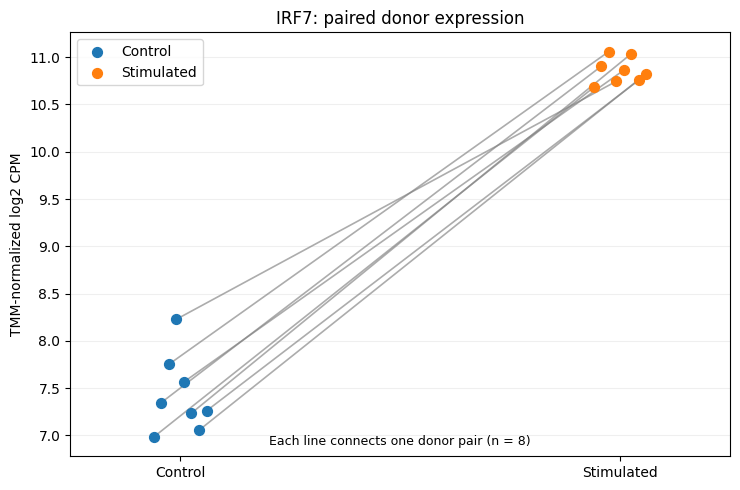

IRF7: 8/8 positive donor differences
Saved: /kaggle/working/kang_ifnb/results/figures/stage06_irf7_paired_expression.png


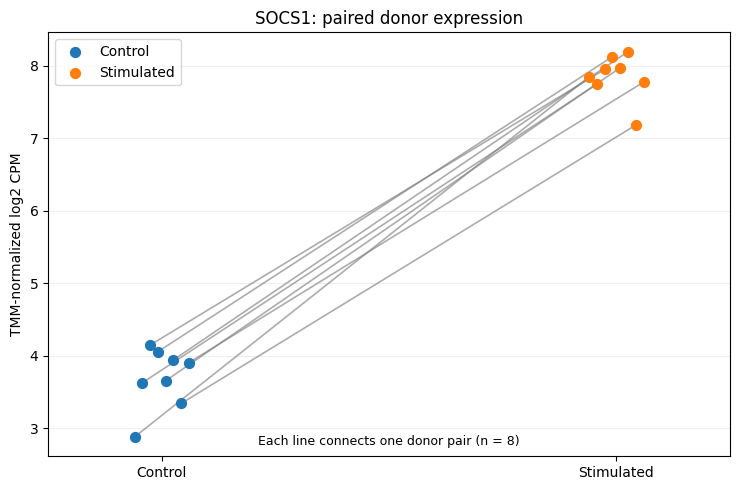

SOCS1: 8/8 positive donor differences
Saved: /kaggle/working/kang_ifnb/results/figures/stage06_socs1_paired_expression.png

Original DE/GSEA modified: NO
New hypothesis tests performed: 0

STAGE 06 PAIRED EXPRESSION PLOTS: PASS


In [20]:

import matplotlib.pyplot as plt
import numpy as np

# -------------------------------------------
# 1. Choose two pre-identified genes
# -------------------------------------------

plot_genes = ["IRF7", "SOCS1"]

# -------------------------------------------
# 2. Draw one figure per gene
# -------------------------------------------

for gene in plot_genes:

    data = paired.loc[
        paired["gene_symbol"] == gene
    ].copy()

    data["donor_id"] = (
        data["donor_id"].astype(str)
    )

    data = (
        data.set_index("donor_id")
        .loc[donor_order]
        .reset_index()
    )

    assert len(data) == 8
    assert data["donor_id"].is_unique
    assert (data["delta_logCPM"] > 0).all()

    fig, ax = plt.subplots(figsize=(7.5, 5))

    # Small horizontal offsets help reveal
    # overlapping points from different donors.
    offsets = np.linspace(-0.06, 0.06, 8)

    for i, row in enumerate(data.itertuples()):

        x_ctrl = offsets[i]
        x_stim = 1 + offsets[i]

        ax.plot(
            [x_ctrl, x_stim],
            [row.ctrl, row.stim],
            linewidth=1.2,
            alpha=0.65,
            color="gray",
        )

    ax.scatter(
        offsets,
        data["ctrl"],
        s=50,
        label="Control",
        zorder=3,
    )

    ax.scatter(
        1 + offsets,
        data["stim"],
        s=50,
        label="Stimulated",
        zorder=3,
    )

    ax.set_xlim(-0.25, 1.25)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(
        ["Control", "Stimulated"]
    )

    ax.set_ylabel("TMM-normalized log2 CPM")

    ax.set_title(
        f"{gene}: paired donor expression"
    )

    ax.text(
        0.5,
        0.02,
        "Each line connects one donor pair (n = 8)",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=9,
    )

    ax.legend(loc="best")
    ax.grid(axis="y", alpha=0.2)

    fig.tight_layout()

    output_png = (
        FIGURE_DIR
        / f"stage06_{gene.lower()}_paired_expression.png"
    )

    output_svg = (
        FIGURE_DIR
        / f"stage06_{gene.lower()}_paired_expression.svg"
    )

    fig.savefig(
        output_png,
        dpi=220,
        bbox_inches="tight",
    )

    fig.savefig(
        output_svg,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print(
        f"{gene}: "
        f"{int((data['delta_logCPM'] > 0).sum())}/8 "
        "positive donor differences"
    )

    print("Saved:", output_png)

# -------------------------------------------
# 3. Verify upstream data remain unchanged
# -------------------------------------------

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

assert len(donor_summary) == 135
assert donor_summary["n_same_direction"].eq(8).all()

print("\nOriginal DE/GSEA modified: NO")
print("New hypothesis tests performed: 0")

print("\nSTAGE 06 PAIRED EXPRESSION PLOTS: PASS")


## 12. Biological interpretation: interferon response

Compare observed results and known functions for selected interferon genes. See the repository references for annotations and interpretation limits.


In [21]:

import json
import numpy as np
import pandas as pd
from IPython.display import display

# -------------------------------------------
# 1. Define a small, reviewed gene panel
# -------------------------------------------

gene_references = pd.DataFrame([
    {
        "gene_symbol": "IRF7",
        "known_role": "Interferon-related transcription factor",
        "reference_url": "https://www.ncbi.nlm.nih.gov/gene/3665",
    },
    {
        "gene_symbol": "IFITM2",
        "known_role": "Interferon-induced antiviral effector",
        "reference_url": (
            "https://reactome.org/content/schema/instance/"
            "browser/uniprot%3AQ01629"
        ),
    },
    {
        "gene_symbol": "OASL",
        "known_role": "Antiviral response; interacts with DDX58",
        "reference_url": (
            "https://reactome.org/content/detail/R-HSA-8985153"
        ),
    },
    {
        "gene_symbol": "DDX58",
        "known_role": "Innate viral RNA sensor (RIG-I)",
        "reference_url": (
            "https://reactome.org/content/detail/R-HSA-168928"
        ),
    },
    {
        "gene_symbol": "SOCS1",
        "known_role": "Negative regulator of cytokine signaling",
        "reference_url": "https://www.ncbi.nlm.nih.gov/gene/8651",
    },
    {
        "gene_symbol": "GMPR",
        "known_role": "QC-sensitive example; function not reviewed here",
        "reference_url": "",
    },
])

assert gene_references["gene_symbol"].is_unique

# -------------------------------------------
# 2. Attach observed gene-level evidence
# -------------------------------------------

donor_columns = [
    "gene_id",
    "n_same_direction",
    "min_delta_logCPM",
    "median_delta_logCPM",
    "max_delta_logCPM",
]

evidence = (
    robust_genes
    .merge(
        donor_summary[donor_columns],
        on="gene_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        gene_references,
        on="gene_symbol",
        how="inner",
        validate="one_to_one",
    )
)

assert len(evidence) == 6
assert evidence["gene_id"].is_unique

# -------------------------------------------
# 3. Verify evidence from earlier checkpoints
# -------------------------------------------

assert evidence["n_same_direction"].eq(8).all()
assert evidence["lodo_n_same_sign"].eq(8).all()
assert evidence["lodo_n_fdr05"].eq(8).all()
assert evidence["qc95_same_sign"].all()
assert evidence["qc95_significant"].all()

assert evidence["FDR"].lt(0.05).all()

assert evidence[
    ["min_delta_logCPM", "median_delta_logCPM"]
].notna().all().all()

# Preserve the selected order.
gene_order = gene_references["gene_symbol"].tolist()

evidence["gene_symbol"] = pd.Categorical(
    evidence["gene_symbol"],
    categories=gene_order,
    ordered=True,
)

evidence = evidence.sort_values(
    "gene_symbol"
).reset_index(drop=True)

evidence["gene_symbol"] = evidence[
    "gene_symbol"
].astype(str)

# -------------------------------------------
# 4. Inspect the observed evidence
# -------------------------------------------

display_columns = [
    "gene_symbol",
    "leading_role",
    "logFC",
    "FDR",
    "n_same_direction",
    "lodo_n_fdr05",
    "median_delta_logCPM",
    "delta_logFC_qc95",
]

display_evidence = evidence[
    display_columns
].copy()

display_evidence["FDR"] = (
    display_evidence["FDR"]
    .map(lambda x: f"{x:.3e}")
)

print("Reviewed genes and observed evidence:")

display(
    display_evidence.round({
        "logFC": 4,
        "median_delta_logCPM": 4,
        "delta_logFC_qc95": 5,
    })
)

# -------------------------------------------
# 5. Preserve the context of all pathways
# -------------------------------------------

all_significant_pathways = (
    hallmark.loc[
        hallmark["padj"] < 0.05,
        ["pathway", "size", "NES", "padj"]
    ]
    .copy()
    .sort_values("padj")
)

assert len(all_significant_pathways) == 13

all_significant_pathways["direction"] = np.where(
    all_significant_pathways["NES"] > 0,
    "stimulated_side",
    "control_side",
)

print("\nAll 13 significant Hallmarks:")

display_pathways = all_significant_pathways.copy()

display_pathways["padj"] = (
    display_pathways["padj"]
    .map(lambda x: f"{x:.3e}")
)

display(display_pathways.round({"NES": 4}))

# -------------------------------------------
# 6. Save evidence without changing source data
# -------------------------------------------

EVIDENCE_PATH = (
    rank_dir / "stage06_biological_evidence_panel.tsv"
)

PATHWAY_CONTEXT_PATH = (
    rank_dir / "stage06_significant_hallmark_context.tsv"
)

evidence.to_csv(
    EVIDENCE_PATH,
    sep="\t",
    index=False,
    float_format="%.17g",
)

all_significant_pathways.to_csv(
    PATHWAY_CONTEXT_PATH,
    sep="\t",
    index=False,
    float_format="%.17g",
)

biological_audit = {
    "stage": "06_biological_evidence",
    "selected_genes": 6,
    "all_significant_hallmarks": 13,
    "gene_functions_manually_reviewed": True,
    "causal_effect_tested": False,
    "new_statistical_tests": False,
    "evidence_sha256": sha256_file(EVIDENCE_PATH),
    "pathway_context_sha256": sha256_file(
        PATHWAY_CONTEXT_PATH
    ),
}

BIOLOGICAL_AUDIT_PATH = (
    rank_dir / "stage06_biological_evidence_audit.json"
)

BIOLOGICAL_AUDIT_PATH.write_text(
    json.dumps(biological_audit, indent=2) + "\n",
    encoding="utf-8",
)

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

print("\nEvidence table:", EVIDENCE_PATH)
print("Pathway context:", PATHWAY_CONTEXT_PATH)
print("Original DE/GSEA modified: NO")

print("\nSTAGE 06 BIOLOGICAL EVIDENCE AUDIT: PASS")


Reviewed genes and observed evidence:


,gene_symbol,leading_role,logFC,FDR,n_same_direction,lodo_n_fdr05,median_delta_logCPM,delta_logFC_qc95
0,IRF7,shared_leading,3.4467,3.989e-13,8,8,3.5580,-0.00027
1,IFITM2,shared_leading,4.8858,6.728e-13,8,8,4.9670,-0.00271
2,OASL,shared_leading,4.4123,3.943e-12,8,8,4.3885,-0.00093
3,DDX58,gamma_leading_only,5.0914,3.943e-12,8,8,4.7889,-0.00317
4,SOCS1,gamma_leading_only,4.3607,1.361e-13,8,8,4.0915,-0.00222
5,GMPR,alpha_leading_only,7.0115,4.582e-15,8,8,6.2441,-0.31318



All 13 significant Hallmarks:


,pathway,size,NES,padj,direction
0,HALLMARK_INTERFERON_GAMMA_RESPONSE,155,2.6902,9.561e-41,stimulated_side
1,HALLMARK_INTERFERON_ALPHA_RESPONSE,86,2.7682,1.112e-33,stimulated_side
2,HALLMARK_OXIDATIVE_PHOSPHORYLATION,135,-2.3461,6.837e-10,control_side
3,HALLMARK_MYC_TARGETS_V1,141,-1.9343,2.198e-06,control_side
4,HALLMARK_ALLOGRAFT_REJECTION,92,1.7368,4.017e-04,stimulated_side
5,HALLMARK_INFLAMMATORY_RESPONSE,106,1.7195,4.017e-04,stimulated_side
6,HALLMARK_IL2_STAT5_SIGNALING,74,1.7136,1.124e-03,stimulated_side
7,HALLMARK_COMPLEMENT,95,1.6774,1.124e-03,stimulated_side
8,HALLMARK_GLYCOLYSIS,56,-1.7765,3.704e-03,control_side
9,HALLMARK_HYPOXIA,69,-1.7678,3.992e-03,control_side



Evidence table: /kaggle/working/kang_ifnb/results/pathway/stage06_biological_evidence_panel.tsv
Pathway context: /kaggle/working/kang_ifnb/results/pathway/stage06_significant_hallmark_context.tsv
Original DE/GSEA modified: NO

STAGE 06 BIOLOGICAL EVIDENCE AUDIT: PASS


## 13. Hallmark GSEA visualizations

Plot signed NES for significant Hallmarks and four enrichment curves. Negative NES places the signature toward the control end of the ranking.


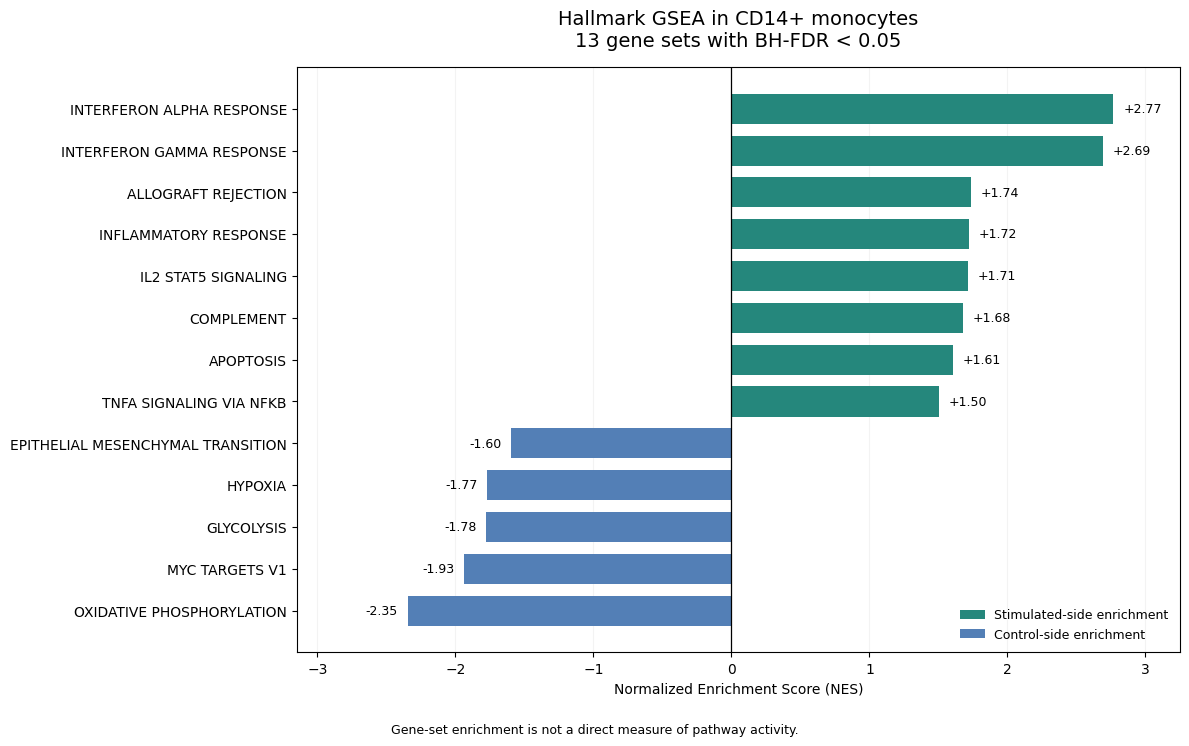

Significant Hallmarks: 13
Positive NES: 8
Negative NES: 5

NES figure: /kaggle/working/kang_ifnb/results/figures/stage06_hallmark_nes_summary.png
NES PNG SHA-256: 414b7aba0fa56294dcb96b2313832173c5fe1e801bd1bbacfb3e3bf0cee25bc1

STAGE 06 NES SUMMARY PLOT: PASS


In [22]:

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd

# -------------------------------------------
# 1. Verify the original GSEA results
# -------------------------------------------

assert sha256_file(R_GSEA_OUTPUT) == gsea_sha
assert len(hallmark) == 41

plot_df = hallmark.loc[
    hallmark["padj"] < 0.05,
    ["pathway", "NES", "padj"]
].copy()

assert len(plot_df) == 13
assert plot_df["pathway"].is_unique

assert int((plot_df["NES"] > 0).sum()) == 8
assert int((plot_df["NES"] < 0).sum()) == 5

# -------------------------------------------
# 2. Prepare readable pathway labels
# -------------------------------------------

plot_df["label"] = (
    plot_df["pathway"]
    .str.replace("HALLMARK_", "", regex=False)
    .str.replace("_", " ", regex=False)
)

# Sort by NES rather than FDR:
# this displays the direction and magnitude clearly.
plot_df = plot_df.sort_values(
    "NES",
    ascending=True
).reset_index(drop=True)

# Colors distinguish ranking direction.
positive_color = "#25877c"
negative_color = "#537fb6"

bar_colors = [
    positive_color if nes > 0 else negative_color
    for nes in plot_df["NES"]
]

# -------------------------------------------
# 3. Create the NES bar chart
# -------------------------------------------

fig, ax = plt.subplots(figsize=(12, 7.5))

y = np.arange(len(plot_df))

ax.barh(
    y,
    plot_df["NES"],
    color=bar_colors,
    height=0.72,
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df["label"], fontsize=10)

# NES = 0 is the boundary between directions.
ax.axvline(
    0,
    color="black",
    linewidth=0.9,
)

ax.set_xlim(-3.15, 3.25)

ax.set_xlabel(
    "Normalized Enrichment Score (NES)"
)

ax.set_title(
    "Hallmark GSEA in CD14+ monocytes\n"
    "13 gene sets with BH-FDR < 0.05",
    fontsize=14,
    pad=15,
)

# Display the numeric NES beside each bar.
for i, nes in enumerate(plot_df["NES"]):

    ax.text(
        nes + (0.07 if nes > 0 else -0.07),
        i,
        f"{nes:+.2f}",
        ha="left" if nes > 0 else "right",
        va="center",
        fontsize=9,
    )

ax.legend(
    handles=[
        Patch(
            facecolor=positive_color,
            label="Stimulated-side enrichment"
        ),
        Patch(
            facecolor=negative_color,
            label="Control-side enrichment"
        ),
    ],
    loc="lower right",
    frameon=False,
    fontsize=9,
)

ax.grid(
    axis="x",
    alpha=0.15,
)

ax.set_axisbelow(True)

fig.text(
    0.5,
    0.015,
    "Gene-set enrichment is not a direct measure "
    "of pathway activity.",
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.045, 1, 1])

# -------------------------------------------
# 4. Save publication-quality figures
# -------------------------------------------

NES_PNG = (
    FIGURE_DIR / "stage06_hallmark_nes_summary.png"
)

NES_PDF = (
    FIGURE_DIR / "stage06_hallmark_nes_summary.pdf"
)

fig.savefig(
    NES_PNG,
    dpi=250,
    bbox_inches="tight",
)

fig.savefig(
    NES_PDF,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# -------------------------------------------
# 5. Verify outputs
# -------------------------------------------

for path in [NES_PNG, NES_PDF]:
    assert path.is_file()
    assert path.stat().st_size > 1000

print("Significant Hallmarks:", len(plot_df))
print("Positive NES:", int((plot_df["NES"] > 0).sum()))
print("Negative NES:", int((plot_df["NES"] < 0).sum()))

print("\nNES figure:", NES_PNG)
print("NES PNG SHA-256:", sha256_file(NES_PNG))

print("\nSTAGE 06 NES SUMMARY PLOT: PASS")


In [23]:

import json
import subprocess
from pathlib import Path

# -------------------------------------------
# 1. Define input and output paths
# -------------------------------------------

assert R_GSEA_RDS.is_file()

ENRICHMENT_DIR = FIGURE_DIR / "enrichment"
ENRICHMENT_DIR.mkdir(parents=True, exist_ok=True)

R_PLOT_SCRIPT = (
    rank_dir / "stage06_plot_enrichment.R"
)

R_PLOT_LOG = (
    rank_dir / "stage06_enrichment_plot.log"
)

# -------------------------------------------
# 2. Create the R plotting script
# -------------------------------------------

r_plot_code = r'''
suppressPackageStartupMessages({
    library(fgsea)
    library(ggplot2)
})

args <- commandArgs(trailingOnly = TRUE)
stopifnot(length(args) == 2L)

rds_path <- args[1]
output_dir <- args[2]

# -------------------------------------------
# Load the original GSEA objects
# -------------------------------------------

saved <- readRDS(rds_path)

stopifnot(
    all(c("fit", "ranks", "pathways") %in% names(saved)),
    saved$msigdb_version == "2026.1.Hs",
    saved$gsea_param == 1,
    nrow(saved$fit) == 41L,
    length(saved$ranks) == 3697L,
    length(saved$pathways) == 41L
)

fit <- saved$fit
ranks <- saved$ranks
pathways <- saved$pathways

stopifnot(
    !anyDuplicated(names(ranks)),
    all(is.finite(ranks)),
    all(diff(ranks) <= 0)
)

# -------------------------------------------
# Select representative pathways
# -------------------------------------------

selected_pathways <- c(
    "HALLMARK_INTERFERON_ALPHA_RESPONSE",
    "HALLMARK_INTERFERON_GAMMA_RESPONSE",
    "HALLMARK_OXIDATIVE_PHOSPHORYLATION",
    "HALLMARK_GLYCOLYSIS"
)

stopifnot(
    all(selected_pathways %in% names(pathways))
)

# -------------------------------------------
# Plot each selected pathway
# -------------------------------------------

for (pathway_name in selected_pathways) {

    result_row <- fit[
        fit$pathway == pathway_name,
    ]

    stopifnot(
        nrow(result_row) == 1L,
        result_row$padj < 0.05
    )

    genes <- pathways[[pathway_name]]

    stopifnot(
        all(genes %in% names(ranks)),
        length(genes) == result_row$size
    )

    # Calculate the running enrichment curve
    # from the original stored rankings.
    p <- fgsea::plotEnrichment(
        pathway = genes,
        stats = ranks,
        gseaParam = 1
    )

    readable_name <- gsub(
        "_", " ",
        sub("^HALLMARK_", "", pathway_name)
    )

    subtitle_text <- sprintf(
        "NES = %+.3f | BH-FDR = %.2e | Matched genes = %d",
        result_row$NES,
        result_row$padj,
        result_row$size
    )

    p <- p +
        ggplot2::labs(
            title = readable_name,
            subtitle = subtitle_text,
            x = "Gene rank (stimulated to control)",
            y = "Running enrichment score",
            caption = paste(
                "Vertical ticks mark Hallmark gene positions.",
                "This does not measure pathway activity."
            )
        ) +
        ggplot2::theme_minimal(base_size = 12) +
        ggplot2::theme(
            plot.title = ggplot2::element_text(
                face = "bold"
            ),
            plot.caption = ggplot2::element_text(
                hjust = 0
            )
        )

    # Use stable filenames.
    short_name <- tolower(
        sub("^HALLMARK_", "", pathway_name)
    )

    base_name <- paste0(
        "stage06_", short_name, "_enrichment"
    )

    png_path <- file.path(
        output_dir, paste0(base_name, ".png")
    )

    pdf_path <- file.path(
        output_dir, paste0(base_name, ".pdf")
    )

    # Save PNG for notebook/README.
    ggplot2::ggsave(
        filename = png_path,
        plot = p,
        width = 9,
        height = 5.7,
        units = "in",
        dpi = 230,
        bg = "white"
    )

    # Save PDF for a scientific report.
    ggplot2::ggsave(
        filename = pdf_path,
        plot = p,
        device = "pdf",
        width = 9,
        height = 5.7,
        units = "in",
        bg = "white"
    )

    stopifnot(
        file.exists(png_path),
        file.exists(pdf_path),
        file.info(png_path)$size > 1000,
        file.info(pdf_path)$size > 1000
    )

    cat("PLOT_SAVED=", short_name, "\n", sep = "")
}

cat(
    "ENRICHMENT_PLOTS=",
    length(selected_pathways),
    "\n",
    sep = ""
)

cat("STAGE 06 ENRICHMENT PLOTS: PASS\n")
'''

R_PLOT_SCRIPT.write_text(
    r_plot_code,
    encoding="utf-8"
)

# -------------------------------------------
# 3. Execute R without rerunning GSEA
# -------------------------------------------

result = subprocess.run(
    [
        "Rscript",
        "--vanilla",
        str(R_PLOT_SCRIPT),
        str(R_GSEA_RDS),
        str(ENRICHMENT_DIR),
    ],
    env=env,
    capture_output=True,
    text=True,
    timeout=300,
)

R_PLOT_LOG.write_text(
    "STDOUT:\n"
    + result.stdout
    + "\nSTDERR:\n"
    + result.stderr,
    encoding="utf-8",
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr[-5000:])

assert result.returncode == 0
assert "ENRICHMENT_PLOTS=4" in result.stdout
assert (
    "STAGE 06 ENRICHMENT PLOTS: PASS"
    in result.stdout
)

# -------------------------------------------
# 4. Verify all four figure pairs
# -------------------------------------------

selected_pathways = [
    "HALLMARK_INTERFERON_ALPHA_RESPONSE",
    "HALLMARK_INTERFERON_GAMMA_RESPONSE",
    "HALLMARK_OXIDATIVE_PHOSPHORYLATION",
    "HALLMARK_GLYCOLYSIS",
]

plot_records = []

for pathway_name in selected_pathways:

    short_name = pathway_name.removeprefix(
        "HALLMARK_"
    ).lower()

    base = (
        f"stage06_{short_name}_enrichment"
    )

    png_path = ENRICHMENT_DIR / f"{base}.png"
    pdf_path = ENRICHMENT_DIR / f"{base}.pdf"

    assert png_path.is_file()
    assert pdf_path.is_file()

    plot_records.append({
        "pathway": pathway_name,
        "png_file": png_path.name,
        "png_sha256": sha256_file(png_path),
        "pdf_file": pdf_path.name,
        "pdf_sha256": sha256_file(pdf_path),
    })

# -------------------------------------------
# 5. Save figure provenance
# -------------------------------------------

plot_audit = {
    "stage": "06_enrichment_visualization",
    "source_gsea_sha256": gsea_sha,
    "source_rds_sha256": sha256_file(R_GSEA_RDS),
    "number_of_plots": len(plot_records),
    "plotting_function": "fgsea::plotEnrichment",
    "gsea_param": 1,
    "new_gsea_tests": False,
    "plots": plot_records,
    "checkpoint": "PASS",
}

PLOT_AUDIT_PATH = (
    rank_dir / "stage06_enrichment_plot_audit.json"
)

PLOT_AUDIT_PATH.write_text(
    json.dumps(plot_audit, indent=2) + "\n",
    encoding="utf-8",
)

# -------------------------------------------
# 6. Confirm upstream results are intact
# -------------------------------------------

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

print("\nFigure directory:", ENRICHMENT_DIR)
print("Figure audit:", PLOT_AUDIT_PATH)
print("Original DE/GSEA modified: NO")

print("\nSTAGE 06 PATHWAY VISUALIZATION: PASS")


PLOT_SAVED=interferon_alpha_response
PLOT_SAVED=interferon_gamma_response
PLOT_SAVED=oxidative_phosphorylation
PLOT_SAVED=glycolysis
ENRICHMENT_PLOTS=4
STAGE 06 ENRICHMENT PLOTS: PASS


Figure directory: /kaggle/working/kang_ifnb/results/figures/enrichment
Figure audit: /kaggle/working/kang_ifnb/results/pathway/stage06_enrichment_plot_audit.json
Original DE/GSEA modified: NO

STAGE 06 PATHWAY VISUALIZATION: PASS


## 14. Pathway-level leading-edge evidence

Summarize gene-level evidence and QC sensitivity for all 13 significant Hallmarks.


In [24]:

import json
import numpy as np
import pandas as pd
from IPython.display import display

# -------------------------------------------
# 1. Verify original GSEA and DE results
# -------------------------------------------

assert sha256_file(R_GSEA_OUTPUT) == gsea_sha
assert sha256_file(de_path) == observed_sha

significant_sets = (
    hallmark.loc[
        hallmark["padj"] < 0.05
    ]
    .sort_values("padj")
    .copy()
)

assert len(significant_sets) == 13
assert significant_sets["pathway"].is_unique

# -------------------------------------------
# 2. Prepare the gene-level evidence table
# -------------------------------------------

gene_lookup = ranked[
    ["gene_id", "rank_score", "logFC", "FDR"]
].copy().reset_index(drop=True)

gene_lookup["gene_id"] = (
    gene_lookup["gene_id"].astype(str)
)

# Rank position within all 3,697 tested genes.
gene_lookup["rank_position"] = (
    np.arange(len(gene_lookup)) + 1
)

gene_lookup = gene_lookup.merge(
    annotations[
        ["gene_id", "gene_symbol"]
    ],
    on="gene_id",
    how="left",
    validate="one_to_one",
)

gene_lookup = gene_lookup.merge(
    lodo_summary[
        [
            "gene_id",
            "lodo_n_same_sign",
            "lodo_n_fdr05",
        ]
    ],
    on="gene_id",
    how="left",
    validate="one_to_one",
)

qc95_info = qc95_source[
    ["gene_id", "FDR"]
].rename(columns={
    "FDR": "FDR_qc95"
})

gene_lookup = gene_lookup.merge(
    qc95_info,
    on="gene_id",
    how="left",
    validate="one_to_one",
)

assert len(gene_lookup) == 3697
assert gene_lookup["gene_id"].is_unique
assert gene_lookup.notna().all().all()

# -------------------------------------------
# 3. Prepare Hallmark membership lookup
# -------------------------------------------

membership_table = pd.read_csv(
    ELIGIBLE_MEMBERSHIP_PATH,
    sep="\t",
    dtype=str,
)

assert not membership_table.duplicated(
    ["pathway", "gene_id"]
).any()

membership_lookup = {
    pathway: set(group["gene_id"])
    for pathway, group in membership_table.groupby(
        "pathway"
    )
}

assert len(membership_lookup) == 41

# -------------------------------------------
# 4. Extract leading edges for all 13 sets
# -------------------------------------------

summary_rows = []
leading_tables = []

for row in significant_sets.itertuples():

    pathway = row.pathway
    nes = float(row.NES)

    # Parse the Ensembl IDs exported by fgsea.
    leading_ids = [
        item.strip()
        for item in row.leadingEdge.split(";")
        if item.strip()
    ]

    assert len(leading_ids) > 0
    assert len(leading_ids) == len(set(leading_ids))

    matched_ids = membership_lookup[pathway]

    assert len(matched_ids) == int(row.size)
    assert set(leading_ids) <= matched_ids

    # Retrieve the gene-level evidence.
    lead = gene_lookup.loc[
        gene_lookup["gene_id"].isin(leading_ids)
    ].copy()

    assert len(lead) == len(leading_ids)

    # Positive NES: strongest positive ranks first.
    # Negative NES: strongest negative ranks first.
    lead = lead.sort_values(
        "rank_score",
        ascending=(nes < 0),
    )

    lead["pathway"] = pathway
    lead["pathway_NES"] = nes

    lead["rank_within_leading_edge"] = (
        np.arange(len(lead)) + 1
    )

    leading_tables.append(lead)

    # ---------------------------------------
    # Summarize this Hallmark
    # ---------------------------------------

    n_leading = len(lead)

    n_primary_sig = int(
        (lead["FDR"] < 0.05).sum()
    )

    n_lodo_fdr8 = int(
        (lead["lodo_n_fdr05"] == 8).sum()
    )

    n_qc95_sig = int(
        (lead["FDR_qc95"] < 0.05).sum()
    )

    n_matching_direction = int(
        (
            np.sign(lead["logFC"])
            == np.sign(nes)
        ).sum()
    )

    representative_genes = ", ".join(
        lead["gene_symbol"].head(5).astype(str)
    )

    summary_rows.append({
        "pathway": pathway,
        "NES": nes,
        "FDR": float(row.padj),
        "matched_genes": int(row.size),
        "leading_genes": n_leading,
        "leading_fraction_pct": (
            100 * n_leading / int(row.size)
        ),
        "leading_same_direction": (
            n_matching_direction
        ),
        "leading_primary_fdr05": n_primary_sig,
        "leading_lodo_fdr8": n_lodo_fdr8,
        "leading_qc95_fdr05": n_qc95_sig,
        "representative_genes": representative_genes,
    })

# -------------------------------------------
# 5. Build the complete result tables
# -------------------------------------------

pathway_evidence = pd.DataFrame(
    summary_rows
).sort_values("FDR").reset_index(drop=True)

leading_details = pd.concat(
    leading_tables,
    ignore_index=True
)

assert len(pathway_evidence) == 13

assert not leading_details.duplicated(
    ["pathway", "gene_id"]
).any()

assert int(
    pathway_evidence["leading_genes"].sum()
) == len(leading_details)

assert (
    pathway_evidence["leading_genes"]
    <= pathway_evidence["matched_genes"]
).all()

# -------------------------------------------
# 6. Display all 13 Hallmark summaries
# -------------------------------------------

print("Pathway-level leading-edge evidence:")

summary_display = pathway_evidence.copy()

summary_display["FDR"] = (
    summary_display["FDR"]
    .map(lambda x: f"{x:.3e}")
)

display(
    summary_display.round({
        "NES": 3,
        "leading_fraction_pct": 1,
    })
)

# -------------------------------------------
# 7. Inspect metabolic leading-edge genes
# -------------------------------------------

metabolic_pathways = [
    "HALLMARK_OXIDATIVE_PHOSPHORYLATION",
    "HALLMARK_GLYCOLYSIS",
]

for pathway in metabolic_pathways:

    subset = leading_details.loc[
        leading_details["pathway"] == pathway
    ].sort_values(
        "rank_within_leading_edge"
    )

    print(f"\nTop 10 leading genes: {pathway}")

    display(
        subset[
            [
                "gene_symbol",
                "rank_position",
                "logFC",
                "rank_score",
                "FDR",
                "lodo_n_fdr05",
            ]
        ].head(10).assign(
            FDR=lambda x: x["FDR"].map(
                lambda v: f"{v:.3e}"
            )
        ).round(4)
    )

# -------------------------------------------
# 8. Save reproducible evidence tables
# -------------------------------------------

PATHWAY_EVIDENCE_PATH = (
    rank_dir
    / "stage06_all_hallmarks_leading_evidence.tsv"
)

LEADING_DETAILS_PATH = (
    rank_dir
    / "stage06_all_hallmarks_leading_genes.tsv.gz"
)

pathway_evidence.to_csv(
    PATHWAY_EVIDENCE_PATH,
    sep="\t",
    index=False,
    float_format="%.17g",
)

leading_details.to_csv(
    LEADING_DETAILS_PATH,
    sep="\t",
    index=False,
    float_format="%.17g",
    compression="gzip",
)

leading_audit = {
    "stage": "06_all_hallmark_leading_evidence",
    "hallmarks_analyzed": 13,
    "total_leading_membership_rows": int(
        len(leading_details)
    ),
    "unique_leading_genes": int(
        leading_details["gene_id"].nunique()
    ),
    "source_gsea_sha256": gsea_sha,
    "pathway_evidence_sha256": sha256_file(
        PATHWAY_EVIDENCE_PATH
    ),
    "leading_details_sha256": sha256_file(
        LEADING_DETAILS_PATH
    ),
    "new_statistical_tests": False,
    "checkpoint": "PASS",
}

LEADING_AUDIT_PATH = (
    rank_dir
    / "stage06_all_hallmarks_leading_audit.json"
)

LEADING_AUDIT_PATH.write_text(
    json.dumps(leading_audit, indent=2) + "\n",
    encoding="utf-8",
)

# -------------------------------------------
# 9. Final integrity checks
# -------------------------------------------

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

print("\nPathway summary:", PATHWAY_EVIDENCE_PATH)
print("Gene-level details:", LEADING_DETAILS_PATH)

print("Original DE/GSEA modified: NO")
print("New statistical tests performed: 0")

print(
    "\nSTAGE 06 ALL HALLMARK LEADING EVIDENCE: PASS"
)


Pathway-level leading-edge evidence:


,pathway,NES,FDR,matched_genes,leading_genes,leading_fraction_pct,leading_same_direction,leading_primary_fdr05,leading_lodo_fdr8,leading_qc95_fdr05,representative_genes
0,HALLMARK_INTERFERON_GAMMA_RESPONSE,2.690,9.561e-41,155,116,74.8,116,116,116,116,"SOCS1, IFITM2, IRF7, PLSCR1, CD38"
1,HALLMARK_INTERFERON_ALPHA_RESPONSE,2.768,1.112e-33,86,79,91.9,79,79,79,79,"IFITM2, IRF7, PLSCR1, GMPR, SAMD9L"
2,HALLMARK_OXIDATIVE_PHOSPHORYLATION,-2.346,6.837e-10,135,68,50.4,68,68,68,68,"ATP6V0B, ATP5F1, NDUFAB1, NDUFA4, ECH1"
3,HALLMARK_MYC_TARGETS_V1,-1.934,2.198e-06,141,85,60.3,85,85,85,85,"RPL6, RPS6, HNRNPA1, H2AFZ, RPS3"
4,HALLMARK_ALLOGRAFT_REJECTION,1.737,4.017e-04,92,33,35.9,33,33,33,33,"SOCS1, IRF7, LYN, CCR1, HLA-E"
5,HALLMARK_INFLAMMATORY_RESPONSE,1.719,4.017e-04,106,46,43.4,46,46,46,46,"IRF7, NMI, IFITM1, CD69, BST2"
6,HALLMARK_IL2_STAT5_SIGNALING,1.714,1.124e-03,74,27,36.5,27,27,27,27,"SOCS1, PLSCR1, RABGAP1L, GBP4, KLF6"
7,HALLMARK_COMPLEMENT,1.677,1.124e-03,95,39,41.1,39,39,39,39,"IRF7, PLSCR1, CTSC, PLEK, IRF2"
8,HALLMARK_GLYCOLYSIS,-1.777,3.704e-03,56,18,32.1,18,18,18,18,"VCAN, ENO1, IER3, CXCR4, TPI1"
9,HALLMARK_HYPOXIA,-1.768,3.992e-03,69,24,34.8,24,24,24,24,"ENO1, PLIN2, PLAUR, IER3, CXCR4"



Top 10 leading genes: HALLMARK_OXIDATIVE_PHOSPHORYLATION


,gene_symbol,rank_position,logFC,rank_score,FDR,lodo_n_fdr05
195,ATP6V0B,3645,-0.6777,-12.9512,4.960e-09,8
196,ATP5F1,3626,-1.3469,-11.8611,1.557e-08,8
197,NDUFAB1,3624,-1.5674,-11.8364,1.617e-08,8
198,NDUFA4,3622,-1.0908,-11.4495,2.493e-08,8
199,ECH1,3616,-1.7916,-11.1777,3.577e-08,8
200,UQCRC1,3608,-1.0511,-10.8174,5.313e-08,8
201,UQCRB,3582,-1.0106,-10.1353,1.200e-07,8
202,NDUFB8,3560,-1.1564,-9.8339,1.723e-07,8
203,SLC25A5,3558,-1.2250,-9.8070,1.779e-07,8
204,TIMM13,3550,-1.7775,-9.6702,2.202e-07,8



Top 10 leading genes: HALLMARK_GLYCOLYSIS


,gene_symbol,rank_position,logFC,rank_score,FDR,lodo_n_fdr05
493,VCAN,3694,-4.4200,-23.2791,3.943e-12,8
494,ENO1,3685,-1.3362,-18.2610,6.277e-11,8
495,IER3,3664,-2.3971,-15.3669,5.085e-10,8
496,CXCR4,3658,-1.2929,-14.9070,7.400e-10,8
497,TPI1,3655,-1.0708,-14.8349,7.757e-10,8
498,SDC2,3654,-3.9509,-14.7233,3.408e-10,8
499,TPST1,3648,-4.8302,-13.2991,1.451e-10,8
500,QSOX1,3629,-2.2388,-11.9974,1.360e-08,8
501,IL13RA1,3570,-1.0567,-9.9578,1.483e-07,8
502,PKM,3562,-0.6434,-9.8667,1.651e-07,8



Pathway summary: /kaggle/working/kang_ifnb/results/pathway/stage06_all_hallmarks_leading_evidence.tsv
Gene-level details: /kaggle/working/kang_ifnb/results/pathway/stage06_all_hallmarks_leading_genes.tsv.gz
Original DE/GSEA modified: NO
New statistical tests performed: 0

STAGE 06 ALL HALLMARK LEADING EVIDENCE: PASS


### 14.1. Functional review of metabolic Hallmark genes

Review selected genes from Oxidative Phosphorylation and Glycolysis. The interpretation concerns transcript abundance.


In [25]:

import json
import pandas as pd
from IPython.display import display

# -------------------------------------------
# 1. Verify upstream analysis
# -------------------------------------------

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

assert len(pathway_evidence) == 13

OXPHOS = "HALLMARK_OXIDATIVE_PHOSPHORYLATION"
GLYCOLYSIS = "HALLMARK_GLYCOLYSIS"

selected_pathways = [OXPHOS, GLYCOLYSIS]

# -------------------------------------------
# 2. Create a small reviewed annotation table
# -------------------------------------------

# Columns:
# pathway, source symbol, current symbol,
# known molecular role, reference URL.

reviewed_rows = [
    (
        OXPHOS, "ATP6V0B", "ATP6V0B",
        "Vacuolar ATPase; organelle acidification",
        "https://www.ncbi.nlm.nih.gov/gene/533"
    ),
    (
        OXPHOS, "ATP5F1", "ATP5PB",
        "Mitochondrial ATP synthase subunit",
        "https://www.ncbi.nlm.nih.gov/gene/515"
    ),
    (
        OXPHOS, "NDUFA4", "COXFA4",
        "Respiratory chain complex IV component",
        "https://pubmed.ncbi.nlm.nih.gov/22902835/"
    ),
    (
        OXPHOS, "NDUFB8", "NDUFB8",
        "Respiratory chain complex I component",
        "https://www.ncbi.nlm.nih.gov/books/NBK320989/"
    ),
    (
        OXPHOS, "UQCRC1", "UQCRC1",
        "Respiratory chain complex III component",
        "https://www.ncbi.nlm.nih.gov/gene/7384"
    ),
    (
        OXPHOS, "UQCRB", "UQCRB",
        "Respiratory chain complex III component",
        "https://www.ncbi.nlm.nih.gov/gene/7381"
    ),
    (
        OXPHOS, "SLC25A5", "SLC25A5",
        "Mitochondrial ADP/ATP transporter",
        "https://www.ncbi.nlm.nih.gov/gene/292"
    ),
    (
        GLYCOLYSIS, "VCAN", "VCAN",
        "Extracellular matrix proteoglycan",
        "https://www.ncbi.nlm.nih.gov/gene/1462"
    ),
    (
        GLYCOLYSIS, "ENO1", "ENO1",
        "Glycolytic enzyme: enolase",
        "https://www.ncbi.nlm.nih.gov/gene/2023"
    ),
    (
        GLYCOLYSIS, "CXCR4", "CXCR4",
        "Chemokine signaling receptor",
        "https://www.ncbi.nlm.nih.gov/gene/7852"
    ),
    (
        GLYCOLYSIS, "TPI1", "TPI1",
        "Glycolytic enzyme: triosephosphate isomerase",
        "https://www.ncbi.nlm.nih.gov/gene/7167"
    ),
    (
        GLYCOLYSIS, "PKM", "PKM",
        "Glycolytic enzyme: pyruvate kinase",
        "https://www.ncbi.nlm.nih.gov/gene/5315"
    ),
]

reviewed = pd.DataFrame(
    reviewed_rows,
    columns=[
        "pathway",
        "gene_symbol",
        "current_reference_symbol",
        "known_molecular_role",
        "reference_url",
    ],
)

assert len(reviewed) == 12

assert not reviewed.duplicated(
    ["pathway", "gene_symbol"]
).any()

# -------------------------------------------
# 3. Extract the original leading-edge genes
# -------------------------------------------

metabolic_leading = leading_details.loc[
    leading_details["pathway"].isin(
        selected_pathways
    )
].copy()

assert metabolic_leading["pathway"].nunique() == 2

assert not metabolic_leading.duplicated(
    ["pathway", "gene_id"]
).any()

assert not metabolic_leading.duplicated(
    ["pathway", "gene_symbol"]
).any()

# -------------------------------------------
# 4. Attach reviewed functions only
# -------------------------------------------

metabolic_annotated = metabolic_leading.merge(
    reviewed,
    on=["pathway", "gene_symbol"],
    how="left",
    validate="one_to_one",
    indicator=True,
)

assert len(metabolic_annotated) == len(
    metabolic_leading
)

metabolic_annotated["function_reviewed"] = (
    metabolic_annotated["_merge"] == "both"
)

metabolic_annotated = (
    metabolic_annotated.drop(columns="_merge")
)

assert int(
    metabolic_annotated["function_reviewed"].sum()
) == 12

# Never replace source symbols by updated symbols.
assert set(metabolic_annotated["gene_id"]) == set(
    metabolic_leading["gene_id"]
)

# -------------------------------------------
# 5. Show reviewed genes and observed evidence
# -------------------------------------------

reviewed_evidence = metabolic_annotated.loc[
    metabolic_annotated["function_reviewed"]
].sort_values(
    ["pathway", "rank_within_leading_edge"]
)

print("Functionally reviewed leading-edge genes:")

display(
    reviewed_evidence[
        [
            "pathway",
            "gene_symbol",
            "current_reference_symbol",
            "known_molecular_role",
            "logFC",
            "FDR",
            "lodo_n_fdr05",
        ]
    ].assign(
        FDR=lambda x: x["FDR"].map(
            lambda v: f"{v:.3e}"
        )
    ).round({"logFC": 4})
)

# -------------------------------------------
# 6. Audit how much has actually been reviewed
# -------------------------------------------

review_coverage = (
    metabolic_annotated.groupby(
        "pathway", as_index=False
    )
    .agg(
        total_leading_genes=("gene_id", "size"),
        function_reviewed=("function_reviewed", "sum"),
    )
)

review_coverage["not_yet_reviewed"] = (
    review_coverage["total_leading_genes"]
    - review_coverage["function_reviewed"]
)

print("\nFunctional review coverage:")
display(review_coverage)

# -------------------------------------------
# 7. Preserve a complete view of all 13 sets
# -------------------------------------------

print("\nAll 13 Hallmark leading-edge summaries:")

display(
    pathway_evidence[
        [
            "pathway",
            "matched_genes",
            "leading_genes",
            "leading_fraction_pct",
            "leading_primary_fdr05",
            "leading_lodo_fdr8",
            "leading_qc95_fdr05",
        ]
    ].round(2)
)

# -------------------------------------------
# 8. Save functional annotation audit
# -------------------------------------------

METABOLIC_REVIEW_PATH = (
    rank_dir
    / "stage06_metabolic_gene_function_review.tsv"
)

METABOLIC_DETAILS_PATH = (
    rank_dir
    / "stage06_metabolic_leading_annotated.tsv.gz"
)

reviewed_evidence.to_csv(
    METABOLIC_REVIEW_PATH,
    sep="\t",
    index=False,
    float_format="%.17g",
)

metabolic_annotated.to_csv(
    METABOLIC_DETAILS_PATH,
    sep="\t",
    index=False,
    compression="gzip",
    float_format="%.17g",
)

review_audit = {
    "stage": "06_metabolic_function_review",
    "status": "PASS",
    "pathways_reviewed": selected_pathways,
    "reviewed_gene_pathway_pairs": 12,
    "all_remaining_genes_classified": False,
    "source_symbols_preserved": True,
    "gene_id_mapping_changed": False,
    "new_statistical_tests": False,
    "review_table_sha256": sha256_file(
        METABOLIC_REVIEW_PATH
    ),
    "full_table_sha256": sha256_file(
        METABOLIC_DETAILS_PATH
    ),
}

METABOLIC_AUDIT_PATH = (
    rank_dir
    / "stage06_metabolic_function_audit.json"
)

METABOLIC_AUDIT_PATH.write_text(
    json.dumps(review_audit, indent=2) + "\n",
    encoding="utf-8",
)

# -------------------------------------------
# 9. Final integrity checks
# -------------------------------------------

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

print("\nFunctional review:", METABOLIC_REVIEW_PATH)
print("Full leading-edge table:", METABOLIC_DETAILS_PATH)
print("Original DE/GSEA modified: NO")

print("\nSTAGE 06 METABOLIC FUNCTION AUDIT: PASS")


Functionally reviewed leading-edge genes:


,pathway,gene_symbol,current_reference_symbol,known_molecular_role,logFC,FDR,lodo_n_fdr05
68,HALLMARK_GLYCOLYSIS,VCAN,VCAN,Extracellular matrix proteoglycan,-4.4200,3.943e-12,8
69,HALLMARK_GLYCOLYSIS,ENO1,ENO1,Glycolytic enzyme: enolase,-1.3362,6.277e-11,8
71,HALLMARK_GLYCOLYSIS,CXCR4,CXCR4,Chemokine signaling receptor,-1.2929,7.400e-10,8
72,HALLMARK_GLYCOLYSIS,TPI1,TPI1,Glycolytic enzyme: triosephosphate isomerase,-1.0708,7.757e-10,8
77,HALLMARK_GLYCOLYSIS,PKM,PKM,Glycolytic enzyme: pyruvate kinase,-0.6434,1.651e-07,8
0,HALLMARK_OXIDATIVE_PHOSPHORYLATION,ATP6V0B,ATP6V0B,Vacuolar ATPase; organelle acidification,-0.6777,4.960e-09,8
1,HALLMARK_OXIDATIVE_PHOSPHORYLATION,ATP5F1,ATP5PB,Mitochondrial ATP synthase subunit,-1.3469,1.557e-08,8
3,HALLMARK_OXIDATIVE_PHOSPHORYLATION,NDUFA4,COXFA4,Respiratory chain complex IV component,-1.0908,2.493e-08,8
5,HALLMARK_OXIDATIVE_PHOSPHORYLATION,UQCRC1,UQCRC1,Respiratory chain complex III component,-1.0511,5.313e-08,8
6,HALLMARK_OXIDATIVE_PHOSPHORYLATION,UQCRB,UQCRB,Respiratory chain complex III component,-1.0106,1.200e-07,8



Functional review coverage:


,pathway,total_leading_genes,function_reviewed,not_yet_reviewed
0,HALLMARK_GLYCOLYSIS,18,5,13
1,HALLMARK_OXIDATIVE_PHOSPHORYLATION,68,7,61



All 13 Hallmark leading-edge summaries:


,pathway,matched_genes,leading_genes,leading_fraction_pct,leading_primary_fdr05,leading_lodo_fdr8,leading_qc95_fdr05
0,HALLMARK_INTERFERON_GAMMA_RESPONSE,155,116,74.84,116,116,116
1,HALLMARK_INTERFERON_ALPHA_RESPONSE,86,79,91.86,79,79,79
2,HALLMARK_OXIDATIVE_PHOSPHORYLATION,135,68,50.37,68,68,68
3,HALLMARK_MYC_TARGETS_V1,141,85,60.28,85,85,85
4,HALLMARK_ALLOGRAFT_REJECTION,92,33,35.87,33,33,33
5,HALLMARK_INFLAMMATORY_RESPONSE,106,46,43.40,46,46,46
6,HALLMARK_IL2_STAT5_SIGNALING,74,27,36.49,27,27,27
7,HALLMARK_COMPLEMENT,95,39,41.05,39,39,39
8,HALLMARK_GLYCOLYSIS,56,18,32.14,18,18,18
9,HALLMARK_HYPOXIA,69,24,34.78,24,24,24



Functional review: /kaggle/working/kang_ifnb/results/pathway/stage06_metabolic_gene_function_review.tsv
Full leading-edge table: /kaggle/working/kang_ifnb/results/pathway/stage06_metabolic_leading_annotated.tsv.gz
Original DE/GSEA modified: NO

STAGE 06 METABOLIC FUNCTION AUDIT: PASS


### 14.2. Immune and inflammatory Hallmark overlap

Report leading-edge overlap and Jaccard similarity for five immune-related signatures.


In [26]:

from itertools import combinations
import json

import numpy as np
import pandas as pd
from IPython.display import display

# -------------------------------------------
# 1. Verify source data
# -------------------------------------------

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

assert len(pathway_evidence) == 13

# -------------------------------------------
# 2. Define the five immune-related Hallmarks
# -------------------------------------------

IMMUNE_PATHWAYS = [
    "HALLMARK_INFLAMMATORY_RESPONSE",
    "HALLMARK_TNFA_SIGNALING_VIA_NFKB",
    "HALLMARK_COMPLEMENT",
    "HALLMARK_IL2_STAT5_SIGNALING",
    "HALLMARK_ALLOGRAFT_REJECTION",
]

expected_leading = {
    "HALLMARK_INFLAMMATORY_RESPONSE": 46,
    "HALLMARK_TNFA_SIGNALING_VIA_NFKB": 53,
    "HALLMARK_COMPLEMENT": 39,
    "HALLMARK_IL2_STAT5_SIGNALING": 27,
    "HALLMARK_ALLOGRAFT_REJECTION": 33,
}

assert set(IMMUNE_PATHWAYS).issubset(
    set(pathway_evidence["pathway"])
)

# -------------------------------------------
# 3. Extract immune leading-edge genes
# -------------------------------------------

immune_leading = leading_details.loc[
    leading_details["pathway"].isin(
        IMMUNE_PATHWAYS
    )
].copy()

assert len(immune_leading) == 198

assert not immune_leading.duplicated(
    ["pathway", "gene_id"]
).any()

assert immune_leading["gene_symbol"].notna().all()

# These are results already established
# in the previous all-Hallmark audit.
assert immune_leading["FDR"].lt(0.05).all()
assert immune_leading["lodo_n_fdr05"].eq(8).all()

# -------------------------------------------
# 4. Compare with interferon leading edges
# -------------------------------------------

ifn_union = set(
    annotated_leading["gene_id"].astype(str)
)

assert len(ifn_union) == 135

immune_leading["in_interferon_leading"] = (
    immune_leading["gene_id"].isin(ifn_union)
)

# -------------------------------------------
# 5. Summarize each immune Hallmark
# -------------------------------------------

summary_rows = []

for pathway in IMMUNE_PATHWAYS:

    subset = immune_leading.loc[
        immune_leading["pathway"] == pathway
    ]

    assert len(subset) == expected_leading[pathway]

    n_shared = int(
        subset["in_interferon_leading"].sum()
    )

    n_total = len(subset)

    summary_rows.append({
        "pathway": pathway,
        "NES": float(
            pathway_evidence.set_index("pathway")
            .loc[pathway, "NES"]
        ),
        "leading_genes": n_total,
        "shared_with_interferon": n_shared,
        "outside_interferon_leading": (
            n_total - n_shared
        ),
        "shared_pct": 100 * n_shared / n_total,
    })

immune_summary = pd.DataFrame(summary_rows)

assert len(immune_summary) == 5

assert (
    immune_summary["leading_genes"]
    .sum() == 198
)

print("Immune Hallmark overlap with interferon:")
display(
    immune_summary.round({
        "NES": 3,
        "shared_pct": 1,
    })
)

# -------------------------------------------
# 6. Calculate pairwise Jaccard similarity
# -------------------------------------------

gene_sets = {
    pathway: set(
        immune_leading.loc[
            immune_leading["pathway"] == pathway,
            "gene_id"
        ]
    )
    for pathway in IMMUNE_PATHWAYS
}

overlap_rows = []

for a, b in combinations(IMMUNE_PATHWAYS, 2):

    intersection = gene_sets[a] & gene_sets[b]
    union = gene_sets[a] | gene_sets[b]

    overlap_rows.append({
        "pathway_a": a,
        "pathway_b": b,
        "shared_genes": len(intersection),
        "union_genes": len(union),
        "jaccard": (
            len(intersection) / len(union)
        ),
    })

pairwise_overlap = pd.DataFrame(overlap_rows)

assert len(pairwise_overlap) == 10

print("\nLeading-edge overlap between immune Hallmarks:")

display(
    pairwise_overlap.sort_values(
        "jaccard",
        ascending=False
    ).round({"jaccard": 3})
)

# -------------------------------------------
# 7. Display candidate genes for review
# -------------------------------------------

candidate_tables = []

for pathway in IMMUNE_PATHWAYS:

    subset = immune_leading.loc[
        immune_leading["pathway"] == pathway
    ].sort_values(
        "rank_within_leading_edge"
    )

    # First, inspect the strongest-ranked
    # leading-edge genes in this Hallmark.
    top_genes = subset.head(6).copy()

    print(f"\nTop leading genes: {pathway}")

    shown = top_genes[
        [
            "gene_symbol",
            "logFC",
            "FDR",
            "lodo_n_fdr05",
            "in_interferon_leading",
        ]
    ].copy()

    shown["FDR"] = shown["FDR"].map(
        lambda x: f"{x:.3e}"
    )

    display(shown.round({"logFC": 4}))

    # Also inspect genes not belonging to
    # either interferon leading edge.
    outside_ifn = subset.loc[
        ~subset["in_interferon_leading"]
    ].head(5).copy()

    outside_ifn["candidate_category"] = (
        "outside_interferon_leading"
    )

    candidate_tables.append(outside_ifn)

    print("Top candidates outside interferon leading edges:")

    if outside_ifn.empty:
        print("No candidates in this category.")
    else:
        shown_outside = outside_ifn[
            [
                "gene_symbol",
                "logFC",
                "FDR",
                "lodo_n_fdr05",
            ]
        ].copy()

        shown_outside["FDR"] = (
            shown_outside["FDR"].map(
                lambda x: f"{x:.3e}"
            )
        )

        display(shown_outside.round({"logFC": 4}))

candidates = pd.concat(
    candidate_tables,
    ignore_index=True
)

# -------------------------------------------
# 8. Save detailed results
# -------------------------------------------

IMMUNE_SUMMARY_PATH = (
    rank_dir / "stage06_immune_overlap_summary.tsv"
)

IMMUNE_PAIRWISE_PATH = (
    rank_dir / "stage06_immune_pairwise_overlap.tsv"
)

IMMUNE_DETAILS_PATH = (
    rank_dir / "stage06_immune_leading_details.tsv.gz"
)

IMMUNE_CANDIDATES_PATH = (
    rank_dir / "stage06_immune_function_candidates.tsv"
)

immune_summary.to_csv(
    IMMUNE_SUMMARY_PATH,
    sep="\t",
    index=False
)

pairwise_overlap.to_csv(
    IMMUNE_PAIRWISE_PATH,
    sep="\t",
    index=False
)

immune_leading.to_csv(
    IMMUNE_DETAILS_PATH,
    sep="\t",
    index=False,
    float_format="%.17g"
)

candidates.to_csv(
    IMMUNE_CANDIDATES_PATH,
    sep="\t",
    index=False
)

# -------------------------------------------
# 9. Save reproducibility audit
# -------------------------------------------

immune_audit = {
    "stage": "06_immune_hallmark_overlap",
    "status": "PASS",
    "hallmarks": IMMUNE_PATHWAYS,
    "leading_membership_rows": 198,
    "unique_leading_genes": int(
        immune_leading["gene_id"].nunique()
    ),
    "source_gsea_sha256": gsea_sha,
    "summary_sha256": sha256_file(
        IMMUNE_SUMMARY_PATH
    ),
    "pairwise_sha256": sha256_file(
        IMMUNE_PAIRWISE_PATH
    ),
    "details_sha256": sha256_file(
        IMMUNE_DETAILS_PATH
    ),
    "new_statistical_tests": False,
}

IMMUNE_AUDIT_PATH = (
    rank_dir / "stage06_immune_overlap_audit.json"
)

IMMUNE_AUDIT_PATH.write_text(
    json.dumps(immune_audit, indent=2) + "\n",
    encoding="utf-8"
)

# -------------------------------------------
# 10. Verify original results
# -------------------------------------------

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

print("\nUnique immune leading genes:",
      immune_leading["gene_id"].nunique())

print("Original DE/GSEA modified: NO")
print("New statistical tests performed: 0")

print("\nSTAGE 06 IMMUNE OVERLAP AUDIT: PASS")


Immune Hallmark overlap with interferon:


,pathway,NES,leading_genes,shared_with_interferon,outside_interferon_leading,shared_pct
0,HALLMARK_INFLAMMATORY_RESPONSE,1.719,46,26,20,56.5
1,HALLMARK_TNFA_SIGNALING_VIA_NFKB,1.502,53,15,38,28.3
2,HALLMARK_COMPLEMENT,1.677,39,12,27,30.8
3,HALLMARK_IL2_STAT5_SIGNALING,1.714,27,12,15,44.4
4,HALLMARK_ALLOGRAFT_REJECTION,1.737,33,22,11,66.7



Leading-edge overlap between immune Hallmarks:


,pathway_a,pathway_b,shared_genes,union_genes,jaccard
0,HALLMARK_INFLAMMATORY_RESPONSE,HALLMARK_TNFA_SIGNALING_VIA_NFKB,15,84,0.179
3,HALLMARK_INFLAMMATORY_RESPONSE,HALLMARK_ALLOGRAFT_REJECTION,10,69,0.145
2,HALLMARK_INFLAMMATORY_RESPONSE,HALLMARK_IL2_STAT5_SIGNALING,8,65,0.123
5,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_IL2_STAT5_SIGNALING,5,75,0.067
8,HALLMARK_COMPLEMENT,HALLMARK_ALLOGRAFT_REJECTION,4,68,0.059
9,HALLMARK_IL2_STAT5_SIGNALING,HALLMARK_ALLOGRAFT_REJECTION,3,57,0.053
1,HALLMARK_INFLAMMATORY_RESPONSE,HALLMARK_COMPLEMENT,4,81,0.049
6,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_ALLOGRAFT_REJECTION,4,82,0.049
4,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_COMPLEMENT,4,88,0.045
7,HALLMARK_COMPLEMENT,HALLMARK_IL2_STAT5_SIGNALING,2,64,0.031



Unique immune leading genes: 147
Original DE/GSEA modified: NO
New statistical tests performed: 0

STAGE 06 IMMUNE OVERLAP AUDIT: PASS


### 14.3. Targeted functional review of immune genes

Record curated functions for selected immune genes and retain all matched identifiers.


In [28]:

import json
import pandas as pd
from IPython.display import display

# -------------------------------------------
# 1. Verify upstream results
# -------------------------------------------

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

assert len(immune_leading) == 198
assert immune_leading["gene_id"].nunique() == 147

assert not immune_leading.duplicated(
    ["pathway", "gene_id"]
).any()

# -------------------------------------------
# 2. Curated gene functions from NCBI Gene
# -------------------------------------------

reviewed_functions = pd.DataFrame(
    [
        (
            "LYN",
            "Immune signaling",
            "Src-family tyrosine kinase",
            "https://www.ncbi.nlm.nih.gov/gene/4067",
        ),
        (
            "MSR1",
            "Scavenger receptor",
            "Macrophage scavenger receptor",
            "https://www.ncbi.nlm.nih.gov/gene/4481",
        ),
        (
            "C3AR1",
            "Complement sensing",
            "Receptor for complement fragment C3a",
            "https://www.ncbi.nlm.nih.gov/gene/719",
        ),
        (
            "SAT1",
            "Polyamine metabolism",
            "Spermidine/spermine acetyltransferase",
            "https://www.ncbi.nlm.nih.gov/gene/6303",
        ),
        (
            "CFLAR",
            "Cell-death regulation",
            "CASP8-associated apoptosis regulator",
            "https://www.ncbi.nlm.nih.gov/gene/8837",
        ),
        (
            "CTSC",
            "Lysosomal proteolysis",
            "Lysosomal cysteine protease",
            "https://www.ncbi.nlm.nih.gov/gene/1075",
        ),
        (
            "CCR1",
            "Chemokine signaling",
            "C-C chemokine receptor",
            "https://www.ncbi.nlm.nih.gov/gene/1230",
        ),
        (
            "HLA-E",
            "Immune recognition",
            "Non-classical MHC class I molecule",
            "https://www.ncbi.nlm.nih.gov/gene/3133",
        ),
        (
            "TAP1",
            "Antigen processing",
            "Peptide transporter for MHC I loading",
            "https://www.ncbi.nlm.nih.gov/gene/6890",
        ),
        (
            "SOCS1",
            "Cytokine regulation",
            "Negative regulator of cytokine signaling",
            "https://www.ncbi.nlm.nih.gov/gene/8651",
        ),
    ],
    columns=[
        "gene_symbol",
        "functional_category",
        "known_molecular_role",
        "reference_url",
    ],
)

assert len(reviewed_functions) == 10
assert reviewed_functions["gene_symbol"].is_unique

# -------------------------------------------
# 3. Resolve Ensembl IDs using source metadata
# -------------------------------------------

reviewed_ids = reviewed_functions.merge(
    annotations[["gene_id", "gene_symbol"]],
    on="gene_symbol",
    how="left",
    validate="one_to_one",
    indicator=True,
)

assert reviewed_ids["_merge"].eq("both").all()

reviewed_ids = reviewed_ids.drop(
    columns="_merge"
)

assert reviewed_ids["gene_id"].is_unique

assert set(reviewed_ids["gene_id"]).issubset(
    set(immune_leading["gene_id"])
)

# -------------------------------------------
# 4. Annotate the complete immune table
# -------------------------------------------

immune_functional = immune_leading.merge(
    reviewed_ids[
        [
            "gene_id",
            "functional_category",
            "known_molecular_role",
            "reference_url",
        ]
    ],
    on="gene_id",
    how="left",
    validate="many_to_one",
)

immune_functional["function_reviewed"] = (
    immune_functional["known_molecular_role"].notna()
)

assert len(immune_functional) == 198

assert not immune_functional.duplicated(
    ["pathway", "gene_id"]
).any()

assert (
    immune_functional.loc[
        immune_functional["function_reviewed"],
        "gene_id",
    ].nunique()
) == 10

# -------------------------------------------
# 5. Count unique overlap with interferon
# -------------------------------------------

immune_ids = set(immune_functional["gene_id"])
interferon_ids = set(annotated_leading["gene_id"])

unique_shared = len(
    immune_ids & interferon_ids
)

unique_outside = len(
    immune_ids - interferon_ids
)

assert len(immune_ids) == 147
assert unique_shared + unique_outside == 147

print("Unique immune leading-edge genes:", 147)
print("Unique genes shared with interferon:", unique_shared)
print("Unique genes outside interferon:", unique_outside)

# -------------------------------------------
# 6. Summarize functional review coverage
# -------------------------------------------

immune_review_coverage = (
    immune_functional.groupby(
        "pathway", as_index=False
    )
    .agg(
        leading_genes=("gene_id", "size"),
        reviewed_memberships=(
            "function_reviewed", "sum"
        ),
    )
)

immune_review_coverage["unreviewed_memberships"] = (
    immune_review_coverage["leading_genes"]
    - immune_review_coverage["reviewed_memberships"]
)

print("\nFunctional review coverage by Hallmark:")

display(immune_review_coverage)

# -------------------------------------------
# 7. Summarize evidence per reviewed gene
# -------------------------------------------

reviewed_gene_rows = immune_functional.loc[
    immune_functional["function_reviewed"]
].copy()

# The DE statistics must be consistent when
# the same gene occurs in multiple Hallmarks.
for field in ["logFC", "FDR", "lodo_n_fdr05"]:
    assert (
        reviewed_gene_rows.groupby("gene_id")[field]
        .nunique().eq(1).all()
    )

gene_memberships = (
    reviewed_gene_rows.groupby(
        "gene_id", as_index=False
    )
    .agg(
        n_immune_hallmarks=("pathway", "nunique"),
        immune_hallmarks=(
            "pathway",
            lambda s: ";".join(sorted(set(s))),
        ),
    )
)

reviewed_gene_evidence = (
    reviewed_gene_rows
    .drop_duplicates("gene_id")
    [
        [
            "gene_id",
            "gene_symbol",
            "functional_category",
            "known_molecular_role",
            "reference_url",
            "in_interferon_leading",
            "logFC",
            "FDR",
            "lodo_n_fdr05",
        ]
    ]
    .merge(
        gene_memberships,
        on="gene_id",
        validate="one_to_one",
    )
    .sort_values("gene_symbol")
    .reset_index(drop=True)
)

assert len(reviewed_gene_evidence) == 10
assert reviewed_gene_evidence["gene_id"].is_unique

# Keep FDR at full precision in the saved table.
print("\nReviewed immune genes and observed evidence:")

shown = reviewed_gene_evidence.copy()

shown["FDR"] = shown["FDR"].map(
    lambda value: f"{value:.3e}"
)

display(
    shown[
        [
            "gene_symbol",
            "functional_category",
            "n_immune_hallmarks",
            "in_interferon_leading",
            "logFC",
            "FDR",
            "lodo_n_fdr05",
        ]
    ].round({"logFC": 4})
)

# -------------------------------------------
# 8. Save reviewed and unreviewed information
# -------------------------------------------

IMMUNE_REVIEW_PATH = (
    rank_dir / "stage06_immune_function_review.tsv"
)

IMMUNE_FUNCTIONAL_DETAILS_PATH = (
    rank_dir / "stage06_immune_functional_details.tsv.gz"
)

reviewed_gene_evidence.to_csv(
    IMMUNE_REVIEW_PATH,
    sep="\t",
    index=False,
    float_format="%.17g",
)

immune_functional.to_csv(
    IMMUNE_FUNCTIONAL_DETAILS_PATH,
    sep="\t",
    index=False,
    float_format="%.17g",
    compression="gzip",
)

# -------------------------------------------
# 9. Reproducibility record
# -------------------------------------------

immune_function_audit = {
    "stage": "06_immune_function_review",
    "status": "PASS",
    "unique_immune_leading_genes": 147,
    "reviewed_unique_genes": 10,
    "unique_overlap_with_interferon": unique_shared,
    "unique_outside_interferon": unique_outside,
    "reviewed_table_sha256": sha256_file(
        IMMUNE_REVIEW_PATH
    ),
    "full_table_sha256": sha256_file(
        IMMUNE_FUNCTIONAL_DETAILS_PATH
    ),
    "external_annotation_used": "NCBI Gene",
    "new_statistical_tests": False,
}

IMMUNE_FUNCTION_AUDIT_PATH = (
    rank_dir / "stage06_immune_function_audit.json"
)

IMMUNE_FUNCTION_AUDIT_PATH.write_text(
    json.dumps(
        immune_function_audit, indent=2
    ) + "\n",
    encoding="utf-8",
)

# -------------------------------------------
# 10. Verify original analysis unchanged
# -------------------------------------------

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

print("\nReviewed genes:", IMMUNE_REVIEW_PATH)
print("Full immune annotation:", IMMUNE_FUNCTIONAL_DETAILS_PATH)
print("Original DE/GSEA modified: NO")

print("\nSTAGE 06 IMMUNE FUNCTION REVIEW: PASS")


Unique immune leading-edge genes: 147
Unique genes shared with interferon: 56
Unique genes outside interferon: 91

Functional review coverage by Hallmark:


,pathway,leading_genes,reviewed_memberships,unreviewed_memberships
0,HALLMARK_ALLOGRAFT_REJECTION,33,5,28
1,HALLMARK_COMPLEMENT,39,2,37
2,HALLMARK_IL2_STAT5_SIGNALING,27,1,26
3,HALLMARK_INFLAMMATORY_RESPONSE,46,3,43
4,HALLMARK_TNFA_SIGNALING_VIA_NFKB,53,3,50



Reviewed immune genes and observed evidence:


,gene_symbol,functional_category,n_immune_hallmarks,in_interferon_leading,logFC,FDR,lodo_n_fdr05
0,C3AR1,Complement sensing,1,False,1.3898,7.561e-10,8
1,CCR1,Chemokine signaling,1,False,2.0305,1.071e-11,8
2,CFLAR,Cell-death regulation,1,False,2.5650,3.712e-11,8
3,CTSC,Lysosomal proteolysis,1,False,4.4564,4.822e-12,8
4,HLA-E,Immune recognition,1,False,1.4504,3.011e-11,8
5,LYN,Immune signaling,3,False,2.1334,7.189e-12,8
6,MSR1,Scavenger receptor,1,False,3.8191,5.896e-11,8
7,SAT1,Polyamine metabolism,1,False,2.0115,4.659e-13,8
8,SOCS1,Cytokine regulation,2,True,4.3607,1.361e-13,8
9,TAP1,Antigen processing,2,True,2.1665,4.418e-11,8



Reviewed genes: /kaggle/working/kang_ifnb/results/pathway/stage06_immune_function_review.tsv
Full immune annotation: /kaggle/working/kang_ifnb/results/pathway/stage06_immune_functional_details.tsv.gz
Original DE/GSEA modified: NO

STAGE 06 IMMUNE FUNCTION REVIEW: PASS


### 14.4. Remaining significant Hallmark signatures

Review MYC Targets V1, Hypoxia, Apoptosis and Epithelial–Mesenchymal Transition.


In [29]:

import json
import numpy as np
import pandas as pd
from IPython.display import display

# -------------------------------------------
# 1. Verify upstream analysis
# -------------------------------------------

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

assert len(pathway_evidence) == 13
assert leading_details["gene_id"].notna().all()

# -------------------------------------------
# 2. Define the four remaining Hallmarks
# -------------------------------------------

REMAINING_PATHWAYS = [
    "HALLMARK_MYC_TARGETS_V1",
    "HALLMARK_HYPOXIA",
    "HALLMARK_APOPTOSIS",
    "HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION",
]

expected_counts = {
    "HALLMARK_MYC_TARGETS_V1": 85,
    "HALLMARK_HYPOXIA": 24,
    "HALLMARK_APOPTOSIS": 24,
    "HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION": 16,
}

# -------------------------------------------
# 3. Extract previously calculated leading genes
# -------------------------------------------

remaining = leading_details.loc[
    leading_details["pathway"].isin(
        REMAINING_PATHWAYS
    )
].copy()

assert len(remaining) == 149
assert remaining["pathway"].nunique() == 4

assert not remaining.duplicated(
    ["pathway", "gene_id"]
).any()

for pathway, expected in expected_counts.items():

    subset = remaining.loc[
        remaining["pathway"] == pathway
    ]

    assert len(subset) == expected

# -------------------------------------------
# 4. Verify gene-level evidence
# -------------------------------------------

assert remaining["gene_symbol"].notna().all()
assert remaining["FDR"].lt(0.05).all()
assert remaining["lodo_n_fdr05"].eq(8).all()
assert remaining["FDR_qc95"].lt(0.05).all()

# -------------------------------------------
# 5. Build reference sets from previous work
# -------------------------------------------

ifn_ids = set(
    annotated_leading["gene_id"].astype(str)
)

immune_ids = set(
    immune_leading["gene_id"].astype(str)
)

metabolic_ids = set(
    metabolic_leading["gene_id"].astype(str)
)

previously_examined = (
    ifn_ids | immune_ids | metabolic_ids
)

# A gene can belong to more than one reference group.
remaining["in_ifn_leading"] = (
    remaining["gene_id"].isin(ifn_ids)
)

remaining["in_immune_leading"] = (
    remaining["gene_id"].isin(immune_ids)
)

remaining["in_metabolic_leading"] = (
    remaining["gene_id"].isin(metabolic_ids)
)

remaining["in_previous_leading"] = (
    remaining["gene_id"].isin(
        previously_examined
    )
)

# -------------------------------------------
# 6. Summarize each Hallmark
# -------------------------------------------

pathway_lookup = (
    pathway_evidence.set_index("pathway")
)

summary_rows = []

for pathway in REMAINING_PATHWAYS:

    subset = remaining.loc[
        remaining["pathway"] == pathway
    ].copy()

    nes = float(
        pathway_lookup.loc[pathway, "NES"]
    )

    n_same_direction = int(
        (
            np.sign(subset["logFC"])
            == np.sign(nes)
        ).sum()
    )

    summary_rows.append({
        "pathway": pathway,
        "NES": nes,
        "leading_genes": len(subset),
        "same_direction_as_NES": n_same_direction,
        "primary_fdr05": int(
            (subset["FDR"] < 0.05).sum()
        ),
        "lodo_fdr8": int(
            (subset["lodo_n_fdr05"] == 8).sum()
        ),
        "qc95_fdr05": int(
            (subset["FDR_qc95"] < 0.05).sum()
        ),
        "shared_with_ifn": int(
            subset["in_ifn_leading"].sum()
        ),
        "shared_with_immune": int(
            subset["in_immune_leading"].sum()
        ),
        "shared_with_metabolic": int(
            subset["in_metabolic_leading"].sum()
        ),
        "outside_previous_leading": int(
            (~subset["in_previous_leading"]).sum()
        ),
    })

remaining_summary = pd.DataFrame(
    summary_rows
)

assert len(remaining_summary) == 4
assert remaining_summary["leading_genes"].sum() == 149

print("Remaining Hallmark leading-edge summary:")
display(remaining_summary.round({"NES": 4}))

# -------------------------------------------
# 7. Display leading-edge genes per Hallmark
# -------------------------------------------

for pathway in REMAINING_PATHWAYS:

    subset = (
        remaining.loc[
            remaining["pathway"] == pathway
        ]
        .sort_values(
            "rank_within_leading_edge"
        )
    )

    print(f"\nTop 10 leading genes: {pathway}")

    shown = subset[
        [
            "gene_symbol",
            "rank_position",
            "logFC",
            "rank_score",
            "FDR",
            "lodo_n_fdr05",
            "in_previous_leading",
        ]
    ].head(10).copy()

    shown["FDR"] = shown["FDR"].map(
        lambda value: f"{value:.3e}"
    )

    display(
        shown.round({
            "logFC": 4,
            "rank_score": 4,
        })
    )

# -------------------------------------------
# 8. Report unique gene counts
# -------------------------------------------

n_unique = remaining["gene_id"].nunique()

n_new = (
    remaining.loc[
        ~remaining["in_previous_leading"],
        "gene_id"
    ].nunique()
)

print("\nLeading-edge membership rows:", len(remaining))
print("Unique leading-edge genes:", n_unique)

print(
    "Unique genes outside previously examined "
    "leading edges:",
    n_new
)

# -------------------------------------------
# 9. Save complete evidence tables
# -------------------------------------------

REMAINING_SUMMARY_PATH = (
    rank_dir
    / "stage06_remaining_hallmark_summary.tsv"
)

REMAINING_DETAILS_PATH = (
    rank_dir
    / "stage06_remaining_hallmark_leading.tsv.gz"
)

remaining_summary.to_csv(
    REMAINING_SUMMARY_PATH,
    sep="\t",
    index=False,
    float_format="%.17g",
)

remaining.to_csv(
    REMAINING_DETAILS_PATH,
    sep="\t",
    index=False,
    compression="gzip",
    float_format="%.17g",
)

# -------------------------------------------
# 10. Save reproducibility record
# -------------------------------------------

remaining_audit = {
    "stage": "06_remaining_hallmark_review",
    "status": "PASS",
    "hallmarks": REMAINING_PATHWAYS,
    "leading_membership_rows": len(remaining),
    "unique_leading_genes": int(n_unique),
    "unique_outside_previous": int(n_new),
    "source_gsea_sha256": gsea_sha,
    "summary_sha256": sha256_file(
        REMAINING_SUMMARY_PATH
    ),
    "details_sha256": sha256_file(
        REMAINING_DETAILS_PATH
    ),
    "new_statistical_tests": False,
}

REMAINING_AUDIT_PATH = (
    rank_dir
    / "stage06_remaining_hallmark_audit.json"
)

REMAINING_AUDIT_PATH.write_text(
    json.dumps(
        remaining_audit, indent=2
    ) + "\n",
    encoding="utf-8",
)

# -------------------------------------------
# 11. Verify original data remain unchanged
# -------------------------------------------

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

print("\nOriginal DE/GSEA modified: NO")
print("New hypothesis tests performed: 0")

print(
    "\nSTAGE 06 REMAINING HALLMARK AUDIT: PASS"
)


Remaining Hallmark leading-edge summary:


,pathway,NES,leading_genes,same_direction_as_NES,primary_fdr05,lodo_fdr8,qc95_fdr05,shared_with_ifn,shared_with_immune,shared_with_metabolic,outside_previous_leading
0,HALLMARK_MYC_TARGETS_V1,-1.9343,85,85,85,85,85,0,0,9,76
1,HALLMARK_HYPOXIA,-1.7678,24,24,24,24,24,0,0,11,13
2,HALLMARK_APOPTOSIS,1.6055,24,24,24,24,24,14,17,0,4
3,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,-1.5957,16,16,16,16,16,0,0,4,12



Top 10 leading genes: HALLMARK_MYC_TARGETS_V1


,gene_symbol,rank_position,logFC,rank_score,FDR,lodo_n_fdr05,in_previous_leading
263,RPL6,3696,-1.7232,-27.1853,6.728e-13,8,False
264,RPS6,3650,-0.8350,-13.5209,2.784e-09,8,False
265,HNRNPA1,3641,-1.2894,-12.7013,6.402e-09,8,False
266,H2AFZ,3636,-1.2607,-12.5329,7.513e-09,8,False
267,RPS3,3632,-0.6692,-12.3653,8.995e-09,8,False
268,NDUFAB1,3624,-1.5674,-11.8364,1.617e-08,8,True
269,GNB2L1,3605,-0.7517,-10.7470,5.739e-08,8,False
270,RPL14,3604,-0.7493,-10.7407,5.776e-08,8,False
271,PABPC1,3593,-0.6820,-10.5270,7.390e-08,8,False
272,RPLP0,3584,-0.6854,-10.1978,1.110e-07,8,False



Leading-edge membership rows: 149
Unique leading-edge genes: 144
Unique genes outside previously examined leading edges: 104

Original DE/GSEA modified: NO
New hypothesis tests performed: 0

STAGE 06 REMAINING HALLMARK AUDIT: PASS


### 14.5. Functional review of the remaining Hallmarks

Keep the full membership evidence for the remaining signatures and record the source of each reviewed gene function.


In [30]:

import json
import pandas as pd
from IPython.display import display

# -------------------------------------------
# 1. Verify the original results
# -------------------------------------------

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

assert len(remaining) == 149
assert remaining["gene_id"].nunique() == 144

assert not remaining.duplicated(
    ["pathway", "gene_id"]
).any()

# -------------------------------------------
# 2. Define reviewed gene functions
# -------------------------------------------

MYC = "HALLMARK_MYC_TARGETS_V1"
HYPOXIA = "HALLMARK_HYPOXIA"
APOPTOSIS = "HALLMARK_APOPTOSIS"
EMT = "HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION"

# Format:
# pathway, symbol, Ensembl ID, known molecular role,
# NCBI Gene ID

reviewed_rows = [
    (
        MYC, "RPL6", "ENSG00000089009",
        "60S ribosomal subunit protein", 6128
    ),
    (
        MYC, "RPS6", "ENSG00000137154",
        "40S ribosomal subunit protein", 6194
    ),
    (
        MYC, "HNRNPA1", "ENSG00000135486",
        "RNA-binding and alternative splicing", 3178
    ),

    (
        HYPOXIA, "ENO1", "ENSG00000074800",
        "Glycolytic enzyme: enolase", 2023
    ),
    (
        HYPOXIA, "SLC2A3", "ENSG00000059804",
        "Glucose transporter GLUT3", 6515
    ),
    (
        HYPOXIA, "PLAUR", "ENSG00000011422",
        "Urokinase plasminogen activator receptor", 5329
    ),

    (
        APOPTOSIS, "HSPB1", "ENSG00000106211",
        "Small heat-shock protein and chaperone", 3315
    ),
    (
        APOPTOSIS, "CFLAR", "ENSG00000003402",
        "Regulator of apoptosis signaling", 8837
    ),
    (
        APOPTOSIS, "SAT1", "ENSG00000130066",
        "Polyamine catabolism enzyme", 6303
    ),

    (
        EMT, "VCAN", "ENSG00000038427",
        "Extracellular matrix proteoglycan", 1462
    ),
    (
        EMT, "PLAUR", "ENSG00000011422",
        "Urokinase plasminogen activator receptor", 5329
    ),
    (
        EMT, "TGFBI", "ENSG00000120708",
        "Extracellular matrix and cell adhesion", 7045
    ),
]

functional_reference = pd.DataFrame(
    reviewed_rows,
    columns=[
        "pathway",
        "gene_symbol",
        "gene_id",
        "known_molecular_role",
        "ncbi_gene_id",
    ],
)

functional_reference["reference_url"] = (
    "https://www.ncbi.nlm.nih.gov/gene/"
    + functional_reference["ncbi_gene_id"]
        .astype(str)
)

assert len(functional_reference) == 12

assert not functional_reference.duplicated(
    ["pathway", "gene_id"]
).any()

# -------------------------------------------
# 3. Join by both pathway and Ensembl ID
# -------------------------------------------

functional_details = remaining.merge(
    functional_reference[
        [
            "pathway",
            "gene_id",
            "gene_symbol",
            "known_molecular_role",
            "reference_url",
        ]
    ],
    on=["pathway", "gene_id"],
    how="left",
    validate="one_to_one",
    suffixes=("", "_reference"),
    indicator=True,
)

# -------------------------------------------
# 4. Verify gene identity and coverage
# -------------------------------------------

functional_details["function_reviewed"] = (
    functional_details["_merge"] == "both"
)

reviewed_mask = functional_details["function_reviewed"]

assert (
    functional_details.loc[
        reviewed_mask, "gene_symbol"
    ].to_numpy()
    ==
    functional_details.loc[
        reviewed_mask, "gene_symbol_reference"
    ].to_numpy()
).all()

assert len(functional_details) == 149

assert int(reviewed_mask.sum()) == 12

assert (
    functional_details.loc[
        reviewed_mask, "gene_id"
    ].nunique()
) == 11

functional_details = functional_details.drop(
    columns=["_merge", "gene_symbol_reference"]
)

# -------------------------------------------
# 5. Summarize review coverage
# -------------------------------------------

review_coverage = (
    functional_details
    .groupby("pathway", as_index=False)
    .agg(
        leading_genes=("gene_id", "size"),
        reviewed_memberships=(
            "function_reviewed", "sum"
        ),
    )
)

review_coverage["unreviewed_memberships"] = (
    review_coverage["leading_genes"]
    - review_coverage["reviewed_memberships"]
)

assert len(review_coverage) == 4

assert review_coverage[
    "reviewed_memberships"
].eq(3).all()

print("Functional review coverage:")
display(review_coverage)

# -------------------------------------------
# 6. Display reviewed gene evidence
# -------------------------------------------

reviewed_evidence = functional_details.loc[
    functional_details["function_reviewed"]
].sort_values(
    ["pathway", "rank_within_leading_edge"]
).copy()

shown = reviewed_evidence[
    [
        "pathway",
        "gene_symbol",
        "known_molecular_role",
        "logFC",
        "FDR",
        "lodo_n_fdr05",
        "FDR_qc95",
    ]
].copy()

for column in ["FDR", "FDR_qc95"]:
    shown[column] = shown[column].map(
        lambda value: f"{value:.3e}"
    )

print("\nReviewed genes and observed evidence:")
display(shown.round({"logFC": 4}))

# -------------------------------------------
# 7. Save reviewed and complete tables
# -------------------------------------------

REMAINING_REVIEW_PATH = (
    rank_dir
    / "stage06_remaining_gene_function_review.tsv"
)

REMAINING_FUNCTIONAL_PATH = (
    rank_dir
    / "stage06_remaining_functional_details.tsv.gz"
)

reviewed_evidence.to_csv(
    REMAINING_REVIEW_PATH,
    sep="\t",
    index=False,
    float_format="%.17g",
)

functional_details.to_csv(
    REMAINING_FUNCTIONAL_PATH,
    sep="\t",
    index=False,
    float_format="%.17g",
    compression="gzip",
)

# -------------------------------------------
# 8. Record provenance
# -------------------------------------------

review_audit = {
    "stage": "06_remaining_functional_review",
    "checkpoint": "PASS",
    "review_scope": "targeted_manual_review",
    "leading_membership_rows": 149,
    "unique_leading_genes": 144,
    "reviewed_membership_rows": 12,
    "reviewed_unique_genes": 11,
    "reference_database": "NCBI Gene",
    "source_gene_ids_preserved": True,
    "all_gene_functions_reviewed": False,
    "new_statistical_tests": False,
    "review_sha256": sha256_file(
        REMAINING_REVIEW_PATH
    ),
    "full_table_sha256": sha256_file(
        REMAINING_FUNCTIONAL_PATH
    ),
}

REMAINING_FUNCTION_AUDIT_PATH = (
    rank_dir
    / "stage06_remaining_function_audit.json"
)

REMAINING_FUNCTION_AUDIT_PATH.write_text(
    json.dumps(review_audit, indent=2) + "\n",
    encoding="utf-8",
)

# -------------------------------------------
# 9. Confirm original results are unchanged
# -------------------------------------------

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

print("\nReviewed membership rows:", len(reviewed_evidence))
print("Reviewed unique genes:",
      reviewed_evidence["gene_id"].nunique())

print("Original DE/GSEA modified: NO")
print("New statistical tests performed: 0")

print("\nSTAGE 06 REMAINING FUNCTION REVIEW: PASS")


Functional review coverage:


,pathway,leading_genes,reviewed_memberships,unreviewed_memberships
0,HALLMARK_APOPTOSIS,24,3,21
1,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,16,3,13
2,HALLMARK_HYPOXIA,24,3,21
3,HALLMARK_MYC_TARGETS_V1,85,3,82



Reviewed genes and observed evidence:


,pathway,gene_symbol,known_molecular_role,logFC,FDR,lodo_n_fdr05,FDR_qc95
109,HALLMARK_APOPTOSIS,SAT1,Polyamine catabolism enzyme,2.0115,4.659e-13,8,3.836e-13
111,HALLMARK_APOPTOSIS,HSPB1,Small heat-shock protein and chaperone,3.1455,1.576e-12,8,1.259e-12
117,HALLMARK_APOPTOSIS,CFLAR,Regulator of apoptosis signaling,2.5650,3.712e-11,8,3.036e-11
133,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,VCAN,Extracellular matrix proteoglycan,-4.4200,3.943e-12,8,2.981e-12
135,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,PLAUR,Urokinase plasminogen activator receptor,-1.2813,4.193e-10,8,3.749e-10
140,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,TGFBI,Extracellular matrix and cell adhesion,-0.9671,5.676e-07,8,5.186e-07
85,HALLMARK_HYPOXIA,ENO1,Glycolytic enzyme: enolase,-1.3362,6.277e-11,8,5.338e-11
87,HALLMARK_HYPOXIA,PLAUR,Urokinase plasminogen activator receptor,-1.2813,4.193e-10,8,3.749e-10
94,HALLMARK_HYPOXIA,SLC2A3,Glucose transporter GLUT3,-1.9376,5.372e-08,8,4.826e-08
0,HALLMARK_MYC_TARGETS_V1,RPL6,60S ribosomal subunit protein,-1.7232,6.728e-13,8,5.966e-13



Reviewed membership rows: 12
Reviewed unique genes: 11
Original DE/GSEA modified: NO
New statistical tests performed: 0

STAGE 06 REMAINING FUNCTION REVIEW: PASS


## 15. Verify final outputs

Check the saved tables, gene counts, directions and source file digests.


In [31]:

import json
import numpy as np

# -------------------------------------------
# 1. Verify original result files
# -------------------------------------------

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

# -------------------------------------------
# 2. Verify primary differential expression
# -------------------------------------------

assert len(ranked) == 3697

significant_de = ranked.loc[
    ranked["FDR"] < 0.05
]

n_de = len(significant_de)

n_positive = int(
    (significant_de["logFC"] > 0).sum()
)

n_negative = int(
    (significant_de["logFC"] < 0).sum()
)

assert n_de == 2502
assert n_positive == 1250
assert n_negative == 1252

# -------------------------------------------
# 3. Verify Hallmark GSEA
# -------------------------------------------

significant_hallmarks = hallmark.loc[
    hallmark["padj"] < 0.05
]

n_positive_nes = int(
    (significant_hallmarks["NES"] > 0).sum()
)

n_negative_nes = int(
    (significant_hallmarks["NES"] < 0).sum()
)

assert len(hallmark) == 41
assert len(significant_hallmarks) == 13
assert n_positive_nes == 8
assert n_negative_nes == 5

# -------------------------------------------
# 4. Verify interferon leading-edge results
# -------------------------------------------

role_counts = (
    annotated_leading["leading_role"]
    .value_counts()
)

assert len(annotated_leading) == 135
assert annotated_leading["gene_id"].nunique() == 135

assert role_counts["shared_leading"] == 60
assert role_counts["alpha_leading_only"] == 19
assert role_counts["gamma_leading_only"] == 56

assert len(donor_summary) == 135
assert donor_summary["n_same_direction"].eq(8).all()

assert len(robust_genes) == 135
assert robust_genes["lodo_n_fdr05"].eq(8).all()
assert robust_genes["qc95_significant"].all()

# -------------------------------------------
# 5. Verify immune overlap and pathway review
# -------------------------------------------

assert len(immune_leading) == 198
assert immune_leading["gene_id"].nunique() == 147

assert len(pathway_evidence) == 13

assert len(remaining) == 149
assert remaining["gene_id"].nunique() == 144

assert len(reviewed_evidence) == 12
assert reviewed_evidence["gene_id"].nunique() == 11

# -------------------------------------------
# 6. Save reporting checkpoint
# -------------------------------------------

results_audit = {
    "section": "Stage 06 Results",
    "tested_genes": 3697,
    "de_fdr05": n_de,
    "de_positive": n_positive,
    "de_negative": n_negative,
    "hallmarks_tested": 41,
    "hallmarks_fdr05": 13,
    "positive_nes": n_positive_nes,
    "negative_nes": n_negative_nes,
    "interferon_unique_leading_genes": 135,
    "interferon_shared_leading_genes": 60,
    "donors": 8,
    "immune_unique_leading_genes": 147,
    "remaining_hallmark_unique_leading_genes": 144,
    "new_statistical_tests": False,
    "condition_capture_confounding": True,
    "source_de_sha256": observed_sha,
    "source_gsea_sha256": gsea_sha,
}

RESULTS_AUDIT_PATH = (
    rank_dir / "stage06_results_reporting_audit.json"
)

RESULTS_AUDIT_PATH.write_text(
    json.dumps(results_audit, indent=2) + "\n",
    encoding="utf-8",
)

# -------------------------------------------
# 7. Final checks
# -------------------------------------------

assert sha256_file(de_path) == observed_sha
assert sha256_file(R_GSEA_OUTPUT) == gsea_sha

print(json.dumps(results_audit, indent=2))

print("\nReporting audit:", RESULTS_AUDIT_PATH)
print("Original DE/GSEA modified: NO")
print("New statistical tests performed: 0")

print("\nSTAGE 06 RESULTS REPORTING AUDIT: PASS")


{
  "section": "Stage 06 Results",
  "tested_genes": 3697,
  "de_fdr05": 2502,
  "de_positive": 1250,
  "de_negative": 1252,
  "hallmarks_tested": 41,
  "hallmarks_fdr05": 13,
  "positive_nes": 8,
  "negative_nes": 5,
  "interferon_unique_leading_genes": 135,
  "interferon_shared_leading_genes": 60,
  "donors": 8,
  "immune_unique_leading_genes": 147,
  "remaining_hallmark_unique_leading_genes": 144,
  "new_statistical_tests": false,
  "condition_capture_confounding": true,
  "source_de_sha256": "48e26a2dc3a08b4273eb4636696ac372a672e14329aa9e1c7c92c756f6813a1f",
  "source_gsea_sha256": "b238825193cf8d24a7e61ff1a6cee4995471c2f0074252e7867e605c5ac2e35d"
}

Reporting audit: /kaggle/working/kang_ifnb/results/pathway/stage06_results_reporting_audit.json
Original DE/GSEA modified: NO
New statistical tests performed: 0

STAGE 06 RESULTS REPORTING AUDIT: PASS
